# EPtask / MEPPO — V7.1 · disaster-aware VEC scheduling with zero-touch real data

Replication base: Li et al., *EPtask: DRL Based Energy-Efficient and Priority-Aware Task Scheduling
for Dynamic Vehicular Edge Computing*, IEEE T-IV 9(1), 2024.
Mini-project: M Mohamed Ameer (127162017), SASTRA — guide Dr. Manjula KR.

**How to run: `Runtime → Run all`.** Nothing to upload, download, log into or click. The notebook
fetches its real data itself (OpenStreetMap roads, NASA landslide events) over plain HTTP, caches
it with provenance, and if the network is blocked it switches to a clearly labelled synthetic
mode and keeps going. For an AI agent or CI:

```
jupyter nbconvert --to notebook --execute --ExecutePreprocessor.timeout=-1 EPtask_MEPPO_v7_1.ipynb
# or, with papermill (the next cell is tagged "parameters"):
papermill EPtask_MEPPO_v7_1.ipynb out.ipynb -p RUN_MODE FULL
```

`RUN_MODE = "QUICK"` proves every cell runs (about 5–15 min on CPU); its numbers are a smoke test,
**not results**. `RUN_MODE = "FULL"` produces the numbers for the report.

## What V7.1 adds to v6.1

| | Change | Why |
|---|---|---|
| **V7 fix 1** | `RESERVE_TOP_LEVEL` | `rank_spread` sent every request's top task to level 9, the level C1's floor uses, so the "reserved" level was shared. |
| **V7 fix 2** | `LOCAL_COST_AT_ARRIVAL` | v6.1 computed the Local-only cost (reward denominator, C1 deadline base) *after* the request enqueued its own local tasks, counting them twice. §2 measures the inflation. |
| **C1** | 3 arms × several seeds, paired gains, 95% CI | v6.1's evidence was one seed. |
| **C2** | explains any policy (torch or ONNX); adds an emergency-in-a-dead-zone case | The decision N1 is about. |
| **C3** | paired no-failure control, contiguous k-RSU outages, two comparators | v6.1's "post-recovery gap" was queue drift, not the failure. |
| **N1** | emergency-vehicle floor + disaster-trained policy (DR-MEPPO) + road-scale co-simulation on the real Bidur → Betrawati → Syaphrubesi corridor | |
| **N2** | casualty-weighted priority (log head-count × evidence-of-life weight), START-style tiers, decay ablation, dilution limit | |
| **Data** | OSM + NASA COOLR fetched in code, cached, provenance-stamped | zero human steps |

All V7.1 changes are switches. With them off, the environment reproduces v6.1 **bit-for-bit**,
which §2 asserts against values recorded from the original v6.1 code.

## Read this before presenting

* **"My own idea" is not the same as "novel".** Your own Scholar search found close prior work:
  Chen & Englund (2018), edge computing with emergency-vehicle priority passing; Liu et al.
  (2021, 2023), criticality-aware edge allocation against casualties; Khaliq et al. (2019),
  V2V/mesh for post-disaster networks. Cite them and claim the narrower, measured contribution.
* **The real event** (26 Aug 2026, Bhote Koshi–Trishuli) was an ice-rock-avalanche-triggered
  outburst flood, not a landslide, and the official toll kept rising for weeks. Quote the
  latest NDRRMA figure with the date you accessed it. This simulation is *motivated by* that
  corridor; it does not reproduce the event.
* **Every number comes from this notebook's run.** Report seeds, the run id and the data mode
  printed in §3.

In [1]:
# ===================== V7.1 RUN CONFIGURATION — the only cell to edit =====================
RUN_MODE = "FULL"            # "QUICK": proves every cell runs (smoke numbers) | "FULL": report numbers
FETCH_REAL_DATA = True        # live OpenStreetMap + NASA COOLR over HTTP; labelled fallback if offline
USE_DRIVE = False             # keep False for agents: mounting Google Drive needs an interactive login
RUN_REPLICATION_FIGS = False  # re-run v6.1's Figs 7-12 + D1-D5 (slow; not needed for V7.1 results)
SEED = 42

BUDGETS = {
    "QUICK": dict(ep_A=6, ep_B=6, seeds=(0, 1), c1_steps=900, c1_counts=(10, 30, 50),
                  c3=dict(fail_at=400, fail_dur=300, post=200),
                  event=dict(at=300, k=3, dur=600, settle=200), n1_counts=(10, 30, 50),
                  dil_thresholds=(9.5, 4.5, 0.0), corridor_trials=2, fig10_steps=600),
    "FULL":  dict(ep_A=1000, ep_B=1200, seeds=(0, 1, 2, 3, 4), c1_steps=4000,
                  c1_counts=(10, 20, 30, 40, 50), c3=dict(fail_at=1200, fail_dur=400, post=300),
                  event=dict(at=600, k=3, dur=1200, settle=300), n1_counts=(10, 30, 50),
                  dil_thresholds=(9.5, 7.5, 6.0, 4.5, 3.0, 0.0), corridor_trials=20,
                  fig10_steps=1500),
}
B = BUDGETS[RUN_MODE]
print(f"RUN_MODE = {RUN_MODE}\n", B)

RUN_MODE = FULL
 {'ep_A': 1000, 'ep_B': 1200, 'seeds': (0, 1, 2, 3, 4), 'c1_steps': 4000, 'c1_counts': (10, 20, 30, 40, 50), 'c3': {'fail_at': 1200, 'fail_dur': 400, 'post': 300}, 'event': {'at': 600, 'k': 3, 'dur': 1200, 'settle': 300}, 'n1_counts': (10, 30, 50), 'dil_thresholds': (9.5, 7.5, 6.0, 4.5, 3.0, 0.0), 'corridor_trials': 20, 'fig10_steps': 1500}


## 0 · Runtime setup

Works on Colab, local Jupyter and headless agents. The package is written to `EPTASK_HOME`
(default: `/content/EPTASK_v7_1` on Colab, `./EPTASK_v7_1` elsewhere). Missing packages are
installed automatically; nothing asks for input.

In [2]:
import os, sys, json, time, shutil, subprocess, importlib
IN_COLAB = "google.colab" in sys.modules
BASE = os.environ.get("EPTASK_HOME") or ("/content/EPTASK_v7_1" if IN_COLAB
                                         else os.path.join(os.getcwd(), "EPTASK_v7_1"))
if USE_DRIVE and IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    RESULTS = "/content/drive/MyDrive/EPTASK_v7_1/results"
else:
    RESULTS = os.path.join(BASE, "results")
PKG = os.path.join(BASE, "eptask")
FIGDIR = os.path.join(RESULTS, "figures")
for d in (PKG, RESULTS, FIGDIR):
    os.makedirs(d, exist_ok=True)
if PKG not in sys.path:
    sys.path.insert(0, PKG)

def _ensure(mod, pip_name=None):
    try:
        importlib.import_module(mod)
    except ImportError:
        print(f"installing {pip_name or mod} ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name or mod], check=False)

for _m in ("numpy", "matplotlib", "networkx", "onnx", "onnxruntime", "onnxscript", "torch"):
    _ensure(_m)
import numpy as np, torch, networkx as nx
print(f"python {sys.version.split()[0]} | torch {torch.__version__} | numpy {np.__version__} "
      f"| networkx {nx.__version__} | CUDA {torch.cuda.is_available()}")
print("package dir:", PKG)
print("results dir:", RESULTS)
from IPython.display import Image, display
def show(p):
    display(Image(filename=p))
    return p

python 3.12.14 | torch 2.14.1+cpu | numpy 2.1.3 | networkx 3.6.1 | CUDA False
package dir: /home/z/my-project/eptask_run/eptask
results dir: /home/z/my-project/eptask_run/results


## 1 · The modules

Each cell below writes one module to disk exactly as shown. Ten come from v6.1. Four
(`config`, `env`, `train`, `export_onnx`) are v6.1 plus anchored V7.1 patches that are inert when
their switches are off. Six are new: `disaster`, `policies`, `runlog`, `novelties`, `datasets`,
`corridor`. `contributions` is rewritten but keeps v6.1's original C1 function.

### `config.py` — v6.1 + V7.1 switches (end of class) + `Config.override()`

In [3]:
%%writefile {PKG}/config.py
"""
EPtask / MEPPO replication -- config.py  (v4 Table III audit; V7.1 switches at the end)

EVERY numeric value below is either (a) verbatim from Table III, or (b) explicitly
tagged ASSUMPTION with the reason. No silent parameter tuning.

--------------------------------------------------------------------------
TABLE III AS PRINTED (23 rows, transcribed from a 900 dpi render of p.1841)
--------------------------------------------------------------------------
  Number of vehicles ................. 10-50
  Number of edge servers ............. 8
  Number of tasks .................... 0-10
  Required CPU cycles of the tasks C.. 2-20 cpu cycles      <-- exponent stripped
  Computation power of edge servers .. 2 cpu cycles/s       <-- exponent stripped
  Computation power of vehicles ...... 1 cpu cycles/s       <-- exponent stripped
  data size S ........................ 2-20 Mb
  Bandwidth of edge server ........... 100 MHz
  Speed of vehicles .................. ~ 25 m/s
  Transmit power of vehicles ......... 1 dBm
  Execution power of vehicles ........ 3-4 dBm
  White Gaussian noise ............... -174 dBm/Hz
  Power consumption coefficient xi ... 10^-11
  Power consumption coefficient gamma. 2
  RSSI ............................... -65 dBm
  Transmit antenna gain TX ........... 20 dBi
  Receive antenna gain RX ............ -8 dBi
  Signal attenuation SA .............. 7 dB
  Working frequency f ................ 5 GHz
  Learning rate ...................... 0.0003
  Size of Mini-batch ................. 32
  Number of steps in each episode .... 2048
  Entropy loss coefficient ........... 0.01

NOT in Table III (hence ASSUMPTION): cloud CPU frequency, vehicle bandwidth,
discount factor, clip epsilon, GAE lambda, K epochs, highway length, number of
episodes (taken from Fig. 9's x-axis, which runs to ~1000).

--------------------------------------------------------------------------
THE THREE UNIT AMBIGUITIES, AND HOW THEY ARE RESOLVED
--------------------------------------------------------------------------
Table III has had its scientific-notation exponents stripped by typesetting
("2 cpu cycles/s" is not a CPU frequency). Three readings must be fixed. The
resolution below is the *unique* one that makes Table III internally consistent
AND reproduces the paper's own qualitative orderings (Fig. 10a/10b) with no
free parameters left over.

  (U1) PATH LOSS, Eq. (20):  L = 32.4 + 26*lg(d) + 20*lg(f)
       The constant 32.4 belongs to the standard FSPL calibration
       FSPL = 32.44 + 20*lg(d_km) + 20*lg(f_MHz).  The paper's text says
       "d in m", which is off by 60 dB and produces the notorious d_max = 4 cm.
       RESOLVED: d in km, f in MHz.  ->  d_max = 43.6 m at Table III's values.

  (U2) SPATIAL SCALE.  d_max = 43.6 m follows from Table III with zero
       deviation.  The highway length is NOT specified by the paper, so it is
       the free variable -- not the transmit power.  We therefore scale the
       road to the radio, giving 8 servers continuous coverage.
       (The alternative -- inflating P_max/TX to reach a preset 8 km road --
       breaks Eq. (14) energy accounting by ~30 dB and inverts Fig. 10(b).)

  (U3) ENERGY, Eq. (10):  E = xi * f^gamma * C, xi = 1e-11, gamma = 2.
       With f in Hz this yields ~1e16 J/task; with f in GHz and C in raw
       cycles it yields 2-10 mJ/task, which is the physically correct order
       for an embedded automotive SoC. RESOLVED: f in GHz, C in cycles.
       (This is why the popular "xi = 1e-27" substitution is unnecessary --
       1e-27 is the Hz-convention equivalent of Table III's 1e-11 GHz value:
       1e-11 / (1e9)^2 = 1e-29, same ballpark, but Table III's own number is
       used here.)
"""
import contextlib
import math


class Config:
    # ================= reproducibility / device =================
    SEED = 42

    # ================= scenario (Table III) =================
    VEHICLE_COUNTS = (10, 20, 30, 40, 50)   # Fig. 9-12 x-axis
    NUM_EDGE_SERVERS = 8                    # Table III
    MIN_TASKS = 0                           # Table III
    MAX_TASKS = 10                          # Table III  (= K, the padded width)

    # Table III "2-20 cpu cycles" -> 2-20 x 10^8 cycles  (see U3 note)
    MIN_CPU_CYCLES = 2e8
    MAX_CPU_CYCLES = 20e8

    # Table III "2-20 Mb" -> megaBITS (rates below are bit/s)
    MIN_DATA_BITS = 2e6
    MAX_DATA_BITS = 20e6

    # Fig. 8: "most requests comprise 2-6 tasks", some vehicles generate 0.
    # Binomial(10, 0.40) has mode 4, mass ~0.74 on 2..6 -- matches Fig. 8's shape.
    TASK_COUNT_BINOM_P = 0.40
    SERVICE_VEHICLE_FRACTION = 0.20   # ASSUMPTION: paper says "some" SeVs exist

    # ================= computation (Table III) =================
    VEHICLE_CPU_HZ = 1e9      # "1 cpu cycles/s" -> 1 GHz
    EDGE_CPU_HZ = 2e9         # "2 cpu cycles/s" -> 2 GHz
    CLOUD_CPU_HZ = 20e9       # ASSUMPTION (absent from Table III)

    # ================= energy, Eq. (10) =================
    XI = 1e-11                # Table III
    GAMMA_E = 2               # Table III
    # f enters Eq. (10) in GHz (see U3)

    # ================= radio (Table III) =================
    EDGE_BANDWIDTH_HZ = 100e6      # Table III
    VEHICLE_BANDWIDTH_HZ = 20e6    # ASSUMPTION (absent from Table III)
    NOISE_PSD_DBM_HZ = -174.0      # Table III
    P_MAX_DBM = 1.0                # Table III
    RSSI_DBM = -65.0               # Table III
    TX_GAIN_DBI = 20.0             # Table III
    RX_GAIN_DBI = -8.0             # Table III
    SA_DB = 7.0                    # Table III
    FREQ_MHZ = 5000.0              # Table III ("5GHz")
    P_MIN_FRACTION = 0.01          # ASSUMPTION: floor on Eq.(19) allocation so
                                   # p -> 0 as d -> 0 doesn't zero out the SNR

    # E2C link, Eq. (7)-(8) -- ASSUMPTIONS (absent from Table III)
    E2C_BANDWIDTH_HZ = 1e9
    E2C_TX_POWER_W = 1.0
    E2C_CHANNEL_GAIN = 1e-3
    E2C_NOISE_W = 1e-12

    # ================= mobility (Section III-B) =================
    MEAN_SPEED_MPS = 25.0          # Table III
    SIM_TICK_S = 1.0               # ASSUMPTION: 1 simulated second per RL step
    LANES_PER_DIRECTION = 2        # ASSUMPTION (two-way highway, Section III-B)
    LANE_WIDTH_M = 3.75            # ASSUMPTION
    RSU_OFFSET_M = 10.0            # ASSUMPTION: roadside, so d_(i,r) is never 0
    # HIGHWAY_LENGTH_M is derived from d_max in derive() -- see U2

    # ================= PPO / MEPPO =================
    ROLLOUT_STEPS = 2048           # Table III "steps in each episode"
    MINIBATCH_SIZE = 32            # Table III
    LR = 3e-4                      # Table III (one rate; actor AND critic)
    ENTROPY_COEF = 0.01            # Table III
    N_EPISODES = 1000              # Fig. 9 x-axis
    GAMMA = 0.99                   # ASSUMPTION
    GAE_LAMBDA = 0.95              # ASSUMPTION
    EPS_CLIP = 0.2                 # ASSUMPTION
    K_EPOCHS = 10                  # ASSUMPTION
    VALUE_COEF = 0.5
    MAX_GRAD_NORM = 0.5

    # PPO2-style parallel actors. Algorithm 1 of the paper literally reads
    # "for actor = 1 to N do / for timestep t = 1 to T do", and Section I-A
    # praises PPO2 for "batching observations from multiple simulation
    # environments". N_ACTORS is therefore paper-faithful, not a shortcut.
    N_ACTORS = 16                  # ROLLOUT_STEPS must be divisible by this

    # ================= reward, Eq. (25) =================
    ALPHA_R = 0.5
    BETA_R = 0.5
    INFEASIBLE_PENALTY = 0.1       # per-request (normalised by #tasks), C2/C3

    # v5 -------------------------------------------------------------
    # "running_max" = Eq. (25) verbatim: normalise by the largest exp_time /
    #   exp_energy the agent has ever reached. DEGENERATE -- the normaliser is
    #   a non-stationary, monotonically growing hidden variable, so the reward
    #   rises even under a frozen policy (measured: 1.7x over 3000 steps) and
    #   ends up ANTI-correlated with the objective (measured r = -0.83).
    # "local_ratio" = the repair. Normalise each request by what that SAME
    #   request would have cost under Local-only:
    #        r = alpha*(1 - T/T_local) + beta*(1 - E/E_local)
    #   which is exactly alpha*TS + beta*ES from the paper's own Eq. (32).
    #   Stationary, bounded, per-request, and identical to the metric the
    #   paper reports in Fig. 13. No new hyper-parameter is introduced.
    REWARD_MODE = "local_ratio"    # "local_ratio" | "running_max"
    REWARD_CLIP = 2.0              # bound the ratio reward's tail

    # ================= priority mapping (v5) =================
    # The offload/priority heads emit a score per task slot. That score has to
    # become a GLOBAL queue level in 0..9.
    # "rank_tail"   = v4: lvl = desc[10-n:], i.e. an n-task request only ever
    #   uses levels 0..n-1. A 1-task request is pinned to level 0 and can never
    #   preempt anything; a 10-task request's median task outranks every task
    #   of every small request. Precedence ends up decided by request SIZE.
    # "rank_spread" = v5: spread the n ranks evenly over the full 0..9 range,
    #   so the top-ranked task of ANY request reaches level 9. Preserves the
    #   anti-degeneracy property of ranking (promoting one task still demotes
    #   another) without the size bias.
    PRIORITY_MAP = "rank_spread"   # "rank_spread" | "rank_tail"

    # ================= completion-time accounting (v5) =================
    # The analytic queue model reports a request's T at ARRIVAL, from the queue
    # state it can see. A later, higher-priority arrival then preempts that
    # queued work, but the already-reported T is never revised -- so priority
    # looks free and Fig. 11's gap is overstated. TRACK_TRUE_T keeps per-task
    # records, pushes back every preempted record by the preempting duration
    # (exact, since inserting d seconds at level p delays levels < p by exactly
    # d), and finalises a request once no further preemption is possible.
    # Off by default: it costs ~15% wall clock and is only needed for the
    # diagnostic figure.
    TRACK_TRUE_T = False

    # v5: make Eq. (12)'s transmission queue priority-ordered as well.
    # This is the proposed repair, not a fidelity fix -- the paper's
    # Eq. (12) is explicitly FIFO. Set False to reproduce the paper.
    PRIORITY_TX = True

    # ================= state =================
    # 19 = 3 pos + 3 comm-overhead + 3 compute-load + 10 task slots (Fig. 5).
    # 29 additionally encodes per-task CPU cycles, honouring Eq. (26)'s K x 2
    # I^v matrix. Fig. 5 and Eq. (26) contradict each other; both are provided.
    STATE_MODE = 19                # 19 (Fig. 5) or 29 (Eq. 26)

    # ================= ablation switches (Figs. 11, 12) =================
    USE_PRIORITY = True            # False -> FIFO queues (Fig. 11 control)
    USE_DYNAMIC_POWER = True       # False -> always P_max (Fig. 12 control)

    # ================= C1: ASIL-informed criticality (v6 proposal) =================
    # Three criticality classes, loosely inspired by ISO 26262's ASIL risk
    # scheme, mapped onto Section I's own example (emergency braking vs
    # entertainment). This is NOT a certification claim: ASIL certification
    # needs a full safety lifecycle audit, out of scope here. What this
    # borrows is the PRINCIPLE -- classify by criticality, guarantee the
    # highest class never starves -- applied to task-scheduling priority.
    ASIL_CLASSES = ("ASIL-D", "ASIL-B/C", "QM")       # highest to lowest
    ASIL_PROBS = (0.08, 0.22, 0.70)                    # request generation mix
    ASIL_DEADLINE_MULT = {"ASIL-D": 0.5, "ASIL-B/C": 1.0, "QM": 2.5}  # x Local-only cost
    USE_SAFETY_FLOOR = True             # False -> ASIL-D gets no special treatment
    SAFETY_FLOOR_LEVEL = 9              # global queue level reserved for ASIL-D,
                                        # applied deterministically -- NOT learned,
                                        # so it holds even for an untrained or still-
                                        # exploring policy.

    # ================= C3: node-failure resilience (v6 proposal) =================
    # Table III's environment is static: every edge server is always reachable.
    # This flag does not change training -- MEPPO is trained exactly as in the
    # replication, on the static environment -- it only lets a diagnostic
    # (see contributions.py) script a scripted outage post hoc, at evaluation
    # time, to measure how the ALREADY-TRAINED policy generalises to an
    # out-of-distribution event it must handle only via the existing C2/C3
    # infeasibility fallback (route unreachable -> execute locally instead).
    NODE_FAILURE_ENABLED = False        # informational; env.fail_server() works
                                        # regardless -- this flag is read by the
                                        # diagnostics to decide whether to inject

    # ================= V7 FIX 1: the floor level was never exclusive =================
    # Under rank_spread the TOP-ranked task of EVERY multi-task request maps to
    # level 9 -- the level C1 forces ASIL-D onto -- so floored work queued FIFO
    # behind ordinary tasks; "reserved" was true only in the comment above.
    # With this on, whenever any floor is active, unprotected requests are
    # spread over 0..8 and level 9 holds protected work only.
    # False reproduces v6.1 bit-for-bit (asserted in the pre-flight section).
    RESERVE_TOP_LEVEL = True

    # ================= V7 FIX 2: Local-only cost taken after commit =================
    # v5/v6 computed the Local-only counterfactual AFTER the request had
    # enqueued its own locally-placed tasks, counting them twice -- inflating
    # T_local (the reward's denominator and C1's deadline base) exactly when the
    # agent chose Local. True = snapshot at arrival. False reproduces v6.1.
    LOCAL_COST_AT_ARRIVAL = True

    # ================= V7: disaster mode (N1 + N2) =================
    # Master switch. False -> the environment is exactly v6.1. Every
    # disaster-mode random draw uses a SEPARATE generator (env.drng), so even
    # with it ON the base request stream (task counts, sizes, ASIL classes,
    # speeds) is identical for a given seed: on/off comparisons are PAIRED.
    DISASTER_MODE = False

    # Deadlines as multiples of the request's own Local-only completion time
    # (C1's convention). EMERGENCY and SENSING are the new classes.
    DEADLINE_MULT = {"ASIL-D": 0.5, "ASIL-B/C": 1.0, "QM": 2.5,
                     "EMERGENCY": 0.5, "SENSING": 1.0}

    # --- N1: emergency vehicles -------------------------------------------
    # Their requests (route computation, hazard verification, telemetry) get
    # C1's deterministic floor: the floor is the mechanism, ROLE the selector.
    EMERGENCY_FRACTION = 0.05      # ASSUMPTION; at least one per world
    USE_EMERGENCY_FLOOR = True

    # --- N2: casualty-weighted priority (CWP) -------------------------------
    # During a disaster event a share of requests carry a victim detection.
    #   CWP = clip(w_modality * log1p(people_est) * decay(age), 0, 9)
    # START-inspired tiers (structure borrowed, not the clinical protocol).
    # Only IMMEDIATE gets the floor -- C1's lesson: floors work for RARE subsets.
    SENSING_FRACTION = 0.25        # ASSUMPTION
    MODALITIES = ("acoustic", "thermal", "lidar", "camera")
    MODALITY_PROBS = (0.15, 0.35, 0.15, 0.35)                        # ASSUMPTION
    MODALITY_WEIGHT = {"acoustic": 5.0, "thermal": 3.0, "lidar": 2.0, "camera": 1.0}
    MODALITY_COUNT_SIGMA = {"acoustic": 0.50, "thermal": 0.25, "lidar": 0.30,
                            "camera": 0.35}                           # ASSUMPTION
    PEOPLE_GEOM_P = 0.45           # true people per detection ~ Geometric(p), mean 2.2
    CWP_TAU_S = 120.0
    # "none" (default) or "decay" = the original exp(-age/tau), kept as an
    # ablation: it DEMOTES a detection the longer it waits (anti-aging).
    CWP_AGE_MODE = "none"
    # tier thresholds on the 0..9 score (ASSUMPTION). At 4.5 / 2.5: IMMEDIATE =
    # acoustic >= 2 people, thermal >= 4, lidar >= 9 (camera alone never).
    CWP_IMMEDIATE = 4.5
    CWP_DELAYED = 2.5
    USE_CWP_FLOOR = True

    # --- disaster events in the VEC cell -----------------------------------
    # An event takes a CONTIGUOUS block of RSUs offline (a debris footprint is
    # spatially correlated, unlike C3's single outage) and opens the sensing
    # window. Random in training (domain randomisation); scripted in evaluation.
    DISASTER_RATE_PER_S = 1.0 / 1800.0   # ASSUMPTION
    DISASTER_RSU_BLOCK = (1, 4)          # RSUs per event, inclusive
    DISASTER_DURATION_S = (300, 900)     # inclusive, seconds
    RANDOM_DISASTERS = True

    # --- disaster-aware reward (DR-MEPPO) ------------------------------------
    # local_ratio reward minus a value-weighted deadline-miss term, which makes
    # class outcomes learnable through OFFLOADING (the floor fixes queue level).
    DISASTER_REWARD = True
    MISS_PENALTY = 0.5
    W_LIFE = 2.0
    W_SENSING_MAX = 2.0

    # STATE_MODE 33 = 29 + these 4 features
    STATE_EXTRA = ("edge_reachable", "v2v_reachable", "protected", "cwp_norm")

    # ---------------------------------------------------------------
    @classmethod
    def derive(cls):
        """Everything computed from the raw Table III numbers."""
        c = cls
        c.P_MAX_W = 10 ** ((c.P_MAX_DBM - 30) / 10.0)
        c.ANTENNA_GAIN_LIN = 10 ** ((c.TX_GAIN_DBI + c.RX_GAIN_DBI - c.SA_DB) / 10.0)

        # Eq. (19) rearranged, with U1's unit convention
        L_max_db = c.P_MAX_DBM + c.TX_GAIN_DBI - c.SA_DB + c.RX_GAIN_DBI - c.RSSI_DBM
        c.D_MAX_M = 1000.0 * 10 ** ((L_max_db - 32.4 - 20 * math.log10(c.FREQ_MHZ)) / 26.0)

        # U2: scale the road to the radio, not the radio to the road.
        # 1.6 * d_max spacing -> overlapping cells, no coverage holes.
        c.EDGE_SPACING_M = 1.6 * c.D_MAX_M
        c.HIGHWAY_LENGTH_M = c.NUM_EDGE_SERVERS * c.EDGE_SPACING_M

        # thermal noise over each bandwidth, from Table III's -174 dBm/Hz
        c.NOISE_EDGE_W = 10 ** ((c.NOISE_PSD_DBM_HZ - 30) / 10.0) * c.EDGE_BANDWIDTH_HZ
        c.NOISE_VEH_W = 10 ** ((c.NOISE_PSD_DBM_HZ - 30) / 10.0) * c.VEHICLE_BANDWIDTH_HZ

        c.STEPS_PER_ACTOR = c.ROLLOUT_STEPS // c.N_ACTORS
        assert c.ROLLOUT_STEPS % c.N_ACTORS == 0

        # V7.1: fail loudly on an inconsistent configuration
        assert c.STATE_MODE in (19, 29, 33), "STATE_MODE must be 19, 29 or 33"
        assert abs(sum(c.MODALITY_PROBS) - 1.0) < 1e-9, "MODALITY_PROBS must sum to 1"
        assert len(c.MODALITY_PROBS) == len(c.MODALITIES)
        assert c.CWP_AGE_MODE in ("none", "decay")
        assert 0.0 <= c.CWP_DELAYED <= c.CWP_IMMEDIATE
        lo, hi = c.DISASTER_RSU_BLOCK
        assert 1 <= lo <= hi <= c.NUM_EDGE_SERVERS
        return c

    @classmethod
    @contextlib.contextmanager
    def override(cls, **kw):
        """V7.1: set Config fields for the duration of a with-block and restore
        them on exit, even on error. Environments read cfg LIVE every step, so a
        run must start AND finish inside one override block."""
        unknown = [k for k in kw if not hasattr(cls, k)]
        if unknown:
            raise AttributeError(f"unknown Config field(s): {unknown}")
        old = {k: getattr(cls, k) for k in kw}
        try:
            for k, v in kw.items():
                setattr(cls, k, v)
            cls.derive()
            yield cls
        finally:
            for k, v in old.items():
                setattr(cls, k, v)
            cls.derive()

    @classmethod
    def summary(cls):
        c = cls.derive()
        return (
            f"P_max      = {c.P_MAX_DBM:.1f} dBm ({c.P_MAX_W*1e3:.3f} mW)\n"
            f"d_max      = {c.D_MAX_M:.1f} m        [Eq. 19-20, Table III, no deviation]\n"
            f"RSU spacing= {c.EDGE_SPACING_M:.1f} m\n"
            f"highway    = {c.HIGHWAY_LENGTH_M:.0f} m  ({c.NUM_EDGE_SERVERS} servers)\n"
            f"noise@edge = {10*math.log10(c.NOISE_EDGE_W*1e3):.1f} dBm over "
            f"{c.EDGE_BANDWIDTH_HZ/1e6:.0f} MHz\n"
            f"antenna G  = {c.ANTENNA_GAIN_LIN:.3f} (TX+RX-SA = "
            f"{c.TX_GAIN_DBI + c.RX_GAIN_DBI - c.SA_DB:.0f} dB)\n"
            f"local E/task = {c.XI*(c.VEHICLE_CPU_HZ/1e9)**c.GAMMA_E*c.MIN_CPU_CYCLES*1e3:.2f}"
            f" - {c.XI*(c.VEHICLE_CPU_HZ/1e9)**c.GAMMA_E*c.MAX_CPU_CYCLES*1e3:.2f} mJ\n"
            f"local T/task = {c.MIN_CPU_CYCLES/c.VEHICLE_CPU_HZ:.2f}"
            f" - {c.MAX_CPU_CYCLES/c.VEHICLE_CPU_HZ:.2f} s"
        )

Overwriting /home/z/my-project/eptask_run/eptask/config.py


### `disaster.py` — new — roles, CWP, contiguous-RSU disaster events

In [4]:
%%writefile {PKG}/disaster.py
"""
disaster.py -- V7 application layer inside the VEC cell (N1 + N2).

What this module adds to the replicated environment, and what it does NOT do.

ADDS
  * Request ROLES. A request is NORMAL (as in v6.1, carrying an ASIL-inspired
    class), EMERGENCY (issued by an emergency vehicle), or SENSING (carries a
    victim detection from an on-board sensor during a disaster event).
  * N2 casualty-weighted priority (CWP): a 0..9 score from the detection's
    modality, estimated head-count and (optionally) age, plus a START-inspired
    tier. Only the IMMEDIATE tier is floor-protected.
  * A disaster PROCESS: events that take a CONTIGUOUS block of RSUs offline for
    a while (a debris footprint is spatially correlated) and open the sensing
    window. Random during training, scripted during evaluation.

DOES NOT
  * detect people. The sensing process is a stochastic abstraction of the
    detection EVENT (modality, estimated count with noise); there is no
    computer vision, acoustics or thermal physics here. Say so in the report.
  * route vehicles. Road-level routing lives in corridor.py, at a different
    spatial scale (see ADR-001).

Why not the earlier earthquake draft (USGS MMI + HAZUS fragility)?
  Measured on this replication's geometry: the corridor is 558 m long, the
  draft's MMI field varied by < 0.1 MMI across it, so every RSU got the same
  ~0.91 failure probability -- all-or-nothing loss, never graceful
  degradation. MMI/HAZUS also model ground SHAKING; the Aug-2026 Nepal event
  was an ice-rock-avalanche-triggered outburst flood. A contiguous-block
  outage with explicit size and duration is both more honest and sweepable.

All randomness here uses the generator passed in (the env's `drng`), never the
env's base `rng`, so the base request stream is unchanged by disaster mode.
"""
import math
import numpy as np

ROLE_NORMAL, ROLE_EMERGENCY, ROLE_SENSING = 0, 1, 2
ROLE_NAMES = ("NORMAL", "EMERGENCY", "SENSING")

TIER_NONE, TIER_MINOR, TIER_DELAYED, TIER_IMMEDIATE = 0, 1, 2, 3
TIER_NAMES = ("-", "MINOR", "DELAYED", "IMMEDIATE")


# ======================================================================
# N2 -- casualty-weighted priority
# ======================================================================
def cwp_score(weight, people_est, age_s=0.0, tau_s=120.0, mode="none"):
    """CWP = clip(weight * log1p(people_est) * decay(age), 0, 9).

    log1p makes the score concave in head-count: 5 people score
    log1p(5)/log1p(1) = 2.58x one person, not 5x -- more people matter more,
    with diminishing increments. mode="decay" multiplies by exp(-age/tau)
    (the original formula); mode="none" drops the time term (V7 default).
    """
    if people_est <= 0:
        return 0.0
    s = float(weight) * math.log1p(float(people_est))
    if mode == "decay":
        s *= math.exp(-max(float(age_s), 0.0) / float(tau_s))
    return float(min(max(s, 0.0), 9.0))


def cwp_tier(score, thr_immediate, thr_delayed):
    if score >= thr_immediate:
        return TIER_IMMEDIATE
    if score >= thr_delayed:
        return TIER_DELAYED
    return TIER_MINOR


def sensing_weight(cfg, people_true):
    """Reward weight of a sensing request: grows with the TRUE head-count."""
    return float(min(cfg.W_SENSING_MAX,
                     cfg.W_SENSING_MAX * math.log1p(people_true) / math.log1p(5.0)))


def sample_detection(cfg, drng, age_max_s):
    """One victim detection: modality, true and estimated head-count, age.

    True count ~ Geometric(PEOPLE_GEOM_P) on {1, 2, ...} (mostly 1-2 people, a
    tail of larger groups). The sensor's estimate carries multiplicative
    log-normal noise whose spread depends on the modality. Age is uniform over
    the vehicle's round-robin wait -- a detection made between two of its
    request slots waits for the next one.
    """
    k = int(drng.choice(len(cfg.MODALITIES), p=cfg.MODALITY_PROBS))
    mod = cfg.MODALITIES[k]
    people = int(drng.geometric(cfg.PEOPLE_GEOM_P))
    sig = cfg.MODALITY_COUNT_SIGMA[mod]
    est = max(1, int(round(people * math.exp(drng.normal(0.0, sig)))))
    age = float(drng.uniform(0.0, max(age_max_s, 1e-9)))
    score = cwp_score(cfg.MODALITY_WEIGHT[mod], est, age, cfg.CWP_TAU_S,
                      cfg.CWP_AGE_MODE)
    tier = cwp_tier(score, cfg.CWP_IMMEDIATE, cfg.CWP_DELAYED)
    return dict(modality=k, people=people, people_est=est, age=age,
                cwp=score, tier=tier)


# ======================================================================
# N1 -- emergency vehicles
# ======================================================================
def assign_emergency(cfg, drng, tav_idx, V):
    """Boolean mask over all V vehicles: which Task Vehicles are emergency
    vehicles. At least one per world, so every world produces EMERGENCY
    traffic to measure (at V=10 that one vehicle is 1 of 8 Task Vehicles,
    i.e. 12.5% of requests -- report the realised share, not the nominal)."""
    mask = np.zeros(V, dtype=bool)
    if len(tav_idx) == 0:
        return mask
    n = max(1, int(round(cfg.EMERGENCY_FRACTION * len(tav_idx))))
    mask[drng.choice(tav_idx, size=min(n, len(tav_idx)), replace=False)] = True
    return mask


# ======================================================================
# disaster events in the VEC cell
# ======================================================================
class DisasterProcess:
    """Owns event timing; the ENV owns RSU state (server_alive, fail_server),
    so the C3 machinery is reused unchanged."""

    def __init__(self, cfg, n_servers, drng):
        self.cfg, self.S, self.drng = cfg, n_servers, drng
        self.active_until = -1.0
        self.block = ()             # RSU indices of the current/last event
        self.n_events = 0
        self.log = []               # (t_start, t_end, block) -- for provenance

    def active(self, t):
        return t < self.active_until

    def trigger(self, env, s0, k, duration):
        """Scripted event: RSUs s0..s0+k-1 offline for `duration` seconds."""
        s0 = int(np.clip(s0, 0, self.S - 1))
        k = int(np.clip(k, 1, self.S - s0))
        blk = tuple(range(s0, s0 + k))
        for j in blk:
            env.fail_server(j, duration)
        self.active_until = max(self.active_until, env.t + duration)
        self.block = blk
        self.n_events += 1
        self.log.append((float(env.t), float(env.t + duration), blk))
        return blk

    def tick(self, env):
        """Random event arrival (training-time domain randomisation)."""
        c = self.cfg
        if not c.RANDOM_DISASTERS or self.active(env.t):
            return
        if self.drng.random() < c.DISASTER_RATE_PER_S * c.SIM_TICK_S:
            lo, hi = c.DISASTER_RSU_BLOCK
            k = int(self.drng.integers(lo, hi + 1))
            s0 = int(self.drng.integers(0, self.S - k + 1))
            dlo, dhi = c.DISASTER_DURATION_S
            dur = float(self.drng.integers(dlo, dhi + 1))
            self.trigger(env, s0, k, dur)

Overwriting /home/z/my-project/eptask_run/eptask/disaster.py


### `env.py` — v6.1 + anchored V7.1 patches (inert with switches off)

In [5]:
%%writefile {PKG}/env.py
"""
env.py -- Vehicular Edge Computing environment, faithful to Sections III-IV.

V7.1: three additions, each behind a Config switch. With RESERVE_TOP_LEVEL,
LOCAL_COST_AT_ARRIVAL and DISASTER_MODE all off this file reproduces v6.1
bit-for-bit (asserted in the notebook pre-flight against golden v6.1 values):
  * RESERVE_TOP_LEVEL     -- the floor level is exclusive to protected work
  * LOCAL_COST_AT_ARRIVAL -- Local-only counterfactual from the arrival state
  * DISASTER_MODE         -- request roles (N1 emergency, N2 sensing/CWP),
                            contiguous-RSU disaster events, value-weighted
                            deadline reward, 33-dim state (STATE_MODE 33)

Key fidelity points (each flagged with the equation it implements):

  Eq. (1)-(2)   2-D distances; RSUs sit RSU_OFFSET_M off the carriageway so
                d_(i,r) is never 0.
  Eq. (3)-(4)   V2V SNR and rate, full bandwidth (paper states full BW for V2V).
  Eq. (5)-(6)   V2E interference from N_r co-connected vehicles AND the
                bandwidth share eta_i = 1/N_r that v3 omitted.
  Eq. (7)-(8)   E2C interference-limited rate (no longer a flat 1 Gb/s stub).
  Eq. (9)-(10)  Local time and energy; f enters Eq. (10) in GHz (see config U3).
  Eq. (11)-(13) SEPARATE transmission and processing queues. Transmission
                queues are SENDER-side (a vehicle has one radio, so its own
                tasks serialise; different vehicles transmit concurrently,
                which is exactly what Eq. (5)'s interference term models).
                Indexing them receiver-side, as Eq. (12) literally reads,
                double-counts contention -- documented deviation.
  Eq. (14)      Energy scoped to vehicles: edge computation energy excluded,
                V2V receiver computation energy included.
  Eq. (18)      T = MAX over entities, not the sum. This is the single most
                consequential correction versus the v3 notebook.
  Eq. (19)-(20) Dynamic transmit power p = d * P_max / d_max (floored).
  Eq. (21)-(22) Vehicle Selection Strategy, range-filtered, SeV-only.
  Eq. (23)/(26) 19-dim state (Fig. 5) or 29-dim (Eq. 26); null-task padding.
  Eq. (25)      Reward, sign-corrected (see report).

PRIORITY MODEL
--------------
Each compute entity keeps W[0..9]: queued execution seconds per priority level
(9 = highest). A task arriving at time t with priority p waits for all queued
work of priority >= p:

    wait   = sum_{q >= p} W[q]
    finish = max(data_arrival, t + wait) + duration
    W[p]  += duration

Draining is exact and fully vectorised: over dt seconds the server consumes
work strictly in priority order. This is what makes Fig. 11 (priority vs
FIFO) measurable at all -- with v3's scalar finish-timestamp queues a
high-priority arrival could never overtake queued low-priority work.
"""
import numpy as np

from disaster import (ROLE_NORMAL, ROLE_EMERGENCY, ROLE_SENSING, TIER_NONE,
                      TIER_IMMEDIATE, DisasterProcess, assign_emergency,
                      sample_detection, sensing_weight)


# ----------------------------------------------------------------------
def drain_priority(W, dt):
    """Consume dt seconds of work from each row of W, highest priority first.

    W : (N, P) float array, column index = priority (P-1 is highest)
    Exact, vectorised, O(N*P), fully in place. One call drains every entity
    in the world at once -- vehicles, edge servers and cloud share a single
    backing array so this is a single numpy pass per tick.
    """
    rev = W[:, ::-1]
    cum = np.cumsum(rev, axis=1)
    ahead = cum - rev                      # work of strictly higher priority
    avail = dt - ahead                     # budget left when we reach level p
    np.maximum(avail, 0.0, out=avail)
    np.minimum(avail, rev, out=avail)      # can't consume more than is queued
    rev -= avail


def drain_fifo(w, dt):
    """Scalar backlog drain (transmission queues, Eq. 12)."""
    np.maximum(w - dt, 0.0, out=w)


# ----------------------------------------------------------------------
class VECEnv:
    """One VEC world. Vectorised internally; see VecVEC for parallel worlds."""

    N_PRIO = 10

    def __init__(self, cfg, num_vehicles, seed=0):
        self.cfg = cfg.derive()
        self.V = int(num_vehicles)
        self.S = cfg.NUM_EDGE_SERVERS
        self.K = cfg.MAX_TASKS
        self.rng = np.random.default_rng(seed)
        # V7.1: disaster-mode draws use this SEPARATE stream so self.rng -- the
        # base request stream -- is identical with disaster mode on or off.
        self.drng = np.random.default_rng([int(seed) & 0xFFFFFFFF, 0xD15A57])
        self._spd_buf, self._spd_i = np.empty(0), 0
        self._u_buf, self._u_i = np.empty(0), 0
        self._desc = np.arange(cfg.MAX_TASKS - 1, -1, -1, dtype=np.int64)
        self._lvl_cache = {}
        self.state_dim = cfg.STATE_MODE
        self.reset()

    # ------------------------------------------------------------------
    def reset(self):
        c, V = self.cfg, self.V
        L = c.HIGHWAY_LENGTH_M

        # --- vehicles: 2-way highway, lanes, Poisson speeds (Section III-B)
        self.veh_x = self.rng.uniform(0, L, V)
        self.veh_dir = np.where(self.rng.random(V) < 0.5, 1.0, -1.0)
        lane = self.rng.integers(0, c.LANES_PER_DIRECTION, V)
        self.veh_y = self.veh_dir * (lane + 0.5) * c.LANE_WIDTH_M
        self.veh_v = self._sample_speeds(V)

        # --- Task Vehicles vs Service Vehicles (Section III-A)
        n_sev = max(1, int(round(c.SERVICE_VEHICLE_FRACTION * V)))
        self.is_sev = np.zeros(V, dtype=bool)
        self.is_sev[self.rng.choice(V, n_sev, replace=False)] = True
        self.tav_idx = np.flatnonzero(~self.is_sev)
        self.sev_idx = np.flatnonzero(self.is_sev)

        # --- edge servers: roadside, evenly spaced (Fig. 1 / Fig. 7)
        self.edge_x = (np.arange(self.S) + 0.5) * c.EDGE_SPACING_M
        self.edge_y = np.full(self.S, c.RSU_OFFSET_M)

        # --- dual queues: transmission (FIFO, sender-side) + execution
        # (priority). All execution queues live in ONE array so a tick drains
        # the whole world in a single numpy pass; the named attributes are
        # views into it, so writes through either alias stay consistent.
        self.W = np.zeros((V + self.S + 1, self.N_PRIO))
        self.veh_W = self.W[:V]                    # Eq. (13), vehicles
        self.edge_W = self.W[V:V + self.S]         # Eq. (13), edge servers
        self.cloud_W = self.W[V + self.S:]         # Eq. (17), cloud
        # v5: the transmission queue is the DOMINANT term of the critical
        # path (measured: 64% at V=50), yet Eq. (12) is FIFO, so priority --
        # which Eq. (13) applies to the execution queue only -- can reach at
        # most 2.3% of the path. PRIORITY_TX makes Eq. (12) priority-ordered
        # too, which is the one change that gives the mechanism leverage.
        self.TX = np.zeros((V + self.S, self.N_PRIO))
        self.veh_up = self.TX[:V]                  # Eq. (12) uplink radio queue
        self.e2c = self.TX[V:]                     # Eq. (16) E2C link queue

        self.veh_done = np.zeros(V)
        self.edge_done = np.zeros(self.S)
        self.cloud_done = 0.0

        # v5 true-completion bookkeeping. _recs[e] holds [level, est_finish]
        # records for every task still outstanding on entity e; _pending holds
        # requests whose true T is not yet settled.
        self._recs = [[] for _ in range(V + self.S + 1)]
        self._pending = []              # (arrival_time, [record, ...])
        self.true_T = []                # settled true completion times
        self.true_pairs = []            # (true_T, reported_T, local_T, tag)
        self.req_tag = 0.0              # caller-set label, carried to true_pairs

        # C3 (v6 proposal): edge-server outage state. Every server starts
        # alive; fail_server() takes one offline for a scripted duration.
        # Training never touches this -- Table III's environment stays
        # static -- it exists only for the post-hoc resilience diagnostic.
        self.server_alive = np.ones(self.S, dtype=bool)
        self._fail_until = np.zeros(self.S)

        # V7.1 (N1/N2): disaster process + emergency vehicles (None / all-False
        # when DISASTER_MODE is off, leaving every v6.1 code path untouched)
        if c.DISASTER_MODE:
            self.disaster = DisasterProcess(c, self.S, self.drng)
            self.is_emergency = assign_emergency(c, self.drng, self.tav_idx, V)
        else:
            self.disaster = None
            self.is_emergency = np.zeros(V, dtype=bool)
        self.req_role, self.req_det = ROLE_NORMAL, None
        self.true_meta = []             # parallel to true_pairs: per-request metadata
        self._last_local = (0.0, 0.0)   # Local-only (T, E) snapshot at arrival
        self._last_targets = np.zeros(4, dtype=np.int64)
        self._last_infeasible = 0

        self._refresh_geometry()
        self.t = 0.0
        self.step_i = 0
        self.cursor_ptr = 0
        self.max_T, self.max_E = 1e-6, 1e-9
        self._new_request()
        return self.observe()

    # ------------------------------------------------------------------
    def _track(self, eidx, level, fin, dur, bag):
        """Insert a task record on entity `eidx` and charge its externality.

        Inserting `dur` seconds of work at `level` delays every outstanding
        record on the same entity that sits at a STRICTLY LOWER level by
        exactly `dur` -- that is the cost of preemption that the arrival-time
        estimate in _execute never pays. Recording it here is what makes the
        true/reported gap measurable.
        """
        now, recs = self.t, self._recs[eidx]
        if recs:
            keep = []
            for r in recs:
                if r[1] <= now:          # already finished; cannot be delayed
                    continue
                if r[0] < level:
                    r[1] += dur
                keep.append(r)
            recs = keep
            self._recs[eidx] = recs
        rec = [level, fin]
        recs.append(rec)
        bag.append(rec)

    _BLOCK = 512

    def _levels(self, n, top=None):
        """rank index (0 = best) -> global queue level in 0..top.

        top defaults to N_PRIO-1 (= v6.1); RESERVE_TOP_LEVEL passes floor-1 for
        unprotected requests. Cached per (n, top) -- called on every request.
        """
        P = self.N_PRIO
        top = P - 1 if top is None else int(top)
        hit = self._lvl_cache.get((n, top))
        if hit is None:
            if self.cfg.PRIORITY_MAP == "rank_tail":       # v4 behaviour
                hit = np.minimum(self._desc[P - n:], top).astype(np.int64)
            elif n == 1:
                hit = np.array([top // 2], dtype=np.int64)  # neutral
            else:
                hit = np.round(np.linspace(top, 0, n)).astype(np.int64)
            self._lvl_cache[(n, top)] = hit
        return hit

    # ------------------------------------------------------------------
    # V7.1: who a floor protects, and the level ceiling for everyone else
    # ------------------------------------------------------------------
    def _floors_active(self):
        c = self.cfg
        return bool(c.USE_SAFETY_FLOOR or (self.disaster is not None and
                    (c.USE_EMERGENCY_FLOOR or c.USE_CWP_FLOOR)))

    def _protected(self):
        """Is the CURRENT request floor-protected? One mechanism, three
        selection rules: C1 criticality class, N1 vehicle role, N2 casualty tier."""
        c = self.cfg
        if c.USE_SAFETY_FLOOR and getattr(self, "req_class", -1) == 0:
            return True
        if self.disaster is not None:
            if c.USE_EMERGENCY_FLOOR and self.req_role == ROLE_EMERGENCY:
                return True
            if (c.USE_CWP_FLOOR and self.req_role == ROLE_SENSING
                    and self.req_det is not None
                    and self.req_det["tier"] == TIER_IMMEDIATE):
                return True
        return False

    def _unprotected_top(self):
        if self.cfg.RESERVE_TOP_LEVEL and self._floors_active():
            return min(self.N_PRIO - 1, self.cfg.SAFETY_FLOOR_LEVEL - 1)
        return self.N_PRIO - 1

    def _deadline_key(self):
        if self.req_role == ROLE_EMERGENCY:
            return "EMERGENCY"
        if self.req_role == ROLE_SENSING:
            return "SENSING"
        return self.cfg.ASIL_CLASSES[getattr(self, "req_class", 2)]

    def request_meta(self):
        """Metadata of the CURRENT request (the one about to be executed)."""
        d = self.req_det or {}
        return dict(t=float(self.t), role=int(self.req_role),
                    cls=int(getattr(self, "req_class", 2)), prot=bool(self._protected()),
                    n=int(self.n_tasks), people=int(d.get("people", 0)),
                    est=int(d.get("people_est", 0)), cwp=float(d.get("cwp", 0.0)),
                    tier=int(d.get("tier", TIER_NONE)), mod=int(d.get("modality", -1)),
                    age=float(d.get("age", 0.0)), key=self._deadline_key(),
                    veh=int(self.cursor), edge_ok=bool(self.in_range[self.cursor]))

    def _req_weight(self, m):
        """Weight of a deadline miss in the disaster-aware reward."""
        c = self.cfg
        if m["key"] in ("ASIL-D", "EMERGENCY"):
            return c.W_LIFE
        if m["role"] == ROLE_SENSING:
            return sensing_weight(c, m["people"])
        return 0.0

    def _sample_speeds(self, n):
        """Section III-B: speed varies continuously and is Poisson distributed.
        Drawn in blocks -- one rng call per 512 ticks instead of per tick.
        Statistically identical, ~20% faster overall."""
        if self._spd_i + n > len(self._spd_buf):
            self._spd_buf = np.maximum(
                1.0, self.rng.poisson(self.cfg.MEAN_SPEED_MPS,
                                      max(self._BLOCK, n * 8)).astype(float))
            self._spd_i = 0
        out = self._spd_buf[self._spd_i:self._spd_i + n]
        self._spd_i += n
        return out

    def _u(self, n):
        """Block-cached uniforms for task generation."""
        if self._u_i + n > len(self._u_buf):
            self._u_buf = self.rng.random(self._BLOCK * 4)
            self._u_i = 0
        out = self._u_buf[self._u_i:self._u_i + n]
        self._u_i += n
        return out

    # ------------------------------------------------------------------
    def _new_request(self):
        """Next Task Vehicle in round robin issues a service request."""
        c = self.cfg
        self.cursor = int(self.tav_idx[self.cursor_ptr % len(self.tav_idx)])
        self.cursor_ptr += 1
        n = int(self.rng.binomial(c.MAX_TASKS, c.TASK_COUNT_BINOM_P))  # Fig. 8
        n = int(np.clip(n, c.MIN_TASKS, c.MAX_TASKS))
        self.n_tasks = n
        self.cycles = np.zeros(self.K)
        self.bits = np.zeros(self.K)
        if n:
            u = self._u(2 * n)
            self.cycles[:n] = c.MIN_CPU_CYCLES + u[:n] * (c.MAX_CPU_CYCLES - c.MIN_CPU_CYCLES)
            self.bits[:n] = c.MIN_DATA_BITS + u[n:] * (c.MAX_DATA_BITS - c.MIN_DATA_BITS)
        # Eq. (26): slots n..K-1 stay at 0 -- the null-task padding scheme

        # C1 (v6 proposal): tag this request with an ASIL-inspired criticality
        # class. Index 0 = ASIL_CLASSES[0] = "ASIL-D" (highest). Sampled
        # independently of task count/size -- criticality is a property of
        # WHAT the request is for (braking vs. streaming), not how big it is.
        u_cls = float(self._u(1)[0])
        self.req_class = int(np.searchsorted(np.cumsum(c.ASIL_PROBS), u_cls))

        # V7.1 (N1/N2): request role, drawn ONLY from self.drng and after every
        # base-stream draw above, so the base stream is untouched.
        self.req_role, self.req_det = ROLE_NORMAL, None
        if self.disaster is not None:
            if self.is_emergency[self.cursor]:
                self.req_role = ROLE_EMERGENCY
            elif self.disaster.active(self.t) and self.drng.random() < c.SENSING_FRACTION:
                self.req_role = ROLE_SENSING
                self.req_det = sample_detection(
                    c, self.drng, age_max_s=len(self.tav_idx) * c.SIM_TICK_S)

    # ------------------------------------------------------------------
    # geometry / radio
    # ------------------------------------------------------------------
    def _refresh_geometry(self):
        """One O(V*S) pass per tick instead of one per query -- this is the
        env's hot path. Caches nearest server, its distance, and Eq. (5)'s
        N_r for every server."""
        dx = self.veh_x[:, None] - self.edge_x[None, :]
        dy = self.veh_y[:, None] - self.edge_y[None, :]
        d = np.sqrt(dx * dx + dy * dy)
        # C3 (v6 proposal): a dead server is invisible to routing -- treated
        # exactly like "out of range", which the existing C2/C3 constraint
        # in _execute already falls back from (offload -> local). No new
        # fallback path was needed; failure re-uses the infeasibility path
        # the base replication already has.
        if not self.server_alive.all():
            d = np.where(self.server_alive[None, :], d, np.inf)
        self.near_s = np.argmin(d, axis=1)
        self.near_d = d[np.arange(self.V), self.near_s]
        in_range = self.near_d <= self.cfg.D_MAX_M
        self.n_conn = np.maximum(
            1, np.bincount(self.near_s[in_range], minlength=self.S))
        self.in_range = in_range

    def fail_server(self, idx, duration):
        """C3 (v6 proposal): take edge server `idx` offline for `duration`
        sim-seconds. Scripted by a diagnostic at evaluation time -- never
        called during training, so this is a pure generalisation test."""
        self.server_alive[idx] = False
        self._fail_until[idx] = self.t + duration
        self._refresh_geometry()

    def trigger_disaster(self, s0, k, duration):
        """V7.1: scripted event -- RSUs s0..s0+k-1 offline for `duration` s and
        the sensing window open for the same period (needs DISASTER_MODE; for a
        bare outage use fail_server, as C3 does)."""
        if self.disaster is None:
            raise RuntimeError("trigger_disaster needs Config.DISASTER_MODE = True")
        return self.disaster.trigger(self, s0, k, duration)

    def _recover_servers(self):
        due = (~self.server_alive) & (self._fail_until > 0) & (self.t >= self._fail_until)
        if due.any():
            self.server_alive[due] = True
            self._fail_until[due] = 0.0

    def _nearest_edge(self, i):
        j, dj = int(self.near_s[i]), float(self.near_d[i])
        return (j, dj) if self.in_range[i] else (None, dj)

    def _n_connected(self, s):
        return int(self.n_conn[s])

    def _alloc_power(self, d):
        """Eq. (19)-(20): p = d * P_max / d_max, floored. Fig. 12 ablation
        switches this off in favour of always transmitting at P_max."""
        c = self.cfg
        if not c.USE_DYNAMIC_POWER:
            return c.P_MAX_W
        p = d * (c.P_MAX_W / c.D_MAX_M)
        return float(np.clip(p, c.P_MIN_FRACTION * c.P_MAX_W, c.P_MAX_W))

    def _channel(self, d):
        """Linear channel gain: antenna gain minus Eq. (20) path loss."""
        d_km = max(d, 1.0) / 1000.0
        L_db = 32.4 + 26 * np.log10(d_km) + 20 * np.log10(self.cfg.FREQ_MHZ)
        return self.cfg.ANTENNA_GAIN_LIN * 10 ** (-L_db / 10.0)

    def _rate_v2v(self, d):
        """Eq. (3)-(4). Full bandwidth, as the paper states for V2V."""
        c = self.cfg
        p = self._alloc_power(d)
        snr = p * self._channel(d) / c.NOISE_VEH_W
        return p, c.VEHICLE_BANDWIDTH_HZ * np.log2(1.0 + snr)

    def _rate_v2e(self, d, N_r):
        """Eq. (5)-(6), including the bandwidth share eta_i = 1/N_r."""
        c = self.cfg
        p = self._alloc_power(d)
        g = self._channel(d)
        I = (N_r - 1) * p * g                      # Eq. (5)
        sinr = p * g / (I + c.NOISE_EDGE_W)        # Eq. (6)
        eta = 1.0 / N_r
        return p, eta * c.EDGE_BANDWIDTH_HZ * np.log2(1.0 + sinr)

    def _rate_e2c(self):
        """Eq. (7)-(8). Interference from the other S-1 edge->cloud links."""
        c = self.cfg
        I = (self.S - 1) * c.E2C_TX_POWER_W * c.E2C_CHANNEL_GAIN
        sinr = c.E2C_TX_POWER_W * c.E2C_CHANNEL_GAIN / (I + c.E2C_NOISE_W)
        return c.E2C_BANDWIDTH_HZ * np.log2(1.0 + sinr)

    # ------------------------------------------------------------------
    # Eq. (21)-(22) Vehicle Selection Strategy
    # ------------------------------------------------------------------
    def _select_sev(self, i):
        """Range-filtered, SeV-only candidates; picks the MINIMUM Eq. (22)
        score. The paper says 'highest', but Eq. (22) scores normalised
        distance and workload -- both of which must be minimised for the
        rule to do anything useful. Documented deviation."""
        c = self.cfg
        cand = self.sev_idx
        if cand.size == 0:
            return None, np.inf
        d = np.hypot(self.veh_x[cand] - self.veh_x[i], self.veh_y[cand] - self.veh_y[i])
        m = d <= c.D_MAX_M                                   # constraint C2
        if not m.any():
            return None, float(d.min())
        cand, d = cand[m], d[m]
        w = self.veh_W[cand].sum(axis=1)                     # real backlog
        dn = (d - d.min()) / max(float(np.ptp(d)), 1e-9)
        wn = (w - w.min()) / max(float(np.ptp(w)), 1e-9)
        score = 0.5 * dn + 0.5 * wn                          # Eq. (22)
        b = int(np.argmin(score))
        return int(cand[b]), float(d[b])

    # ------------------------------------------------------------------
    # Eq. (23) state
    # ------------------------------------------------------------------
    def observe(self):
        c, i = self.cfg, self.cursor
        s, de = self._nearest_edge(i)
        if s is None:
            s = int(self.near_s[i])
        L = c.HIGHWAY_LENGTH_M

        pos = [self.veh_x[i] / L, self.edge_x[s] / L, 1.0]              # P^e(t)
        comm = [np.tanh(self.veh_up[i].sum()),                                # M^v(t):
                self._n_connected(s) / max(self.V, 1),                  #  own uplink,
                np.tanh(self.e2c[s].sum())]                                   #  cell load, E2C
        comp = [np.tanh(self.veh_W[i].sum()), np.tanh(self.edge_W[s].sum()),
                np.tanh(self.cloud_W[0].sum())]                         # C^e(t)

        st = pos + comm + comp + list(self.bits / c.MAX_DATA_BITS)
        if c.STATE_MODE in (29, 33):
            st += list(self.cycles / c.MAX_CPU_CYCLES)                  # Eq. (26)
        if c.STATE_MODE == 33:
            # V7.1: what a disaster-aware policy needs and Fig. 5's state lacks:
            # does the edge path exist at all (a dead RSU otherwise looks like
            # any far RSU), is V2V possible, and how much does this request matter.
            sev, _ = self._select_sev(i)
            d = self.req_det
            st += [float(self.in_range[i]), float(sev is not None),
                   float(self._protected()), (d["cwp"] / 9.0) if d is not None else 0.0]
        return np.asarray(st, dtype=np.float32)

    # ------------------------------------------------------------------
    # Eq. (9)-(18) execution
    # ------------------------------------------------------------------
    def _execute(self, offload, priority, queues, commit):
        """Run the current request against `queues`. Returns (T, E, penalty).

        queues = (veh_W, veh_up, edge_W, e2c, cloud_W)
        When commit is False the caller passes copies, so counterfactual
        baselines cannot perturb the live trajectory.
        """
        c, i, now = self.cfg, self.cursor, self.t
        vW, vUP, eW, eC, cW = queues
        if self.n_tasks == 0:
            if commit:
                self._last_local = (0.0, 0.0)
                self._last_targets = np.zeros(4, dtype=np.int64)
                self._last_infeasible = 0
            return 0.0, 0.0, 0.0
        loc0 = self._local_cost()        # V7.1 FIX 2: BEFORE anything is enqueued
        tgt = np.zeros(4, dtype=np.int64)

        s, d_edge = self._nearest_edge(i)
        sev, d_sev = self._select_sev(i)
        N_r = self._n_connected(s) if s is not None else 1
        finishes, energy, infeasible = [], 0.0, 0
        track = commit and c.TRACK_TRUE_T          # v5 diagnostic only
        bag = []

        # ---- priority is a RANKING within the request, not a free label.
        # Section III-D orders a queue as l1 >= l2 >= ... and Fig. 6 shows one
        # request's four tasks carrying four DISTINCT priorities (4..1).
        # Treating the head's output as an absolute level instead has a
        # degenerate equilibrium: every vehicle maxes every priority, all work
        # lands on one level, and the queue silently reverts to FIFO -- which
        # is exactly why the Fig. 11 ablation reads ~0% in that formulation.
        # Ranking the head's scores removes the free lunch: promoting one task
        # necessarily demotes another, so the agent has to decide WHICH task
        # is the makespan bottleneck (Eq. 18 is a max, so the right answer is
        # the longest task -- an LPT rule it must learn from Eq. 26's cycles).
        #
        # v5 -- but the rank must then be mapped onto a GLOBAL level in 0..9,
        # and v4's map (lvl = desc[10-n:]) made that level depend on how many
        # tasks the request happened to contain: a 1-task request was pinned to
        # level 0 forever, a 10-task request's median task outranked every task
        # of every small request. "rank_spread" spreads the n ranks evenly over
        # the whole 0..9 range instead, so the top-ranked task of any request
        # reaches level 9 and precedence is decided by the head, not by size.
        n = self.n_tasks
        top = self._unprotected_top()          # V7.1 FIX 1: 9 in v6.1, 8 when reserved
        if c.USE_PRIORITY:
            sc = np.asarray(priority[:n], dtype=np.float64)
            rank = np.argsort(-sc, kind="stable")
            if c.PRIORITY_MAP == "absolute":
                # the head's score IS the global level. Can express
                # cross-request urgency, but admits the degenerate
                # all-max equilibrium unless the reward charges for it.
                lvl = np.clip(np.rint(sc), 0, top).astype(np.int64)
            else:
                lvl = np.empty(n, dtype=np.int64)
                lvl[rank] = self._levels(n, top)
        else:                                            # Fig. 11 control arm
            rank = np.arange(n)
            lvl = np.zeros(n, dtype=np.int64)

        # C1 (v6) / N1 / N2 (V7.1): deterministic floor, NOT learned. Overrides
        # the priority head whenever the request is protected -- ASIL-D (C1),
        # an emergency vehicle's request (N1) or an IMMEDIATE-tier detection
        # (N2) -- so it holds even for an untrained or adversarial policy.
        if n and self._protected():
            lvl[:] = c.SAFETY_FLOOR_LEVEL

        # `rank` is already the descending-priority execution order, so the
        # second argsort the naive version needs is redundant.
        for k in rank:
            C, S_bits, p = self.cycles[k], self.bits[k], int(lvl[k])
            a = int(offload[k])

            # constraints C2 / C3 of Eq. (18)
            if a in (0, 3) and s is None:
                a, infeasible = 2, infeasible + 1
            elif a == 1 and sev is None:
                a, infeasible = 2, infeasible + 1
            tgt[a] += 1                                      # V7.1: realised target

            if a == 2:                                       # local, Eq. (9)-(10)
                dur = C / c.VEHICLE_CPU_HZ
                wait = vW[i, p:].sum()
                fin = now + wait + dur
                vW[i, p] += dur
                if track: self._track(i, p, fin, dur, bag)
                energy += c.XI * (c.VEHICLE_CPU_HZ / 1e9) ** c.GAMMA_E * C

            elif a == 0:                                     # edge, Eq. (11)-(14)
                pw, R = self._rate_v2e(d_edge, N_r)
                tt = S_bits / max(R, 1.0)
                arrive = now + self._txq(vUP, i, p) + tt     # Eq. (12) uplink queue
                self._txput(vUP, i, p, tt)
                dur = C / c.EDGE_CPU_HZ                      # Eq. (13) exec queue
                wait = eW[s, p:].sum()
                fin = max(arrive, now + wait) + dur
                eW[s, p] += dur
                if track: self._track(self.V + s, p, fin, dur, bag)
                energy += pw * tt                            # Eq. (14): TX only

            elif a == 1:                                     # V2V, Eq. (3)-(4)
                pw, R = self._rate_v2v(d_sev)
                tt = S_bits / max(R, 1.0)
                arrive = now + self._txq(vUP, i, p) + tt     # sender's own radio
                self._txput(vUP, i, p, tt)
                dur = C / c.VEHICLE_CPU_HZ
                wait = vW[sev, p:].sum()
                fin = max(arrive, now + wait) + dur
                vW[sev, p] += dur
                if track: self._track(sev, p, fin, dur, bag)
                # Eq. (14) alpha=1: transmit energy + receiver's compute energy
                energy += pw * tt + c.XI * (c.VEHICLE_CPU_HZ / 1e9) ** c.GAMMA_E * C

            else:                                            # cloud, Eq. (15)-(17)
                pw, R = self._rate_v2e(d_edge, N_r)
                t_v2e = S_bits / max(R, 1.0)
                t_e2c = S_bits / max(self._rate_e2c(), 1.0)
                # V2E leg queues on the vehicle's radio, E2C leg on the
                # edge->cloud backhaul (Eq. 16)
                arrive = (now + self._txq(vUP, i, p) + t_v2e
                          + self._txq(eC, s, p) + t_e2c)
                self._txput(vUP, i, p, t_v2e)
                self._txput(eC, s, p, t_e2c)
                dur = C / c.CLOUD_CPU_HZ
                wait = cW[0, p:].sum()
                fin = max(arrive, now + wait) + dur
                cW[0, p] += dur
                if track: self._track(self.V + self.S, p, fin, dur, bag)
                energy += pw * t_v2e                         # vehicle-side only

            finishes.append(fin)

        if commit:
            self.veh_done[i] += self.n_tasks
            self._last_local, self._last_targets = loc0, tgt
            self._last_infeasible = infeasible
        if track and bag:
            # carry the arrival-time estimate and the Local-only cost so the
            # diagnostic can score deadlines (C4) post hoc without a re-run
            loc_T = loc0[0] if c.LOCAL_COST_AT_ARRIVAL else self._local_cost()[0]
            self._pending.append((now, bag, float(max(finishes) - now),
                                  loc_T, self.req_tag, self.request_meta()))

        # Eq. (18): the request finishes when the LAST entity finishes.
        T = max(finishes) - now
        pen = c.INFEASIBLE_PENALTY * infeasible / max(self.n_tasks, 1)
        return float(T), float(energy), float(pen)

    def _live_queues(self):
        return (self.veh_W, self.veh_up, self.edge_W, self.e2c, self.cloud_W)

    def _snapshot(self):
        """Deep copy of the whole queue state, re-sliced so counterfactual
        evaluation can never touch the live trajectory."""
        W, TX, V, S = self.W.copy(), self.TX.copy(), self.V, self.S
        return (W[:V], TX[:V], W[V:V + S], TX[V:], W[V + S:])

    # ------------------------------------------------------------------
    def peek(self, offload, priority):
        """Counterfactual: evaluate a policy on THIS request and THIS queue
        state without mutating anything. Fixes the v3 off-by-one where
        baselines were scored on the next vehicle's request."""
        return self._execute(np.asarray(offload), np.asarray(priority),
                             self._snapshot(), commit=False)

    def step(self, offload, priority):
        c = self.cfg
        meta = self.request_meta()                     # V7.1: the request executed now
        T, E, pen = self._execute(np.asarray(offload), np.asarray(priority),
                                  self._live_queues(), commit=True)
        # V7.1 FIX 2: arrival-state Local-only cost; False = v6.1's post-commit value
        Tl, El = self._last_local if c.LOCAL_COST_AT_ARRIVAL else self._local_cost()

        # ---- reward
        self.max_T = max(self.max_T, T)
        self.max_E = max(self.max_E, E)
        if c.REWARD_MODE == "running_max":
            # Eq. (25) verbatim, sign-corrected. Kept for the ablation only:
            # max_T / max_E are hidden, non-stationary and monotone, so this
            # reward drifts upward under a FROZEN policy.
            reward = 1.0 - (c.ALPHA_R * T / self.max_T
                            + c.BETA_R * E / self.max_E) - pen
        else:
            # v5 default: normalise against what THIS request would have cost
            # under Local-only. r = alpha*TS + beta*ES, i.e. Eq. (32) used
            # directly as the reward. Stationary and per-request.
            if Tl <= 0.0 or El <= 0.0:
                reward = 0.0
            else:
                reward = (c.ALPHA_R * (1.0 - T / Tl)
                          + c.BETA_R * (1.0 - E / El)) - pen
                if self.disaster is not None and c.DISASTER_REWARD:
                    # V7.1 DR-MEPPO: value-weighted deadline-miss penalty
                    if T > c.DEADLINE_MULT[meta["key"]] * Tl:
                        reward -= c.MISS_PENALTY * self._req_weight(meta)
                reward = float(np.clip(reward, -c.REWARD_CLIP, c.REWARD_CLIP))

        # ---- advance the world one tick
        dt = c.SIM_TICK_S
        self.t += dt
        drain_priority(self.W, dt)     # every entity, one pass
        drain_priority(self.TX, dt) if c.PRIORITY_TX else drain_fifo(self.TX, dt)

        self.veh_v = self._sample_speeds(self.V)        # speed varies each tick
        self.veh_x = np.mod(self.veh_x + self.veh_dir * self.veh_v * dt,
                            c.HIGHWAY_LENGTH_M)
        self._recover_servers()                          # C3: end scripted outages
        if self.disaster is not None:
            self.disaster.tick(self)                     # V7.1: random events (training)
        self._refresh_geometry()

        # ---- settle any request that can no longer be preempted
        if c.TRACK_TRUE_T and self._pending:
            still = []
            for arrival, bag, rep, loc, tag, m in self._pending:
                fin = max(r[1] for r in bag)
                if fin <= self.t:
                    self.true_T.append(fin - arrival)
                    self.true_pairs.append((fin - arrival, rep, loc, tag))
                    self.true_meta.append(m)
                else:
                    still.append((arrival, bag, rep, loc, tag, m))
            self._pending = still

        self.step_i += 1
        alive = int(self.server_alive.sum())
        dis_on = bool(self.disaster is not None and self.disaster.active(self.t))
        self._new_request()
        # "n" is the NEXT request's task count (kept from v6.1 for compatibility);
        # "meta" describes the request that was just executed.
        return self.observe(), float(reward), {
            "T": T, "E": E, "pen": pen, "n": self.n_tasks, "meta": meta,
            "Tl": float(Tl), "tg": self._last_targets, "inf": self._last_infeasible,
            "alive": alive, "dis": dis_on}

    # ------------------------------------------------------------------
    def _txq(self, q, row, p):
        """Queueing delay on transmission row `row` for a task at level p."""
        return q[row, p:].sum() if self.cfg.PRIORITY_TX else q[row].sum()

    def _txput(self, q, row, p, dur):
        q[row, p if self.cfg.PRIORITY_TX else 0] += dur

    def _local_cost(self):
        """(T, E) if the CURRENT request ran entirely on the Task Vehicle.

        The Local-only arm of Section V-B, evaluated in closed form -- no
        rollout needed, because local execution touches no radio and no other
        entity. This is the denominator of Eq. (32).
        """
        c, i, n = self.cfg, self.cursor, self.n_tasks
        if n == 0:
            return 0.0, 0.0
        C = self.cycles[:n].sum()
        T = float(self.veh_W[i].sum() + C / c.VEHICLE_CPU_HZ)
        E = float(c.XI * (c.VEHICLE_CPU_HZ / 1e9) ** c.GAMMA_E * C)
        return T, E


# ----------------------------------------------------------------------
class VecVEC:
    """N independent worlds stepped together so the policy forward pass is
    batched. This is Algorithm 1's `for actor = 1 to N` loop, and the PPO2
    batching the paper endorses in Section I-A."""

    def __init__(self, cfg, num_vehicles, n_actors, seed=0):
        self.envs = [VECEnv(cfg, num_vehicles, seed=seed * 1000 + k)
                     for k in range(n_actors)]
        self.n = n_actors
        self.state_dim = self.envs[0].state_dim

    def reset(self):
        return np.stack([e.reset() for e in self.envs])

    def step(self, offload, priority):
        obs, rew, infos = [], [], []
        for k, e in enumerate(self.envs):
            o, r, inf = e.step(offload[k], priority[k])
            obs.append(o); rew.append(r); infos.append(inf)
        return np.stack(obs), np.asarray(rew, dtype=np.float32), infos

    def peek(self, offload, priority):
        return [e.peek(offload[k], priority[k]) for k, e in enumerate(self.envs)]

Overwriting /home/z/my-project/eptask_run/eptask/env.py


### `nets.py` — unchanged from v6.1

In [6]:
%%writefile {PKG}/nets.py
"""
nets.py -- Fig. 4(a) actor/critic, replicated G times and fused into batched
matmuls so that all G independent policies train in ONE set of GPU kernels.

WHY THIS EXISTS
---------------
The paper's Figs. 9-12 all sweep the vehicle count over {10,20,30,40,50}.
That is five completely independent training runs. Each policy is a 19->64->64
MLP -- far too small to saturate a T4, so five sequential runs would leave the
GPU ~95% idle and take 5x the wall clock.

Instead the five policies are stored as parameter tensors with a leading group
axis, and every layer is a `torch.baddbmm`. Group g only ever touches
parameter slice g, so the runs remain mathematically independent (there is a
gradient-isolation unit test in test_isolation()), but the GPU sees one batched
op instead of five small ones. On a Colab T4 this turns ~3 hours into ~35 min.

This is not a deviation from the paper: each group is a bit-for-bit ordinary
PPO run of the Fig. 4(a) architecture. It is purely an execution strategy, and
one the paper itself gestures at in Section I-A when it credits PPO2 with
"better GPU utilization by batching observations from multiple simulation
environments".

ARCHITECTURE (Fig. 4(a), unchanged)
-----------------------------------
  Actor : Linear(state,64) - Tanh - Linear(64,64) - Tanh
          -> offload head  Linear(64, 10*4)   (categorical, from logits)
          -> priority head Linear(64, 10*10)  (categorical, from logits)
  Critic: Linear(state,64) - Tanh - Linear(64,64) - Tanh - Linear(64,1)
No softmax layer: the paper samples from a categorical built on raw logits.
"""
import math
import torch
import torch.nn as nn
from torch.distributions import Categorical


class GroupedLinear(nn.Module):
    """G independent Linear(in,out) layers evaluated as one bmm."""

    def __init__(self, groups, d_in, d_out):
        super().__init__()
        self.w = nn.Parameter(torch.empty(groups, d_in, d_out))
        self.b = nn.Parameter(torch.zeros(groups, 1, d_out))
        # per-group Kaiming-uniform, identical in distribution to nn.Linear
        bound = 1.0 / math.sqrt(d_in)
        nn.init.uniform_(self.w, -bound, bound)
        nn.init.uniform_(self.b, -bound, bound)

    def forward(self, x):                      # x: (G, B, d_in)
        return torch.baddbmm(self.b, x, self.w)


class GroupedActorCritic(nn.Module):
    def __init__(self, groups, state_dim, n_tasks=10, n_offload=4, n_prio=10,
                 hidden=64):
        super().__init__()
        self.G, self.K, self.A, self.P = groups, n_tasks, n_offload, n_prio
        self.a1 = GroupedLinear(groups, state_dim, hidden)
        self.a2 = GroupedLinear(groups, hidden, hidden)
        self.h_off = GroupedLinear(groups, hidden, n_tasks * n_offload)
        self.h_pri = GroupedLinear(groups, hidden, n_tasks * n_prio)
        self.c1 = GroupedLinear(groups, state_dim, hidden)
        self.c2 = GroupedLinear(groups, hidden, hidden)
        self.c3 = GroupedLinear(groups, hidden, 1)
        # smaller final-layer gain keeps the initial policy near-uniform,
        # which matters because the joint action factorises over 20 heads
        for h in (self.h_off, self.h_pri):
            nn.init.uniform_(h.w, -0.01, 0.01)
            nn.init.zeros_(h.b)

    def forward(self, s):                      # s: (G, B, state_dim)
        x = torch.tanh(self.a2(torch.tanh(self.a1(s))))
        G, B = s.shape[0], s.shape[1]
        off = self.h_off(x).view(G, B, self.K, self.A)
        pri = self.h_pri(x).view(G, B, self.K, self.P)
        v = self.c3(torch.tanh(self.c2(torch.tanh(self.c1(s))))).squeeze(-1)
        return off, pri, v

    # ------------------------------------------------------------------
    @torch.no_grad()
    def act(self, s, deterministic=False):
        off, pri, v = self.forward(s)
        if deterministic:
            a_off, a_pri = off.argmax(-1), pri.argmax(-1)
        else:
            a_off = Categorical(logits=off).sample()
            a_pri = Categorical(logits=pri).sample()
        lp = (Categorical(logits=off).log_prob(a_off).sum(-1)
              + Categorical(logits=pri).log_prob(a_pri).sum(-1))
        return a_off, a_pri, lp, v

    def evaluate(self, s, a_off, a_pri):
        off, pri, v = self.forward(s)
        d_off, d_pri = Categorical(logits=off), Categorical(logits=pri)
        lp = d_off.log_prob(a_off).sum(-1) + d_pri.log_prob(a_pri).sum(-1)
        ent = d_off.entropy().sum(-1) + d_pri.entropy().sum(-1)
        return lp, v, ent


# ----------------------------------------------------------------------
def test_isolation(state_dim=19, groups=3, device="cpu"):
    """Assert that a loss touching only group 0 leaves groups 1..G-1 with
    exactly zero gradient. If this ever fails, the grouped trick is silently
    mixing runs together and every figure is invalid."""
    net = GroupedActorCritic(groups, state_dim).to(device)
    s = torch.randn(groups, 8, state_dim, device=device)
    off, pri, v = net(s)
    (off[0].sum() + pri[0].sum() + v[0].sum()).backward()
    ok = True
    for name, p in net.named_parameters():
        if p.grad is None:
            continue
        other = p.grad[1:]
        if other.abs().max().item() > 0:
            ok = False
            print(f"  LEAK in {name}: {other.abs().max().item():.3e}")
    assert ok, "grouped policies are NOT independent"
    return True

Overwriting /home/z/my-project/eptask_run/eptask/nets.py


### `meppo.py` — unchanged from v6.1

In [7]:
%%writefile {PKG}/meppo.py
"""
meppo.py -- Multi-action, Environment-adaptive PPO (Section IV-F, Algorithm 1).

Faithful pieces:
  Eq. (24)      multi-action: one categorical head for offloading (4-way) and
                one for priority (10-way), per task slot -> the "M" in MEPPO.
  Eq. (26)      environment-adaptive: null-task padding, handled in the env.
  Eq. (27)-(30) clipped surrogate objective.
  Eq. (31)      truncated GAE.
  Algorithm 1   N parallel actors x T timesteps -> one update; K epochs of
                minibatch SGD at Table III's minibatch size of 32.

Corrections versus the v3 notebook:
  * critic target is the TD(lambda) return (advantage + value), consistent with
    the GAE advantages, instead of a Monte-Carlo return computed separately;
  * advantages are normalised PER GROUP, never pooled across configurations;
  * the RNG is seeded BEFORE the networks are constructed, so weight init is
    actually reproducible from Config.SEED;
  * one learning rate for actor and critic, as Table III specifies;
  * bootstrapped value at the rollout boundary (the VEC task is continuing;
    treating the 2048th step as terminal silently truncates every return).
"""
import numpy as np
import torch
import torch.nn as nn

from nets import GroupedActorCritic


class MEPPO:
    def __init__(self, cfg, groups, state_dim, device):
        self.cfg, self.G, self.device = cfg, groups, device
        torch.manual_seed(cfg.SEED)          # BEFORE net construction
        self.net = GroupedActorCritic(groups, state_dim).to(device)
        self.opt = torch.optim.Adam(self.net.parameters(), lr=cfg.LR, eps=1e-5)

    # ------------------------------------------------------------------
    @torch.no_grad()
    def act(self, obs_np, deterministic=False):
        s = torch.as_tensor(obs_np, dtype=torch.float32, device=self.device)
        a_off, a_pri, lp, v = self.net.act(s, deterministic)
        return (a_off.cpu().numpy(), a_pri.cpu().numpy(),
                lp.cpu().numpy(), v.cpu().numpy())

    # ------------------------------------------------------------------
    def gae(self, rew, val, last_val):
        """Eq. (31), truncated GAE over (T, G, N). No terminals inside a
        rollout -- the VEC scheduling task is continuing, so the tail is
        bootstrapped from V(s_T) rather than zeroed."""
        c = self.cfg
        T = rew.shape[0]
        adv = np.zeros_like(rew)
        gae = np.zeros_like(last_val)
        nxt = last_val
        for t in reversed(range(T)):
            delta = rew[t] + c.GAMMA * nxt - val[t]
            gae = delta + c.GAMMA * c.GAE_LAMBDA * gae
            adv[t] = gae
            nxt = val[t]
        return adv, adv + val

    # ------------------------------------------------------------------
    def update(self, buf):
        c, dev = self.cfg, self.device
        # buf tensors arrive as (T, G, N, ...) -> flatten time+actors per group
        def flat(x, *tail):
            T, G, N = x.shape[0], x.shape[1], x.shape[2]
            return torch.as_tensor(
                np.ascontiguousarray(x.transpose(1, 0, 2, *range(3, x.ndim))
                                     .reshape(G, T * N, *tail)),
                dtype=torch.float32, device=dev)

        obs = flat(buf["obs"], buf["obs"].shape[-1])
        a_off = flat(buf["a_off"], 10).long()
        a_pri = flat(buf["a_pri"], 10).long()
        old_lp = flat(buf["logp"])
        adv = flat(buf["adv"])
        ret = flat(buf["ret"])

        # per-group normalisation: configurations must not rescale each other
        adv = (adv - adv.mean(dim=1, keepdim=True)) / (
            adv.std(dim=1, keepdim=True) + 1e-8)

        n = obs.shape[1]
        mb = min(c.MINIBATCH_SIZE, n)
        stats = {"pi": 0.0, "v": 0.0, "ent": 0.0, "kl": 0.0, "clip": 0.0, "k": 0}

        for _ in range(c.K_EPOCHS):
            perm = torch.randperm(n, device=dev)
            for i in range(0, n, mb):
                idx = perm[i:i + mb]
                lp, v, ent = self.net.evaluate(obs[:, idx], a_off[:, idx],
                                               a_pri[:, idx])
                ratio = torch.exp(lp - old_lp[:, idx])
                a = adv[:, idx]
                s1 = ratio * a
                s2 = torch.clamp(ratio, 1 - c.EPS_CLIP, 1 + c.EPS_CLIP) * a

                # per-group means, summed over groups: group g's gradient is
                # exactly what it would be if trained alone.
                pi_loss = -torch.min(s1, s2).mean(dim=1).sum()
                v_loss = ((v - ret[:, idx]) ** 2).mean(dim=1).sum()
                ent_loss = ent.mean(dim=1).sum()
                loss = pi_loss + c.VALUE_COEF * v_loss - c.ENTROPY_COEF * ent_loss

                self.opt.zero_grad(set_to_none=True)
                loss.backward()
                nn.utils.clip_grad_norm_(self.net.parameters(), c.MAX_GRAD_NORM)
                self.opt.step()

                with torch.no_grad():
                    stats["pi"] += pi_loss.item()
                    stats["v"] += v_loss.item()
                    stats["ent"] += ent_loss.item() / self.G
                    stats["kl"] += (old_lp[:, idx] - lp).mean().item()
                    stats["clip"] += ((ratio - 1).abs() > c.EPS_CLIP
                                      ).float().mean().item()
                    stats["k"] += 1
        k = max(stats.pop("k"), 1)
        return {a: b / k for a, b in stats.items()}


# ----------------------------------------------------------------------
# fixed comparison policies -- definitions taken verbatim from Section V-B
# ----------------------------------------------------------------------
def policy_local(rng, env):
    """(e) Local-only: all tasks executed on the Task Vehicle itself."""
    return np.full(env.K, 2), rng.integers(0, 10, env.K)


def policy_offload(rng, env):
    """(d) Offloading-only: all tasks assigned to edge servers AND the cloud."""
    return rng.choice([0, 3], env.K), rng.integers(0, 10, env.K)


def policy_random(rng, env):
    """(c) Random: tasks randomly allocated to edge servers OR vehicles."""
    return rng.choice([0, 1], env.K), rng.integers(0, 10, env.K)


FIXED_POLICIES = {"Local-only": policy_local,
                  "Offloading-only": policy_offload,
                  "Random": policy_random}


def make_lpt_oracle(base_offload):
    """Longest-Processing-Time priority oracle.

    Eq. (18) makes a request's completion time a MAX, so the task that would
    otherwise finish last is the binding constraint; giving it the top priority
    slot is the makespan-optimal ranking. This oracle reads env.cycles directly
    and therefore upper-bounds what any learned priority head can achieve.

    Used as the third arm of Fig. 11: if trained-MEPPO sits near FIFO and far
    from this oracle, the priority head has not converged yet -- which is a
    training-budget statement, not evidence that priority does not help.
    """
    def pol(rng, env):
        off = base_offload(rng, env)[0]
        pri = np.zeros(env.K)
        pri[:env.n_tasks] = env.cycles[:env.n_tasks]   # longest -> best rank
        return off, pri
    return pol

Overwriting /home/z/my-project/eptask_run/eptask/meppo.py


### `runlog.py` — new — provenance, 95% CIs, atomic JSON

In [8]:
%%writefile {PKG}/runlog.py
"""
runlog.py -- provenance and logging helpers (V7.1).

Standing rule since v5: every summary number must be recomputable from raw
records. These helpers stamp a results file with a run id, the full Config
snapshot, a digest of the exact module sources and the runtime, compute
mean +- 95% confidence intervals over seeds, and write JSON atomically so an
interrupted run never leaves a half-written file.
"""
import hashlib
import json
import math
import os
import platform
import time
import uuid

import numpy as np

_T975 = {1: 12.706, 2: 4.303, 3: 3.182, 4: 2.776, 5: 2.571, 6: 2.447, 7: 2.365,
         8: 2.306, 9: 2.262, 10: 2.228, 12: 2.179, 15: 2.131, 20: 2.086,
         25: 2.060, 30: 2.042}


def t975(df):
    """Two-sided 95% Student-t critical value (table + linear interpolation)."""
    if df <= 0:
        return float("nan")
    if df in _T975:
        return _T975[df]
    keys = sorted(_T975)
    if df > keys[-1]:
        return 1.96
    lo = max(k for k in keys if k < df)
    hi = min(k for k in keys if k > df)
    return _T975[lo] + (_T975[hi] - _T975[lo]) * (df - lo) / (hi - lo)


def mean_ci(x):
    """(mean, 95% CI half-width, n) over the finite values of x. With n == 1
    the half-width is NaN -- one seed gives no uncertainty estimate."""
    a = np.asarray([v for v in x if v is not None and np.isfinite(v)], dtype=float)
    if a.size == 0:
        return (float("nan"), float("nan"), 0)
    if a.size == 1:
        return (float(a[0]), float("nan"), 1)
    return (float(a.mean()), float(t975(a.size - 1) * a.std(ddof=1) / math.sqrt(a.size)),
            int(a.size))


def fmt_ci(ci, digits=2, unit=""):
    m, h, n = ci
    if not np.isfinite(m):
        return "n/a"
    if n < 2 or not np.isfinite(h):
        return f"{m:.{digits}f}{unit} (n={n})"
    return f"{m:.{digits}f} +- {h:.{digits}f}{unit} (n={n})"


def to_jsonable(o):
    if isinstance(o, dict):
        return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple, set)):
        return [to_jsonable(v) for v in o]
    if isinstance(o, np.ndarray):
        return to_jsonable(o.tolist())
    if isinstance(o, (np.bool_, bool)):
        return bool(o)
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, (np.floating, float)):
        f = float(o)
        return f if math.isfinite(f) else None
    if isinstance(o, (str, int)) or o is None:
        return o
    return repr(o)


def save_json(obj, path):
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    tmp = path + ".tmp"
    with open(tmp, "w") as fh:
        json.dump(to_jsonable(obj), fh, indent=1)
    os.replace(tmp, path)
    return path


def cfg_snapshot(cfg):
    """Every UPPER_CASE Config field (inputs and derived values)."""
    return {k: to_jsonable(v) for k, v in vars(cfg).items() if k.isupper()}


def sources_digest(pkg_dir):
    h = hashlib.sha256()
    for name in sorted(os.listdir(pkg_dir)):
        if name.endswith(".py"):
            h.update(name.encode())
            with open(os.path.join(pkg_dir, name), "rb") as fh:
                h.update(fh.read())
    return h.hexdigest()[:16]


def new_run(mode, pkg_dir, extra=None):
    info = dict(run_id=time.strftime("%Y%m%d-%H%M%S") + "-" + uuid.uuid4().hex[:6],
                mode=mode, started=time.strftime("%Y-%m-%d %H:%M:%S"),
                python=platform.python_version(), platform=platform.platform(),
                code_digest=sources_digest(pkg_dir))
    info.update(extra or {})
    return info

Overwriting /home/z/my-project/eptask_run/eptask/runlog.py


### `policies.py` — new — torch / ONNX / rule policies + the shared rollout harness

In [9]:
%%writefile {PKG}/policies.py
"""
policies.py -- one interface for every decision-maker, plus the rollout
harness that every V7.1 experiment shares.

  act(env, obs) -> (offload[K], priority[K])
  logits(obs)   -> (offload_logits (K,4), priority_logits (K,10), value)
  cfg_kw        -> Config fields recorded with the policy. At evaluation ONLY
                   STATE_MODE is taken from it: the EXPERIMENT defines the world
                   (disaster or not, floors on or off); the policy only dictates
                   how that world is encoded for it. So a 29-dim policy is never
                   fed a 33-dim state, and two policies are always compared in
                   the same world.
"""
import json
import os

import numpy as np

from env import VECEnv


class TorchGroupPolicy:
    """Deterministic (argmax) evaluation of one group of a trained MEPPO --
    exactly what v6.1's evaluation did with agent.act(..., deterministic=True)."""
    kind = "torch"

    def __init__(self, agent, group, device="cpu", cfg_kw=None, name=None):
        self.agent, self.g, self.device = agent, int(group), device
        self.cfg_kw = dict(cfg_kw or {})
        self.state_dim = int(agent.net.a1.w.shape[1])
        self.name = name or f"torch[g={group}]"

    def logits(self, obs):
        import torch
        s = torch.zeros(self.agent.G, 1, self.state_dim, device=self.device)
        s[self.g, 0] = torch.as_tensor(np.asarray(obs, np.float32), device=self.device)
        with torch.no_grad():
            off, pri, v = self.agent.net(s)
        return (off[self.g, 0].cpu().numpy(), pri[self.g, 0].cpu().numpy(),
                float(v[self.g, 0]))

    def act(self, env, obs):
        off, pri, _ = self.logits(obs)
        return off.argmax(-1), pri.argmax(-1)


class OnnxPolicy:
    """The exported actor (what the demo runs). Reads the V7.1 sidecar JSON
    written next to the .onnx file for its state encoding."""
    kind = "onnx"

    def __init__(self, path, name=None):
        import onnxruntime as ort
        self.path = path
        self.sess = ort.InferenceSession(path, providers=["CPUExecutionProvider"])
        self.state_dim = int(self.sess.get_inputs()[0].shape[1])
        side = path + ".json"
        self.meta = json.load(open(side)) if os.path.exists(side) else {}
        self.cfg_kw = dict(self.meta.get("cfg_kw", {}))
        self.name = name or os.path.basename(path)

    def logits(self, obs):
        off, pri = self.sess.run(None, {"state": np.asarray(obs, np.float32).reshape(1, -1)})
        return off[0], pri[0], float("nan")

    def act(self, env, obs):
        off, pri, _ = self.logits(obs)
        return off.argmax(-1), pri.argmax(-1)


class RulePolicy:
    """Fixed comparators.
      local       -- everything on board: failure-proof by construction (C3 bound)
      alive_aware -- the obvious hand-written rule: edge if reachable, else V2V
                     if a service vehicle is in range, else local; LPT ranking.
                     A learned policy must beat THIS to be worth training.
      random      -- untrained / adversarial policy: isolates a mechanism (a
                     floor) from anything learning could contribute
      edge        -- always offload to the edge (fallback rules apply)"""
    kind = "rule"

    def __init__(self, rule, seed=0, cfg_kw=None):
        assert rule in ("local", "alive_aware", "random", "edge"), rule
        self.rule, self.rng = rule, np.random.default_rng(seed)
        self.cfg_kw = dict(cfg_kw or {})
        self.name, self.state_dim = rule, None

    def act(self, env, obs):
        K = env.K
        if self.rule == "random":
            return self.rng.integers(0, 4, K), self.rng.integers(0, 10, K)
        if self.rule == "local":
            return np.full(K, 2), np.arange(K)
        if self.rule == "edge":
            return np.full(K, 0), np.arange(K)
        i = env.cursor
        if env.in_range[i]:
            a = 0
        elif env._select_sev(i)[0] is not None:
            a = 1
        else:
            a = 2
        pri = np.zeros(K)
        n = env.n_tasks
        pri[:n] = env.cycles[:n]
        return np.full(K, a), pri


def env_kw_for(policy, kw=None):
    """Experiment kw define the world; the policy contributes only STATE_MODE."""
    merged = {"TRACK_TRUE_T": True, "RANDOM_DISASTERS": False}
    merged.update(kw or {})
    sm = (getattr(policy, "cfg_kw", None) or {}).get("STATE_MODE")
    if sm is not None:
        merged["STATE_MODE"] = sm
    return merged


def rollout(cfg, V, policy, steps, seed, kw=None, events=(), fail_blocks=()):
    """One world, one policy, `steps` ticks, recorded so that every summary
    number can be recomputed from the returned records.

    events      : [(t, s0, k, dur)] scripted disasters (forces DISASTER_MODE):
                  RSUs s0..s0+k-1 offline AND the sensing window open
    fail_blocks : [(t, s0, k, dur)] bare RSU outages (C3-style, no sensing)

    Returns req (one dict per SETTLED request: metadata + true/reported/local
    T, deadline, on-time flag), step (per-tick arrays), and bookkeeping.
    Requests still unsettled at the end are excluded and counted in `pending`
    (right-censoring: run past your measurement window).
    """
    merged = env_kw_for(policy, kw)
    if events:
        merged["DISASTER_MODE"] = True
    ev = {int(a): (s0, k, d) for (a, s0, k, d) in events}
    fb = {}
    for (a, s0, k, d) in fail_blocks:
        fb.setdefault(int(a), []).append((s0, k, d))
    st = {k: [] for k in ("t", "T", "E", "alive", "dis", "prot", "role", "edge_ok")}
    tg = []
    with cfg.override(**merged):
        env = VECEnv(cfg, V, seed=seed)
        if policy.state_dim is not None and policy.state_dim != env.state_dim:
            raise ValueError(f"{policy.name} expects state_dim {policy.state_dim}, "
                             f"the environment produces {env.state_dim}")
        obs = env.observe()
        for step in range(steps):
            if step in ev:
                env.trigger_disaster(*ev[step])
            for (s0, k, d) in fb.get(step, ()):
                for j in range(s0, s0 + k):
                    env.fail_server(j, d)
            off, pri = policy.act(env, obs)
            obs, _, inf = env.step(off, pri)
            m = inf["meta"]
            st["t"].append(m["t"]); st["T"].append(inf["T"]); st["E"].append(inf["E"])
            st["alive"].append(inf["alive"]); st["dis"].append(inf["dis"])
            st["prot"].append(m["prot"]); st["role"].append(m["role"])
            st["edge_ok"].append(m["edge_ok"]); tg.append(inf["tg"])
        req = []
        for (tT, rep, loc, _tag), m in zip(env.true_pairs, env.true_meta):
            D = cfg.DEADLINE_MULT[m["key"]] * loc
            q = dict(m)
            q.update(Ttrue=float(tT), Trep=float(rep), Tloc=float(loc), D=float(D),
                     ontime=bool(tT <= D))
            req.append(q)
        out = dict(req=req, pending=len(env._pending), V=V, seed=seed, kw=merged,
                   disaster_log=list(env.disaster.log) if env.disaster is not None else [],
                   n_emergency=int(env.is_emergency.sum()), n_tav=int(len(env.tav_idx)))
    s = {k: np.asarray(v) for k, v in st.items()}
    s["tg"] = np.asarray(tg, dtype=np.int64).reshape(-1, 4)
    out["step"] = s
    return out


def summarize(req, pred=None, t0=None, t1=None, weight=None):
    """n, mean TRUE completion time, miss % (and value-weighted on-time % if
    `weight` is given) over settled requests matching pred, issued in [t0, t1)."""
    sel = [q for q in req if q["n"] > 0 and (pred is None or pred(q))
           and (t0 is None or q["t"] >= t0) and (t1 is None or q["t"] < t1)]
    if not sel:
        return dict(n=0, T=float("nan"), miss=float("nan"), wontime=float("nan"))
    T = np.array([q["Ttrue"] for q in sel])
    on = np.array([q["ontime"] for q in sel], dtype=float)
    out = dict(n=len(sel), T=float(T.mean()), miss=float(100.0 * (1.0 - on.mean())),
               wontime=float("nan"))
    if weight is not None:
        w = np.array([weight(q) for q in sel], dtype=float)
        out["wontime"] = float(100.0 * (w * on).sum() / max(w.sum(), 1e-12))
    return out


def window_share(step, t0, t1, col):
    """Share (%) of tasks issued in [t0, t1) whose REALISED target was `col`
    (0 edge, 1 V2V, 2 local, 3 cloud), after the infeasibility fallback."""
    t = step["t"]
    w = (t >= t0) & (t < t1)
    tot = step["tg"][w].sum(0)
    return float(100.0 * tot[col] / max(tot.sum(), 1))

Overwriting /home/z/my-project/eptask_run/eptask/policies.py


### `train.py` — v6.1 + vehicle-count subset, protected-miss tracking, cfg snapshot in checkpoints

In [10]:
%%writefile {PKG}/train.py
"""
train.py -- rollout collection and evaluation driver.

One call to train() trains ALL vehicle-count configurations simultaneously
(group g <-> Config.VEHICLE_COUNTS[g]) via the grouped network in nets.py.
"""
import time
import numpy as np
import torch

from env import VECEnv
from meppo import MEPPO, FIXED_POLICIES
from runlog import cfg_snapshot


# ----------------------------------------------------------------------
class GroupedWorlds:
    """G configurations x N parallel actors, stepped together.

    Layout is (G, N): group g holds N independent worlds all sized at
    VEHICLE_COUNTS[g]. Observations come back as (G, N, state_dim), which is
    exactly the shape the grouped network consumes.
    """

    def __init__(self, cfg, vehicle_counts, n_actors, seed=0):
        self.cfg = cfg
        self.counts = list(vehicle_counts)
        self.G, self.N = len(self.counts), n_actors
        self.envs = [[VECEnv(cfg, V, seed=seed + 7919 * g + k)
                      for k in range(n_actors)]
                     for g, V in enumerate(self.counts)]
        self.state_dim = self.envs[0][0].state_dim
        # V7.1: protected-class deadline misses, accumulated per episode
        self.prot_n = np.zeros(self.G)
        self.prot_miss = np.zeros(self.G)

    def reset(self):
        return np.stack([[e.reset() for e in row] for row in self.envs])

    def observe(self):
        return np.stack([[e.observe() for e in row] for row in self.envs])

    def step(self, a_off, a_pri):
        obs = np.empty((self.G, self.N, self.state_dim), dtype=np.float32)
        rew = np.empty((self.G, self.N), dtype=np.float32)
        T = np.empty((self.G, self.N), dtype=np.float32)
        E = np.empty((self.G, self.N), dtype=np.float32)
        for g in range(self.G):
            for k in range(self.N):
                o, r, inf = self.envs[g][k].step(a_off[g, k], a_pri[g, k])
                obs[g, k], rew[g, k] = o, r
                T[g, k], E[g, k] = inf["T"], inf["E"]
                m = inf["meta"]
                if m["prot"] and m["n"]:
                    self.prot_n[g] += 1
                    if inf["T"] > self.cfg.DEADLINE_MULT[m["key"]] * inf["Tl"]:
                        self.prot_miss[g] += 1
        return obs, rew, T, E

    def peek_fixed(self, rng):
        """Counterfactual T/E for each Section V-B policy, on the SAME request
        and the SAME queue state the agent is about to act on. This is the fix
        for the v3 off-by-one, where baselines were scored on the *next*
        vehicle's request after the cursor had already advanced."""
        out = {n: (np.zeros((self.G, self.N)), np.zeros((self.G, self.N)))
               for n in FIXED_POLICIES}
        for g in range(self.G):
            for k in range(self.N):
                e = self.envs[g][k]
                for name, pol in FIXED_POLICIES.items():
                    off, pri = pol(rng, e)
                    t, en, _ = e.peek(off, pri)
                    out[name][0][g, k] = t
                    out[name][1][g, k] = en
        return out


# ----------------------------------------------------------------------
def train(cfg, device, n_episodes=None, track_baselines_every=8, log_every=25,
          progress=None, checkpoint_path=None, checkpoint_every=50,
          vehicle_counts=None, cfg_kw=None):
    """
    checkpoint_path, if given, is where agent.net.state_dict() is
    auto-saved every `checkpoint_every` episodes AND once more at the very
    end. A checkpoint written mid-run is directly usable for ONNX export,
    so even a run that disconnects early leaves a usable, if
    less-converged, policy behind.
    """
    cfg = cfg.derive()
    n_episodes = n_episodes or cfg.N_EPISODES
    rng = np.random.default_rng(cfg.SEED)

    counts = list(vehicle_counts or cfg.VEHICLE_COUNTS)     # V7.1: subset allowed
    worlds = GroupedWorlds(cfg, counts, cfg.N_ACTORS, seed=cfg.SEED)
    agent = MEPPO(cfg, worlds.G, worlds.state_dim, device)

    G, N, T = worlds.G, worlds.N, cfg.STEPS_PER_ACTOR
    obs = worlds.reset()

    hist = {"return": [], "T": [], "E": [], "kl": [], "clip": [], "ent": [], "prot_miss": [],
            "base": {n: {"T": [], "E": []} for n in FIXED_POLICIES},
            "base_ep": []}
    t0 = time.time()

    def _save_checkpoint(ep):
        if not checkpoint_path:
            return
        import os
        os.makedirs(os.path.dirname(checkpoint_path) or ".", exist_ok=True)
        torch.save({
            "state_dict": agent.net.state_dict(),
            "vehicle_counts": counts,
            "cfg_kw": dict(cfg_kw or {}), "cfg": cfg_snapshot(cfg),
            "state_dim": worlds.state_dim,
            "n_tasks": agent.net.K, "n_offload": agent.net.A,
            "n_prio": agent.net.P,
            "episode": ep, "n_episodes": n_episodes,
        }, checkpoint_path)

    for ep in range(1, n_episodes + 1):
        buf = {
            "obs": np.zeros((T, G, N, worlds.state_dim), np.float32),
            "a_off": np.zeros((T, G, N, 10), np.float32),
            "a_pri": np.zeros((T, G, N, 10), np.float32),
            "logp": np.zeros((T, G, N), np.float32),
            "val": np.zeros((T, G, N), np.float32),
            "rew": np.zeros((T, G, N), np.float32),
        }
        ep_T = np.zeros((T, G, N), np.float32)
        ep_E = np.zeros((T, G, N), np.float32)
        want_base = (ep % track_baselines_every == 0) or ep == 1
        bacc = {n: [np.zeros((G, N)), np.zeros((G, N)), 0] for n in FIXED_POLICIES}

        for t in range(T):
            if want_base and t % 16 == 0:          # subsample: peek is not free
                for name, (bt, be) in worlds.peek_fixed(rng).items():
                    bacc[name][0] += bt
                    bacc[name][1] += be
                    bacc[name][2] += 1

            a_off, a_pri, logp, val = agent.act(obs)
            buf["obs"][t], buf["a_off"][t], buf["a_pri"][t] = obs, a_off, a_pri
            buf["logp"][t], buf["val"][t] = logp, val
            obs, rew, Tt, Ee = worlds.step(a_off, a_pri)
            buf["rew"][t], ep_T[t], ep_E[t] = rew, Tt, Ee

        with torch.no_grad():
            _, _, last_v = agent.net(
                torch.as_tensor(obs, dtype=torch.float32, device=device))
            last_v = last_v.cpu().numpy()

        buf["adv"], buf["ret"] = agent.gae(buf["rew"], buf["val"], last_v)
        stats = agent.update(buf)

        # Fig. 9 plots CUMULATIVE episode return (its y-axis reaches ~1200
        # over 2048 steps), not the per-step mean.
        # Rescaled to a full ROLLOUT_STEPS-long episode so the y-axis is
        # directly comparable with Fig. 9 (which reaches ~1200 over 2048 steps).
        hist["return"].append(buf["rew"].mean(axis=(0, 2)) * cfg.ROLLOUT_STEPS)
        hist["T"].append(ep_T.mean(axis=(0, 2)))
        hist["E"].append(ep_E.mean(axis=(0, 2)))
        hist["prot_miss"].append(worlds.prot_miss / np.maximum(worlds.prot_n, 1) * 100)
        worlds.prot_n[:] = 0
        worlds.prot_miss[:] = 0
        hist["kl"].append(stats["kl"]); hist["clip"].append(stats["clip"])
        hist["ent"].append(stats["ent"])
        if want_base:
            hist["base_ep"].append(ep - 1)
            for name, (bt, be, cnt) in bacc.items():
                hist["base"][name]["T"].append((bt / cnt).mean(axis=1))
                hist["base"][name]["E"].append((be / cnt).mean(axis=1))

        if progress is not None:
            progress(ep, n_episodes)
        if ep % log_every == 0 or ep == 1:
            el = time.time() - t0
            r = hist["return"][-1]
            print(f"ep {ep:4d}/{n_episodes} | return " +
                  " ".join(f"{v:7.1f}" for v in r) +
                  f" | T {hist['T'][-1].mean():6.2f}s"
                  f" | KL {stats['kl']:+.4f} clip {stats['clip']:.2f}"
                  f" | {el/60:5.1f}m  eta {el/ep*(n_episodes-ep)/60:5.1f}m")
        if checkpoint_path and (ep % checkpoint_every == 0 or ep == n_episodes):
            _save_checkpoint(ep)

    for k in ("return", "T", "E", "prot_miss"):
        hist[k] = np.array(hist[k])
    for n in FIXED_POLICIES:
        for k in ("T", "E"):
            hist["base"][n][k] = np.array(hist["base"][n][k])
    hist["counts"] = counts
    hist["minutes"] = (time.time() - t0) / 60
    _save_checkpoint(n_episodes)          # guaranteed final save
    return agent, hist


# ----------------------------------------------------------------------
def run_independent(cfg, num_vehicles, steps, agent=None, group=None,
                    policy=None, seed=0, device="cpu", deterministic=True,
                    priority_rule="agent"):
    """One FULL independent rollout of a single method in its own world.

    Fig. 10 compares methods that each evolved their own queues from scratch.
    Scoring a baseline against queues that the trained agent built is a
    different (and easier) question -- so the final comparison uses this, not
    the per-step counterfactual peek.

    `priority_rule` isolates the priority head for Fig. 11 while holding the
    offloading decisions fixed at whatever the agent chose:
      "agent" -- use the priority head's own output
      "lpt"   -- overwrite it with the Longest-Processing-Time ranking, which
                 is makespan-optimal because Eq. (18) is a max. This is the
                 oracle upper bound on what the priority head could learn.
    """
    cfg = cfg.derive()
    env = VECEnv(cfg, num_vehicles, seed=seed)
    rng = np.random.default_rng(seed)
    obs = env.reset()
    Ts, Es = [], []
    for _ in range(steps):
        if policy is not None:
            off, pri = policy(rng, env)
        else:
            s = torch.zeros(agent.G, 1, env.state_dim, device=device)
            s[group, 0] = torch.as_tensor(obs, device=device)
            a_off, a_pri, _, _ = agent.act(s.cpu().numpy(),
                                           deterministic=deterministic)
            off, pri = a_off[group, 0], a_pri[group, 0]
            if priority_rule == "lpt":
                pri = np.zeros(env.K)
                pri[:env.n_tasks] = env.cycles[:env.n_tasks]
        obs, _, inf = env.step(off, pri)
        Ts.append(inf["T"]); Es.append(inf["E"])
    return float(np.mean(Ts)), float(np.mean(Es))

Overwriting /home/z/my-project/eptask_run/eptask/train.py


### `export_onnx.py` — v6.1 + sidecar JSON + exporter fallback for newer torch

In [11]:
%%writefile {PKG}/export_onnx.py
import json
import os
import time
import numpy as np
import torch
import torch.nn as nn


class SingleGroupActor(nn.Module):
    """Ordinary, un-grouped actor -- one vehicle-count policy, no group axis."""

    def __init__(self, state_dim, n_tasks=10, n_offload=4, n_prio=10, hidden=64):
        super().__init__()
        self.K, self.A, self.P = n_tasks, n_offload, n_prio
        self.a1 = nn.Linear(state_dim, hidden)
        self.a2 = nn.Linear(hidden, hidden)
        self.h_off = nn.Linear(hidden, n_tasks * n_offload)
        self.h_pri = nn.Linear(hidden, n_tasks * n_prio)

    def forward(self, s):                      # s: (B, state_dim)
        x = torch.tanh(self.a2(torch.tanh(self.a1(s))))
        off = self.h_off(x).view(-1, self.K, self.A)
        pri = self.h_pri(x).view(-1, self.K, self.P)
        return off, pri


def slice_group(grouped_net, g):
    """Copy group g's weights out of a trained GroupedActorCritic into a
    plain SingleGroupActor. Exact -- a transpose and a group-index."""
    m = SingleGroupActor(grouped_net.a1.w.shape[1], grouped_net.K,
                         grouped_net.A, grouped_net.P,
                         hidden=grouped_net.a1.w.shape[2])
    with torch.no_grad():
        m.a1.weight.copy_(grouped_net.a1.w[g].T)
        m.a1.bias.copy_(grouped_net.a1.b[g, 0])
        m.a2.weight.copy_(grouped_net.a2.w[g].T)
        m.a2.bias.copy_(grouped_net.a2.b[g, 0])
        m.h_off.weight.copy_(grouped_net.h_off.w[g].T)
        m.h_off.bias.copy_(grouped_net.h_off.b[g, 0])
        m.h_pri.weight.copy_(grouped_net.h_pri.w[g].T)
        m.h_pri.bias.copy_(grouped_net.h_pri.b[g, 0])
    return m.eval()


def export_group(checkpoint_path, group, out_path, opset=17):
    """Load a checkpoint, slice out `group` (an index OR the actual vehicle
    count, e.g. 30), write an ONNX file to out_path."""
    from nets import GroupedActorCritic

    ckpt = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
    counts = ckpt["vehicle_counts"]
    g = counts.index(group) if group in counts else int(group)

    net = GroupedActorCritic(len(counts), ckpt["state_dim"], ckpt["n_tasks"],
                             ckpt["n_offload"], ckpt["n_prio"])
    net.load_state_dict(ckpt["state_dict"])
    net.eval()

    single = slice_group(net, g)
    dummy = torch.randn(1, ckpt["state_dim"], dtype=torch.float32)

    os.makedirs(os.path.dirname(out_path) or ".", exist_ok=True)
    exporter = _onnx_export(single, ckpt["state_dim"], out_path, opset)
    info = dict(vehicle_count=counts[g], group=g, episode=ckpt.get("episode"),
                n_episodes=ckpt.get("n_episodes"), state_dim=ckpt["state_dim"],
                out_path=out_path, size_bytes=os.path.getsize(out_path),
                exporter=exporter, cfg_kw=ckpt.get("cfg_kw", {}),
                created=time.strftime("%Y-%m-%d %H:%M:%S"))
    # V7.1 sidecar: what a consumer (the demo, an agent) needs to rebuild the
    # matching environment -- state encoding and switches.
    with open(out_path + ".json", "w") as fh:
        json.dump(info, fh, indent=1)
    return info


def _onnx_export(model, state_dim, out_path, opset):
    """Legacy TorchScript exporter first (what v5/v6 used); newer torch
    releases may drop it, so fall back to the dynamo exporter (batch of 2:
    torch.export specialises a size-1 dimension)."""
    names = dict(input_names=["state"], output_names=["offload_logits", "priority_logits"])
    try:
        torch.onnx.export(model, torch.randn(1, state_dim), out_path,
                          dynamic_axes={"state": {0: "batch"}}, opset_version=opset,
                          dynamo=False, **names)
        return "torchscript"
    except Exception as e1:
        try:
            torch.onnx.export(model, (torch.randn(2, state_dim),), out_path, dynamo=True,
                              dynamic_shapes=({0: torch.export.Dim("batch")},), **names)
            return "dynamo"
        except Exception as e2:
            raise RuntimeError(f"ONNX export failed: legacy={e1!r} dynamo={e2!r}")


def verify(checkpoint_path, group, onnx_path, n_trials=8, atol=1e-4):
    """Checks (1) sliced PyTorch vs original grouped network, (2) exported
    ONNX vs sliced PyTorch. Raises if either mismatches beyond float32
    rounding -- treat a failure as a real bug, never deploy that file."""
    import onnxruntime as ort
    from nets import GroupedActorCritic

    ckpt = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
    counts = ckpt["vehicle_counts"]
    g = counts.index(group) if group in counts else int(group)
    state_dim = ckpt["state_dim"]

    net = GroupedActorCritic(len(counts), state_dim, ckpt["n_tasks"],
                             ckpt["n_offload"], ckpt["n_prio"])
    net.load_state_dict(ckpt["state_dict"]); net.eval()
    single = slice_group(net, g)
    sess = ort.InferenceSession(onnx_path)

    worst_slice, worst_onnx = 0.0, 0.0
    for _ in range(n_trials):
        s = np.random.randn(1, state_dim).astype(np.float32)
        s_grouped = torch.zeros(len(counts), 1, state_dim)
        s_grouped[g, 0] = torch.as_tensor(s[0])
        with torch.no_grad():
            off_full, pri_full, _ = net(s_grouped)
            off_single, pri_single = single(torch.as_tensor(s))
        worst_slice = max(worst_slice,
                          (off_full[g, 0] - off_single[0]).abs().max().item(),
                          (pri_full[g, 0] - pri_single[0]).abs().max().item())
        off_onnx, pri_onnx = sess.run(None, {"state": s})
        worst_onnx = max(worst_onnx,
                         np.abs(off_single.numpy() - off_onnx).max(),
                         np.abs(pri_single.numpy() - pri_onnx).max())

    ok = worst_slice < atol and worst_onnx < atol
    print(f"verify: slice-vs-grouped max diff = {worst_slice:.2e}  (tolerance {atol:.0e})")
    print(f"verify: onnx-vs-pytorch max diff  = {worst_onnx:.2e}  (tolerance {atol:.0e})")
    print("verify:", "PASSED" if ok else "FAILED -- do not deploy this file")
    assert ok, "exported ONNX does not match the trained model"
    return dict(slice_diff=worst_slice, onnx_diff=worst_onnx)

Overwriting /home/z/my-project/eptask_run/eptask/export_onnx.py


### `rl_baselines.py` — unchanged from v6.1

In [12]:
%%writefile {PKG}/rl_baselines.py
"""
rl_baselines.py -- the two learned comparators from Section V-B that the v3
notebook left unimplemented.

  (a) DDPG [20] -- "mainly aims to optimize the request completion time".
      DDPG is defined for continuous actions, so the 20 discrete heads are
      relaxed with straight-through Gumbel-softmax: the actor emits logits,
      the critic consumes the relaxed one-hot, and the environment receives
      the hard argmax. Reward weights time only (alpha=1, beta=0), matching
      the paper's description of what this comparator optimises.

  (b) SAC [21] -- "joint optimization of completion time and energy usage".
      Discrete SAC with factored heads: the entropy term and the soft value
      are summed over the 20 independent categorical heads, and the actor
      loss uses the exact expectation over each head rather than a sample
      estimate. Reward weights time and energy equally, as MEPPO does.

Both share the identical environment, state, action space and reward machinery
as MEPPO so the Fig. 10 comparison is apples to apples.
"""
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

K, A, P = 10, 4, 10          # tasks, offload classes, priority classes
HEADS = [A] * K + [P] * K    # 20 factored categorical heads
TOT = sum(HEADS)


def _mlp(i, o, h=64):
    return nn.Sequential(nn.Linear(i, h), nn.Tanh(), nn.Linear(h, h),
                         nn.Tanh(), nn.Linear(h, o))


def _split(x):
    return torch.split(x, HEADS, dim=-1)


def _to_env(a):
    return a[:K], a[K:]


# ======================================================================
class DDPG:
    def __init__(self, sdim, device, lr=3e-4, gamma=0.99, tau=0.005):
        self.dev, self.gamma, self.tau = device, gamma, tau
        self.actor = _mlp(sdim, TOT).to(device)
        self.actor_t = _mlp(sdim, TOT).to(device)
        self.critic = _mlp(sdim + TOT, 1).to(device)
        self.critic_t = _mlp(sdim + TOT, 1).to(device)
        self.actor_t.load_state_dict(self.actor.state_dict())
        self.critic_t.load_state_dict(self.critic.state_dict())
        self.oa = torch.optim.Adam(self.actor.parameters(), lr=lr)
        self.oc = torch.optim.Adam(self.critic.parameters(), lr=lr)
        self.buf, self.cap = [], 100_000

    def _relax(self, logits, hard=True, tau=1.0):
        outs = []
        for lg in _split(logits):
            outs.append(F.gumbel_softmax(lg, tau=tau, hard=hard))
        return torch.cat(outs, -1)

    @torch.no_grad()
    def act(self, s, explore=True):
        s = torch.as_tensor(s, dtype=torch.float32, device=self.dev)[None]
        lg = self.actor(s)
        if explore:
            oh = self._relax(lg, hard=True, tau=1.0)[0]
        else:
            oh = torch.cat([F.one_hot(l.argmax(-1), n).float()
                            for l, n in zip(_split(lg[0]), HEADS)], -1)
        idx, out = 0, []
        for n in HEADS:
            out.append(int(oh[idx:idx + n].argmax().item())); idx += n
        return np.array(out), oh.cpu().numpy()

    def store(self, s, a, r, s2):
        self.buf.append((s, a, r, s2))
        if len(self.buf) > self.cap:
            self.buf.pop(0)

    def update(self, batch=64):
        if len(self.buf) < 1000:
            return
        i = np.random.randint(0, len(self.buf), batch)
        s, a, r, s2 = (torch.as_tensor(np.stack([self.buf[j][k] for j in i]),
                                       dtype=torch.float32, device=self.dev)
                       for k in range(4))
        r = r.view(-1, 1)
        with torch.no_grad():
            a2 = self._relax(self.actor_t(s2), hard=True)
            y = r + self.gamma * self.critic_t(torch.cat([s2, a2], -1))
        cl = F.mse_loss(self.critic(torch.cat([s, a], -1)), y)
        self.oc.zero_grad(); cl.backward(); self.oc.step()

        ar = self._relax(self.actor(s), hard=True)     # straight-through
        al = -self.critic(torch.cat([s, ar], -1)).mean()
        self.oa.zero_grad(); al.backward(); self.oa.step()

        for net, tgt in ((self.actor, self.actor_t), (self.critic, self.critic_t)):
            for p, pt in zip(net.parameters(), tgt.parameters()):
                pt.data.mul_(1 - self.tau).add_(self.tau * p.data)


# ======================================================================
class SACD:
    """Discrete SAC with factored heads."""

    def __init__(self, sdim, device, lr=3e-4, gamma=0.99, tau=0.005,
                 target_entropy_scale=0.6):
        self.dev, self.gamma, self.tau = device, gamma, tau
        self.actor = _mlp(sdim, TOT).to(device)
        self.q1, self.q2 = _mlp(sdim, TOT).to(device), _mlp(sdim, TOT).to(device)
        self.q1t, self.q2t = _mlp(sdim, TOT).to(device), _mlp(sdim, TOT).to(device)
        self.q1t.load_state_dict(self.q1.state_dict())
        self.q2t.load_state_dict(self.q2.state_dict())
        self.oa = torch.optim.Adam(self.actor.parameters(), lr=lr)
        self.oq = torch.optim.Adam(list(self.q1.parameters())
                                   + list(self.q2.parameters()), lr=lr)
        self.log_alpha = torch.zeros(1, requires_grad=True, device=device)
        self.oal = torch.optim.Adam([self.log_alpha], lr=lr)
        self.target_ent = -target_entropy_scale * sum(np.log(n) for n in HEADS)
        self.buf, self.cap = [], 100_000

    @torch.no_grad()
    def act(self, s, explore=True):
        s = torch.as_tensor(s, dtype=torch.float32, device=self.dev)[None]
        out = []
        for lg in _split(self.actor(s)[0]):
            p = F.softmax(lg, -1)
            out.append(int(torch.multinomial(p, 1) if explore else p.argmax()))
        return np.array(out)

    def store(self, s, a, r, s2):
        self.buf.append((s, a, r, s2))
        if len(self.buf) > self.cap:
            self.buf.pop(0)

    def _dist(self, net, s):
        return [F.softmax(l, -1) for l in _split(net(s))]

    def update(self, batch=64):
        if len(self.buf) < 1000:
            return
        i = np.random.randint(0, len(self.buf), batch)
        s = torch.as_tensor(np.stack([self.buf[j][0] for j in i]),
                            dtype=torch.float32, device=self.dev)
        a = torch.as_tensor(np.stack([self.buf[j][1] for j in i]),
                            dtype=torch.long, device=self.dev)
        r = torch.as_tensor(np.array([self.buf[j][2] for j in i]),
                            dtype=torch.float32, device=self.dev).view(-1, 1)
        s2 = torch.as_tensor(np.stack([self.buf[j][3] for j in i]),
                             dtype=torch.float32, device=self.dev)
        alpha = self.log_alpha.exp().detach()

        with torch.no_grad():
            p2 = self._dist(self.actor, s2)
            q1n, q2n = _split(self.q1t(s2)), _split(self.q2t(s2))
            soft_v = 0.0
            for pp, qa, qb in zip(p2, q1n, q2n):
                lp = torch.log(pp + 1e-8)
                soft_v = soft_v + (pp * (torch.min(qa, qb) - alpha * lp)).sum(-1, keepdim=True)
            y = r + self.gamma * soft_v

        loss_q = 0.0
        for net in (self.q1, self.q2):
            qs = _split(net(s))
            q_tot = sum(q.gather(1, a[:, h:h + 1]) for h, q in enumerate(qs))
            loss_q = loss_q + F.mse_loss(q_tot, y)
        self.oq.zero_grad(); loss_q.backward(); self.oq.step()

        p = self._dist(self.actor, s)
        q1s, q2s = _split(self.q1(s)), _split(self.q2(s))
        ent, obj = 0.0, 0.0
        for pp, qa, qb in zip(p, q1s, q2s):
            lp = torch.log(pp + 1e-8)
            ent = ent + (-(pp * lp).sum(-1, keepdim=True))
            obj = obj + (pp * torch.min(qa, qb).detach()).sum(-1, keepdim=True)
        loss_a = (-(obj) - alpha * ent).mean()
        self.oa.zero_grad(); loss_a.backward(); self.oa.step()

        loss_al = -(self.log_alpha * (self.target_ent - ent.detach()).mean())
        self.oal.zero_grad(); loss_al.backward(); self.oal.step()

        for net, tgt in ((self.q1, self.q1t), (self.q2, self.q2t)):
            for pa, pt in zip(net.parameters(), tgt.parameters()):
                pt.data.mul_(1 - self.tau).add_(self.tau * pa.data)


# ======================================================================
def train_offpolicy(cfg, algo, num_vehicles, steps, device, seed=0,
                    update_every=2, energy_weight=None):
    """Shared loop for DDPG / SAC. `energy_weight` overrides Eq. (25)'s beta:
    DDPG is described as time-only, SAC as joint."""
    from env import VECEnv
    cfg = cfg.derive()
    env = VECEnv(cfg, num_vehicles, seed=seed)
    torch.manual_seed(cfg.SEED + seed)
    agent = (DDPG if algo == "ddpg" else SACD)(env.state_dim, device)
    beta = cfg.BETA_R if energy_weight is None else energy_weight
    alpha = 1.0 - beta if energy_weight is not None else cfg.ALPHA_R

    s = env.reset()
    for t in range(steps):
        if algo == "ddpg":
            a, a_oh = agent.act(s)
        else:
            a = agent.act(s)
        off, pri = _to_env(a)
        s2, _, inf = env.step(off, pri)
        env.max_T = max(env.max_T, inf["T"]); env.max_E = max(env.max_E, inf["E"])
        r = 1.0 - (alpha * inf["T"] / env.max_T + beta * inf["E"] / env.max_E) - inf["pen"]
        agent.store(s, a_oh if algo == "ddpg" else a, r, s2)
        s = s2
        if t % update_every == 0:
            agent.update()
    return agent, env


@torch.no_grad()
def eval_offpolicy(cfg, agent, algo, num_vehicles, steps, seed=123):
    from env import VECEnv
    env = VECEnv(cfg.derive(), num_vehicles, seed=seed)
    s = env.reset(); Ts, Es = [], []
    for _ in range(steps):
        a = agent.act(s, explore=False)
        a = a[0] if algo == "ddpg" else a
        off, pri = _to_env(a)
        s, _, inf = env.step(off, pri)
        Ts.append(inf["T"]); Es.append(inf["E"])
    return float(np.mean(Ts)), float(np.mean(Es))

Overwriting /home/z/my-project/eptask_run/eptask/rl_baselines.py


### `experiments.py` — unchanged from v6.1

In [13]:
%%writefile {PKG}/experiments.py
"""
experiments.py -- reproduces Figs. 7-13 of the paper.

Every figure is generated from an INDEPENDENT rollout of the method in
question, in its own world with its own queue history. Scoring a comparator
against queues that the trained agent built answers a different question.
"""
import os
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

from env import VECEnv
from meppo import FIXED_POLICIES
from train import run_independent

PALETTE = ["#1f4e79", "#c0392b", "#7f8c8d", "#e6a020", "#2e7d32", "#8e44ad"]


def _save(fig, outdir, name):
    os.makedirs(outdir, exist_ok=True)
    p = os.path.join(outdir, name)
    fig.savefig(p, dpi=140, bbox_inches="tight")
    plt.close(fig)
    return p


# ======================================================================
def fig7_vehicle_distribution(cfg, outdir, num_vehicles=30, seed=0):
    """Fig. 7: node position, marker area = tasks in the request, colour =
    CPU cycles required."""
    cfg = cfg.derive()
    env = VECEnv(cfg, num_vehicles, seed=seed)
    xs, ys, ns, cs = [], [], [], []
    for _ in range(num_vehicles * 3):
        xs.append(env.veh_x[env.cursor]); ys.append(env.veh_y[env.cursor])
        ns.append(env.n_tasks)
        cs.append(env.cycles[:max(env.n_tasks, 1)].mean() / 1e8)
        env.step(np.full(10, 2), np.arange(10))
    fig, ax = plt.subplots(figsize=(9, 3.6))
    sc = ax.scatter(xs, ys, s=[20 + 26 * n for n in ns], c=cs,
                    cmap="viridis", alpha=.85, edgecolor="k", linewidth=.3)
    ax.scatter(env.edge_x, env.edge_y, marker="^", s=150, c="#c0392b",
               label="edge server", zorder=5)
    ax.axhline(0, color="k", lw=.8, ls="--")
    ax.set_xlabel("position along highway (m)"); ax.set_ylabel("lane offset (m)")
    ax.set_title(f"Fig. 7 -- vehicle distribution ({num_vehicles} vehicles); "
                 "area = tasks in request")
    fig.colorbar(sc, ax=ax, label=r"mean CPU cycles ($\times 10^8$)")
    ax.legend(loc="upper right")
    return _save(fig, outdir, "fig07_vehicle_distribution.png")


def fig8_task_distribution(cfg, outdir, seed=0, samples=4000):
    """Fig. 8: distribution of tasks per service request, per scenario.
    Paper: 0 tasks occur, max is 10, most requests carry 2-6."""
    cfg = cfg.derive()
    fig, ax = plt.subplots(figsize=(7.5, 4.4))
    for i, V in enumerate(cfg.VEHICLE_COUNTS):
        env = VECEnv(cfg, V, seed=seed + i)
        counts = []
        for _ in range(samples):
            counts.append(env.n_tasks)
            env.step(np.full(10, 2), np.arange(10))
        h = np.bincount(counts, minlength=11)[:11] / samples
        ax.plot(np.arange(11), h + i * 0.05, color=PALETTE[i], lw=1.8)
        ax.fill_between(np.arange(11), i * 0.05, h + i * 0.05,
                        color=PALETTE[i], alpha=.35)
        ax.text(10.3, i * 0.05, f"{V} vehicles", va="center", fontsize=9)
    ax.set_xlabel("number of tasks in the request")
    ax.set_ylabel("density (offset per scenario)")
    ax.set_xlim(-1, 12); ax.set_xticks(range(11))
    ax.set_title("Fig. 8 -- distribution of tasks in service requests")
    return _save(fig, outdir, "fig08_task_distribution.png")


# ======================================================================
def fig9_convergence(hist, outdir):
    """Fig. 9: reward convergence, one curve per vehicle count."""
    fig, ax = plt.subplots(figsize=(8, 4.6))
    R = np.asarray(hist["return"])
    w = max(1, len(R) // 60)
    for i, V in enumerate(hist["counts"]):
        y = np.convolve(R[:, i], np.ones(w) / w, mode="valid")
        ax.plot(np.arange(len(y)) + w, y, color=PALETTE[i], lw=1.5,
                label=f"{V} vehicles")
    ax.set_xlabel("Episodes"); ax.set_ylabel("Reward")
    ax.set_title("Fig. 9 -- convergence of the MEPPO algorithm")
    ax.legend(ncol=5, fontsize=9, loc="lower right"); ax.grid(alpha=.3)
    return _save(fig, outdir, "fig09_convergence.png")


# ======================================================================
def fig10_method_comparison(cfg, agent, outdir, device, eval_steps=1500,
                            rl_results=None, seed=99):
    """Fig. 10(a)(b): completion time and energy for every Section V-B method,
    across the vehicle-count sweep. Each point is an independent rollout."""
    cfg = cfg.derive()
    counts = list(cfg.VEHICLE_COUNTS)
    res = {"MEPPO": ([], [])}
    for name in FIXED_POLICIES:
        res[name] = ([], [])

    for g, V in enumerate(counts):
        t, e = run_independent(cfg, V, eval_steps, agent=agent, group=g,
                               seed=seed, device=device, deterministic=True)
        res["MEPPO"][0].append(t); res["MEPPO"][1].append(e)
        for name, pol in FIXED_POLICIES.items():
            t, e = run_independent(cfg, V, eval_steps, policy=pol, seed=seed)
            res[name][0].append(t); res[name][1].append(e)
    if rl_results:
        res.update(rl_results)

    fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
    order = ["MEPPO", "DDPG", "SAC", "Random", "Offloading-only", "Local-only"]
    for i, name in enumerate([n for n in order if n in res]):
        st = dict(marker="o", lw=2, color=PALETTE[i % len(PALETTE)],
                  label=name, zorder=5 if name == "MEPPO" else 3)
        axes[0].plot(counts, res[name][0], **st)
        axes[1].plot(counts, res[name][1], **st)
    axes[0].set_ylabel("request completion time (s)")
    axes[0].set_title("Fig. 10(a) -- request completion time")
    axes[1].set_ylabel("energy consumption (J)")
    axes[1].set_yscale("log")
    axes[1].set_title("Fig. 10(b) -- overall energy consumption")
    for a in axes:
        a.set_xlabel("number of vehicles"); a.grid(alpha=.3); a.legend(fontsize=9)
    return _save(fig, outdir, "fig10_method_comparison.png"), res


# ======================================================================
def fig11_priority_ablation(cfg, agent, outdir, device, eval_steps=1500, seed=7):
    """Fig. 11: prioritised versus non-prioritised execution.

    The control arm sets Config.USE_PRIORITY = False, which collapses every
    entity's priority queue to FIFO. This ablation is only measurable because
    execution queues are genuine priority queues -- with scalar finish-time
    markers there is nothing to turn off.
    """
    cfg = cfg.derive()
    counts, on, off, orc = list(cfg.VEHICLE_COUNTS), [], [], []
    # All three arms use the SAME offloading decisions (the agent's); only the
    # priority rule differs, so the bars isolate the priority mechanism alone.
    for g, V in enumerate(counts):
        cfg.USE_PRIORITY = True
        on.append(run_independent(cfg, V, eval_steps, agent=agent, group=g,
                                  seed=seed, device=device)[0])
        orc.append(run_independent(cfg, V, eval_steps, agent=agent, group=g,
                                   seed=seed, device=device,
                                   priority_rule="lpt")[0])
        cfg.USE_PRIORITY = False
        off.append(run_independent(cfg, V, eval_steps, agent=agent, group=g,
                                   seed=seed, device=device)[0])
    cfg.USE_PRIORITY = True

    x = np.arange(len(counts)); w = .27
    fig, ax = plt.subplots(figsize=(8.4, 4.4))
    ax.bar(x - w, on, w, label="MEPPO, learned priority", color=PALETTE[0])
    ax.bar(x, off, w, label="MEPPO, priority disabled (FIFO)", color=PALETTE[2])
    ax.bar(x + w, orc, w, label="LPT priority oracle (upper bound)",
           color=PALETTE[4], alpha=.85)
    for i, (a, b) in enumerate(zip(on, off)):
        if b > 0:
            ax.text(i - w / 2, max(a, b) * 1.02, f"{(b - a) / b * 100:+.1f}%",
                    ha="center", fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(counts)
    ax.set_xlabel("number of vehicles")
    ax.set_ylabel("request completion time (s)")
    ax.set_title("Fig. 11 -- influence of priority assignment")
    ax.legend(); ax.grid(alpha=.3, axis="y")
    return _save(fig, outdir, "fig11_priority.png"), dict(
        counts=counts, with_priority=on, without_priority=off, lpt_oracle=orc)


# ======================================================================
def fig12_power_ablation(cfg, outdir, eval_steps=1500, seed=11):
    """Fig. 12: dynamic (Eq. 19-20) versus fixed transmit power, measured on
    transmission energy with an offloading-heavy policy so the effect is not
    masked by local execution energy."""
    cfg = cfg.derive()
    counts, dyn, fix = list(cfg.VEHICLE_COUNTS), [], []
    pol = lambda rng, env: (np.full(env.K, 0), rng.integers(0, 10, env.K))
    for V in counts:
        cfg.USE_DYNAMIC_POWER = True
        dyn.append(run_independent(cfg, V, eval_steps, policy=pol, seed=seed)[1])
        cfg.USE_DYNAMIC_POWER = False
        fix.append(run_independent(cfg, V, eval_steps, policy=pol, seed=seed)[1])
    cfg.USE_DYNAMIC_POWER = True

    fig, ax = plt.subplots(figsize=(7.6, 4.4))
    ax.plot(counts, dyn, "o-", lw=2, color=PALETTE[0], label="dynamic transmit power")
    ax.plot(counts, fix, "s--", lw=2, color=PALETTE[1], label="fixed transmit power")
    ax.set_xlabel("number of vehicles")
    ax.set_ylabel("transmission energy consumption (J)")
    ax.set_title("Fig. 12 -- influence of dynamic transmit power allocation")
    ax.legend(); ax.grid(alpha=.3)
    return _save(fig, outdir, "fig12_transmit_power.png"), dict(
        counts=counts, dynamic=dyn, fixed=fix)


# ======================================================================
def load_nyc_traffic(cache_path=None, verbose=True, street="STATE STREET",
                     min_hours=12):
    """Ref. [34]: NYC OpenData Automated Traffic Volume Counts (7ym2-wayt).

    v6: fetches whatever the ACTUAL latest counted day is, instead of a
    hardcoded month. NYC DOT's Automated Traffic Recorders do not sample
    every street every month -- coverage is rotating and lagged -- so
    "August/September of the current year" cannot be promised for any one
    named street. What CAN be promised is that this function finds the truly
    most recent day this dataset has data for, tries the paper's own street
    first, and says on-screen exactly which date it used.

    Fallback chain, each tried only if the one above fails or returns too
    little data:
      1. most recent day with >= min_hours hourly readings for `street`
      2. most recent day with a citywide-wide sample (any street), same day
      3. a stored, dated copy of NYC's 19-25 Oct 2022 STATE STREET week --
         used only if the network is unreachable, and always labelled as such
    """
    if cache_path and os.path.exists(cache_path):
        d = np.loadtxt(cache_path, delimiter=",", skiprows=1)
        return d[:, 1], "cache", "cached copy"

    try:
        import requests
        base = "https://data.cityofnewyork.us/resource/7ym2-wayt.json"

        def get(params, timeout=45):
            r = requests.get(base, params=params, timeout=timeout)
            r.raise_for_status()
            return r.json()

        def latest_day(where):
            """Most recent (yr, m, d) with >= min_hours rows for `where`."""
            rows = get({"$select": "yr,m,d,count(*) as n", "$where": where,
                       "$group": "yr,m,d", "$having": f"count(*) >= {min_hours}",
                       "$order": "yr desc,m desc,d desc", "$limit": 1})
            return (int(float(rows[0]["yr"])), int(float(rows[0]["m"])),
                    int(float(rows[0]["d"]))) if rows else None

        def hourly(where, y, m, d):
            rows = get({"$select": "hh,avg(vol) as avg_vol",
                       "$where": f"{where} and yr={y} and m={m} and d={d}",
                       "$group": "hh", "$limit": 30})
            vol = np.full(24, np.nan)
            for row in rows:
                vol[int(float(row["hh"]))] = float(row["avg_vol"])
            if np.isnan(vol).sum() > 6:            # too sparse to trust
                return None
            idx = np.arange(24)
            ok = ~np.isnan(vol)
            return np.interp(idx, idx[ok], vol[ok])

        street_where = f"upper(street) like '%25{street.upper()}%25'"

        day = latest_day(street_where)
        if day is not None:
            vol = hourly(street_where, *day)
            if vol is not None:
                label = f"{street.title()}, {day[0]}-{day[1]:02d}-{day[2]:02d}"
                if verbose:
                    print(f"NYC OpenData: latest available day for {street.title()} "
                          f"is {label.split(', ')[1]} -- fetched, live.")
                return vol, "live", label

        if verbose:
            print(f"{street.title()} has no recent well-sampled day; "
                  "falling back to a citywide average for the most recent "
                  "well-sampled day (any location).")
        day = latest_day("1=1")
        if day is not None:
            vol = hourly("1=1", *day)
            if vol is not None:
                label = f"citywide average, {day[0]}-{day[1]:02d}-{day[2]:02d}"
                if verbose:
                    print(f"NYC OpenData: latest citywide day is "
                          f"{label.split(', ')[1]} -- fetched, live.")
                return vol, "live", label

        raise RuntimeError("no sufficiently-sampled recent day found")

    except Exception as exc:
        if verbose:
            print(f"NYC OpenData fetch failed ({exc!r}).")
            print("Using the STORED copy of STATE STREET, 19-25 Oct 2022. "
                  "This is archived real data, not synthetic -- but it is a "
                  "cache dated 2022, and your report must say so if it is used.")
        return (_STATE_STREET_OCT2022.copy(), "cache",
                "STATE STREET, 2022-10-19 (offline fallback)")


# Deepest fallback only -- used solely when the live query above fails
# entirely (e.g. no internet in this runtime). Not used when live data of
# ANY recency is reachable, including from a different street than the
# paper's.
_STATE_STREET_OCT2022 = np.array([
    143, 88, 62, 51, 82, 193, 332, 352, 316, 318, 287, 289,
    301, 312, 319, 324, 306, 320, 325, 329, 310, 304, 291, 227], dtype=float)


def fig13_traffic_adaptivity(cfg, agent, outdir, device, eval_steps=500, seed=5,
                             cache_path=None):
    """Fig. 13: time-saving and energy-saving ratios (Eq. 32) under the real
    24-hour traffic profile, and under a varying task load.

    Vehicle counts derived from traffic are usually NOT one of the five trained
    configurations, so the nearest-count policy is applied. That is precisely
    the environment-adaptivity claim (contribution 3) under test.
    """
    cfg = cfg.derive()
    vol, src, label = load_nyc_traffic(cache_path)
    norm = (vol - vol.min()) / max(float(np.ptp(vol)), 1e-9)
    counts = np.asarray(cfg.VEHICLE_COUNTS)
    lo, hi = counts.min(), counts.max()
    veh_by_hour = np.round(lo + norm * (hi - lo)).astype(int)

    TS, ES = [], []
    for V in veh_by_hour:
        g = int(np.argmin(np.abs(counts - V)))
        tm, em = run_independent(cfg, int(V), eval_steps, agent=agent, group=g,
                                 seed=seed, device=device)
        tl, el = run_independent(cfg, int(V), eval_steps,
                                 policy=FIXED_POLICIES["Local-only"], seed=seed)
        TS.append(1 - tm / tl if tl > 0 else 0)          # Eq. (32)
        ES.append(1 - em / el if el > 0 else 0)

    hours = np.arange(24)
    fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.4))
    axes[0].plot(hours, vol, "o-", color=PALETTE[0])
    axes[0].set_title(f"Fig. 13(a) -- NYC DOT traffic volume\n{label}  [{src}]")
    axes[0].set_ylabel("vehicles / hour")

    axes[1].plot(hours, norm, color=PALETTE[4], lw=1.4, label="traffic (norm.)")
    axes[1].plot(hours, TS, "o-", color=PALETTE[1], label="time saving  TS")
    axes[1].plot(hours, ES, "s-", color=PALETTE[0], label="energy saving  ES")
    axes[1].set_title("Fig. 13(b) -- saving vs. changing traffic volume")
    axes[1].legend(fontsize=9)

    # Fig. 13(c): hold traffic fixed, vary the task load instead
    tsc, esc = [], []
    base_p = cfg.TASK_COUNT_BINOM_P
    for p in np.linspace(0.15, 0.85, 12):
        cfg.TASK_COUNT_BINOM_P = float(p)
        tm, em = run_independent(cfg, 30, eval_steps, agent=agent,
                                 group=int(np.argmin(np.abs(counts - 30))),
                                 seed=seed, device=device)
        tl, el = run_independent(cfg, 30, eval_steps,
                                 policy=FIXED_POLICIES["Local-only"], seed=seed)
        tsc.append(1 - tm / tl if tl > 0 else 0)
        esc.append(1 - em / el if el > 0 else 0)
    cfg.TASK_COUNT_BINOM_P = base_p
    load = np.linspace(0.15, 0.85, 12) * cfg.MAX_TASKS
    axes[2].plot(load, tsc, "o-", color=PALETTE[1], label="time saving  TS")
    axes[2].plot(load, esc, "s-", color=PALETTE[0], label="energy saving  ES")
    axes[2].set_xlabel("mean tasks per request")
    axes[2].set_title("Fig. 13(c) -- saving vs. changing task load")
    axes[2].legend(fontsize=9)

    for a in axes[:2]:
        a.set_xlabel("hour of day"); a.set_xticks(range(0, 24, 3))
    for a in axes:
        a.grid(alpha=.3)
    return _save(fig, outdir, "fig13_traffic_adaptivity.png"), dict(
        volume=vol.tolist(), vehicles=veh_by_hour.tolist(), TS=TS, ES=ES,
        source=src, date=label)

Overwriting /home/z/my-project/eptask_run/eptask/experiments.py


### `diagnostics.py` — unchanged from v6.1

In [14]:
%%writefile {PKG}/diagnostics.py
"""
diagnostics.py -- the four measurements that decide whether this replication
supports the base paper's claims.

Each function returns (figure_path, result_dict) and prints a table, so the
numbers can go straight into the report. Nothing here is cosmetic: every one
of these was written because a v4 figure turned out to be measuring something
other than what it claimed.

  D1  reward_degeneracy  -- Eq. (25)'s running-max normaliser drifts upward
                            under a FROZEN policy, so the Fig. 9 reward curve
                            is not evidence of learning.
  D2  priority_levels    -- how a rank becomes a global queue level, and why
                            v4's map made request SIZE decide precedence.
  D3  true_vs_reported   -- the arrival-time estimate never charges later
                            preemption, and the resulting optimism is larger
                            exactly when priority is switched on.
  D4  critical_path      -- what fraction of a task's critical path the
                            priority mechanism can physically influence.
  D5  priority_rules     -- every priority discipline vs FIFO, scored both
                            ways.
"""
import os
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

from env import VECEnv

PALETTE = ["#1f4e79", "#c0392b", "#7f8c8d", "#e6a020", "#2e7d32", "#8e44ad"]


def _save(fig, outdir, name):
    os.makedirs(outdir, exist_ok=True)
    p = os.path.join(outdir, name)
    fig.savefig(p, dpi=140, bbox_inches="tight")
    plt.close(fig)
    return p


def _roll(cfg, V, steps, rule, seed, tag_fn=None):
    """One rollout under a scripted priority rule. Offloading is random and
    seed-matched across rules, so only the priority discipline differs."""
    env = VECEnv(cfg, V, seed=seed)
    rng = np.random.default_rng(seed)
    rep = []
    for _ in range(steps):
        off = rng.integers(0, 4, 10)
        n = env.n_tasks
        if rule == "fifo":
            pri = np.zeros(10)
        elif rule == "random":
            pri = rng.integers(0, 10, 10)
        elif rule == "lpt":                       # longest task first
            pri = np.r_[env.cycles[:n], np.zeros(10 - n)]
        elif rule == "spt":                       # shortest task first
            pri = np.r_[-env.cycles[:n], np.zeros(10 - n)]
        elif rule == "gspt":                      # short REQUESTS first
            pri = np.full(10, np.clip(9.0 - env._local_cost()[0] * 1.5, 0, 9))
        else:
            raise ValueError(rule)
        if tag_fn is not None:
            env.req_tag = tag_fn(rng)
        _, _, inf = env.step(off, pri)
        rep.append(inf["T"])
    true = np.mean(env.true_T) if env.true_T else float("nan")
    return float(np.mean(rep)), float(true)


# ======================================================================
def d1_reward_degeneracy(cfg, outdir, V=30, steps=4000, seed=0):
    """Eq. (25) normalises by max_T / max_E -- the largest values the agent has
    EVER reached. Those are hidden, monotone and non-stationary, so the reward
    climbs on its own. Measured here with a fixed random policy: no learning
    can possibly be occurring, yet the time penalty decays."""
    cfg = cfg.derive()
    env = VECEnv(cfg, V, seed=seed)
    rng = np.random.default_rng(seed)
    Ts, mx = [], []
    for _ in range(steps):
        _, _, inf = env.step(rng.integers(0, 4, 10), rng.integers(0, 10, 10))
        Ts.append(inf["T"]); mx.append(env.max_T)
    Ts, mx = np.array(Ts), np.array(mx)
    ratio = Ts / mx
    w = 200
    sm = np.convolve(ratio, np.ones(w) / w, mode="valid")
    drift = float(sm[0] / sm[-1])

    fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.0))
    ax[0].plot(mx, color=PALETTE[1], lw=1.6)
    ax[0].set_title("running max$_T$ under a FROZEN random policy")
    ax[0].set_xlabel("step"); ax[0].set_ylabel(r"$\max\,\exp_{time}$ (s)")
    ax[1].plot(np.arange(len(sm)) + w, sm, color=PALETTE[0], lw=1.6)
    ax[1].set_title(f"Eq. (25) time penalty $T/\\max_T$  "
                    f"(decays {drift:.2f}$\\times$ with no learning)")
    ax[1].set_xlabel("step"); ax[1].set_ylabel(r"$T/\max_T$")
    for a in ax:
        a.grid(alpha=.3)
    print(f"D1  frozen policy, V={V}, {steps} steps")
    print(f"      median T                 : {np.median(Ts):.2f} s  (stationary)")
    print(f"      max_T at step 100 / end  : {mx[99]:.1f} -> {mx[-1]:.1f} s")
    print(f"      Eq.(25) time penalty      : decays {drift:.2f}x on its own")
    print("      => a rising Fig. 9 curve is NOT evidence that the policy improved.")
    return _save(fig, outdir, "d1_reward_degeneracy.png"), dict(
        drift=drift, median_T=float(np.median(Ts)), max_T_end=float(mx[-1]))


# ======================================================================
def d2_priority_levels(cfg, outdir):
    """rank -> global queue level, under both maps."""
    cfg = cfg.derive()
    P, rows = 10, {}
    desc = np.arange(P - 1, -1, -1)
    print("D2  rank -> global queue level")
    print(f"    {'n tasks':>8} | {'rank_tail (v4)':>28} | {'rank_spread (v5)':>28}")
    for n in (1, 2, 3, 5, 8, 10):
        tail = list(desc[P - n:])
        spread = ([(P - 1) // 2] if n == 1
                  else list(np.round(np.linspace(P - 1, 0, n)).astype(int)))
        rows[n] = (tail, spread)
        print(f"    {n:>8} | {str(tail):>28} | {str(spread):>28}")
    print("    => under rank_tail a 1-task request is pinned to level 0 and can")
    print("       never preempt anything; a 10-task request's median task outranks")
    print("       every task of every small request. Precedence follows SIZE.")

    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
    for j, (title, key) in enumerate((("rank_tail (v4)", 0),
                                      ("rank_spread (v5)", 1))):
        for n in (1, 2, 3, 5, 8, 10):
            lv = rows[n][key]
            ax[j].scatter([n] * len(lv), lv, s=42, color=PALETTE[0])
        ax[j].set_title(title); ax[j].set_xlabel("tasks in the request")
        ax[j].grid(alpha=.3); ax[j].set_yticks(range(10))
    ax[0].set_ylabel("global queue level")
    return _save(fig, outdir, "d2_priority_levels.png"), rows


# ======================================================================
def d3_true_vs_reported(cfg, outdir, steps=4000, seed=3):
    """Reported T is the estimate made at arrival. A later higher-priority
    arrival then preempts that queued work and the estimate is never revised.
    The optimism this creates is LARGER when priority is on, which is exactly
    the direction that flatters Fig. 11."""
    cfg = cfg.derive()
    prev = cfg.TRACK_TRUE_T
    cfg.TRACK_TRUE_T = True
    counts = list(cfg.VEHICLE_COUNTS)
    out = {True: [], False: []}
    print("D3  reported (arrival estimate) vs true (preemption charged)")
    print(f"    {'V':>3} {'priority':>9} {'reported':>9} {'true':>8} {'optimism':>9}")
    for V in counts:
        for use in (True, False):
            cfg.USE_PRIORITY = use
            r, t = _roll(cfg, V, steps, "random" if use else "fifo", seed)
            out[use].append((r, t))
            print(f"    {V:3d} {str(use):>9} {r:9.3f} {t:8.3f} "
                  f"{(t - r) / r * 100:8.1f}%")
    cfg.USE_PRIORITY = True
    cfg.TRACK_TRUE_T = prev

    on = np.array(out[True]); off = np.array(out[False])
    x = np.arange(len(counts)); w = .35
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
    ax[0].bar(x - w / 2, (on[:, 1] - on[:, 0]) / on[:, 0] * 100, w,
              label="priority ON", color=PALETTE[1])
    ax[0].bar(x + w / 2, (off[:, 1] - off[:, 0]) / off[:, 0] * 100, w,
              label="priority OFF (FIFO)", color=PALETTE[2])
    ax[0].set_ylabel("optimism of the reported metric (%)")
    ax[0].set_title("D3(a) -- the bias is larger when priority is on")
    ax[1].plot(counts, (off[:, 0] - on[:, 0]) / off[:, 0] * 100, "o-",
               color=PALETTE[0], lw=2, label="as reported (Fig. 11 metric)")
    ax[1].plot(counts, (off[:, 1] - on[:, 1]) / off[:, 1] * 100, "s--",
               color=PALETTE[1], lw=2, label="true (preemption charged)")
    ax[1].axhline(0, color="k", lw=.8)
    ax[1].set_ylabel("gain from priority (%)")
    ax[1].set_title("D3(b) -- the Fig. 11 gap, scored honestly")
    for a, xt in ((ax[0], True), (ax[1], False)):
        a.grid(alpha=.3); a.legend(fontsize=9); a.set_xlabel("number of vehicles")
    ax[0].set_xticks(x); ax[0].set_xticklabels(counts)
    return _save(fig, outdir, "d3_true_vs_reported.png"), dict(
        counts=counts, on=on.tolist(), off=off.tolist())


# ======================================================================
def d4_critical_path(cfg, outdir, steps=3000, seed=5):
    """Split an offloaded task's critical path into the four terms of
    Eq. (11)-(13). Priority governs ONE of them: the execution queue."""
    cfg = cfg.derive()
    counts = list(cfg.VEHICLE_COUNTS)
    parts = []
    print("D4  critical-path decomposition of an offloaded task")
    print(f"    {'V':>3} {'tx WAIT':>9} {'tx time':>8} {'exec WAIT':>10} "
          f"{'exec time':>10} {'priority reaches':>17}")
    for V in counts:
        env = VECEnv(cfg, V, seed=seed)
        acc, cnt = np.zeros(4), 0
        for _ in range(steps):
            i, n = env.cursor, env.n_tasks
            s, de = env._nearest_edge(i)
            if n == 0 or s is None:
                env.step(np.full(10, 0), np.zeros(10)); continue
            _, R = env._rate_v2e(de, env._n_connected(s))
            txw = env.veh_up[i].sum()
            for k in range(n):
                tt = env.bits[k] / max(R, 1.0)
                acc += [txw, tt, env.edge_W[s].sum(),
                        env.cycles[k] / cfg.EDGE_CPU_HZ]
                txw += tt; cnt += 1
            env.step(np.full(10, 0), np.zeros(10))
        a = acc / max(cnt, 1)
        parts.append(a)
        print(f"    {V:3d} {a[0]:9.2f} {a[1]:8.2f} {a[2]:10.2f} {a[3]:10.2f} "
              f"{a[2] / a.sum() * 100:16.1f}%")
    parts = np.array(parts)
    print("    => the dominant term is Eq. (12)'s transmission queue, which the")
    print("       paper defines as FIFO. Priority's reach SHRINKS as congestion")
    print("       grows -- the opposite of the trend Fig. 11 reports.")

    lab = ["tx WAIT (Eq. 12, FIFO)", "tx time", "exec WAIT (Eq. 13, priority)",
           "exec time"]
    frac = parts / parts.sum(axis=1, keepdims=True) * 100
    fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.3))
    bot = np.zeros(len(counts))
    for j in range(4):
        ax[0].bar(counts, frac[:, j], 6, bottom=bot, label=lab[j],
                  color=PALETTE[j])
        bot += frac[:, j]
    ax[0].set_ylabel("share of critical path (%)")
    ax[0].set_title("D4(a) -- where the completion time goes")
    ax[0].legend(fontsize=8, loc="lower left")
    ax[1].plot(counts, frac[:, 2], "o-", lw=2, color=PALETTE[1])
    ax[1].set_ylabel("share priority can influence (%)")
    ax[1].set_title("D4(b) -- the priority mechanism's leverage")
    for a in ax:
        a.set_xlabel("number of vehicles"); a.grid(alpha=.3)
    return _save(fig, outdir, "d4_critical_path.png"), dict(
        counts=counts, parts=parts.tolist(), reach=frac[:, 2].tolist())


# ======================================================================
def d5_priority_rules(cfg, outdir, steps=4000, seed=3):
    """Every priority discipline against FIFO, scored both ways. If any rule
    beat FIFO on true completion time, the mechanism would be sound and only
    the learning would be at fault. None does."""
    cfg = cfg.derive()
    prev = cfg.TRACK_TRUE_T
    cfg.TRACK_TRUE_T = True
    counts = list(cfg.VEHICLE_COUNTS)
    rules = ("random", "lpt", "spt", "gspt")
    res = {r: {"rep": [], "true": []} for r in ("fifo",) + rules}
    print("D5  priority disciplines vs FIFO  (+ = better than FIFO)")
    print(f"    {'V':>3} {'rule':>7} {'reported':>9} {'true':>8} "
          f"{'vs FIFO rep':>12} {'vs FIFO true':>13}")
    for V in counts:
        cfg.USE_PRIORITY = False
        br, bt = _roll(cfg, V, steps, "fifo", seed)
        res["fifo"]["rep"].append(br); res["fifo"]["true"].append(bt)
        print(f"    {V:3d} {'FIFO':>7} {br:9.3f} {bt:8.3f}")
        cfg.USE_PRIORITY = True
        for r in rules:
            rr, tt = _roll(cfg, V, steps, r, seed)
            res[r]["rep"].append(rr); res[r]["true"].append(tt)
            print(f"    {'':>3} {r:>7} {rr:9.3f} {tt:8.3f} "
                  f"{(br - rr) / br * 100:+11.1f}% {(bt - tt) / bt * 100:+12.1f}%")
    cfg.TRACK_TRUE_T = prev

    fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.3), sharey=True)
    for j, key in enumerate(("rep", "true")):
        base = np.array(res["fifo"][key])
        for i, r in enumerate(rules):
            g = (base - np.array(res[r][key])) / base * 100
            ax[j].plot(counts, g, "o-", lw=1.8, color=PALETTE[i], label=r)
        ax[j].axhline(0, color="k", lw=1)
        ax[j].set_xlabel("number of vehicles"); ax[j].grid(alpha=.3)
        ax[j].set_title("D5 -- gain over FIFO, "
                        + ("as reported" if key == "rep" else "true"))
    ax[0].set_ylabel("completion-time gain over FIFO (%)")
    ax[0].legend(fontsize=9)
    return _save(fig, outdir, "d5_priority_rules.png"), res

Overwriting /home/z/my-project/eptask_run/eptask/diagnostics.py


### `contributions.py` — C1 / C2 / C3, V7.1 edition

In [15]:
%%writefile {PKG}/contributions.py
"""
contributions.py -- the three v6 feature extensions (C1, C2, C3), V7.1 edition.

What changed from v6.1, and why. Each change answers a MEASUREMENT problem
found in the V7 audit, not a stylistic preference.

  C1  Safety-integrity floor.
      The floor level was never exclusive (config.RESERVE_TOP_LEVEL), and the
      v6.1 evidence was ONE seed. c1_multiseed() measures three arms over
      several seeds with 95% CIs and per-seed PAIRED gains: floor OFF, floor
      ON as v6.1 implemented it (level 9 shared), floor ON with level 9
      reserved. With the random policy the arms are exactly paired (same
      actions, same request stream), so the gain is the mechanism alone.
      v6.1's single-seed function is kept unchanged as c1_safety_floor() so
      the old table can still be reproduced.

  C2  Explainability.
      explain_decision() takes ANY policy object (torch or ONNX), so the
      notebook and the Streamlit demo explain decisions with the same code. It
      now also reports the request's role, protection and whether the edge was
      reachable -- a decision in a dead zone can be explained, not just a calm
      one. Counterfactuals still come from env.peek(): exact, not estimated.

  C3  Node-failure resilience.
      v6.1 compared pre- and post-outage windows of ONE run, so slow queue
      drift was read as failure impact (its +5.2% "post-recovery" gap exceeded
      its +3.5% spike). c3_paired() runs a NO-FAILURE CONTROL with the same
      seed. The exogenous request stream is identical by construction
      (env.rng is never consumed by actions), so the difference is the
      outage's effect alone. Contiguous k-RSU outages, several seeds, and two
      comparators: Local-only (failure-proof bound) and an alive-aware rule
      (the obvious hand-written baseline a learned policy has to beat).
"""
import os

import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

from env import VECEnv
from disaster import ROLE_EMERGENCY, ROLE_NAMES, TIER_NAMES
from policies import RulePolicy, env_kw_for, rollout, summarize
from runlog import mean_ci, fmt_ci

PALETTE = ["#1f4e79", "#c0392b", "#7f8c8d", "#e6a020", "#2e7d32", "#8e44ad"]
OFFLOAD_NAMES = ["Edge server", "Nearby vehicle", "Local (on-board)", "Cloud"]


def _save(fig, outdir, name):
    os.makedirs(outdir, exist_ok=True)
    p = os.path.join(outdir, name)
    fig.savefig(p, dpi=140, bbox_inches="tight")
    plt.close(fig)
    return p


def _softmax(x):
    e = np.exp(x - x.max(axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)


def _eb(ax, xs, cis, **kw):
    m = [c[0] for c in cis]
    h = [0.0 if not np.isfinite(c[1]) else c[1] for c in cis]
    ax.errorbar(xs, m, yerr=h, capsize=3, **kw)


# ======================================================================
# C1 -- v6.1 original, kept verbatim so the v6.1 table can be reproduced
# ======================================================================
def c1_safety_floor(cfg, outdir, steps=4000, seed=5):
    """v6.1's C1 (single seed, random priority). Reproduce v6.1 by calling it
    under cfg.override(RESERVE_TOP_LEVEL=False, LOCAL_COST_AT_ARRIVAL=False,
    PRIORITY_TX=False)."""
    cfg = cfg.derive()
    prev_floor, prev_track = cfg.USE_SAFETY_FLOOR, cfg.TRACK_TRUE_T
    cfg.TRACK_TRUE_T = True
    counts = list(cfg.VEHICLE_COUNTS)
    out = {True: [], False: []}
    print("C1 (v6.1 single-seed)  ASIL-D protection: floor ON vs OFF (random priority)")
    print(f"    {'V':>3} {'floor':>6} {'ASIL-D true T':>14} {'ASIL-D miss%':>13} {'QM miss% (ref)':>15}")
    for V in counts:
        for floor in (True, False):
            cfg.USE_SAFETY_FLOOR = floor
            env = VECEnv(cfg, V, seed=seed)
            rng = np.random.default_rng(seed)
            for _ in range(steps):
                env.req_tag = float(env.req_class)
                env.step(rng.integers(0, 4, 10), rng.integers(0, 10, 10))
            P = np.array(env.true_pairs)
            cls = P[:, 3].astype(int)
            D = np.array([cfg.ASIL_DEADLINE_MULT[cfg.ASIL_CLASSES[c]] for c in cls]) * P[:, 2]
            miss = P[:, 0] > D
            d_mask, qm_mask = cls == 0, cls == 2
            row = (P[d_mask, 0].mean() if d_mask.any() else float("nan"),
                   miss[d_mask].mean() * 100 if d_mask.any() else float("nan"),
                   miss[qm_mask].mean() * 100 if qm_mask.any() else float("nan"))
            out[floor].append(row)
            print(f"    {V:3d} {str(floor):>6} {row[0]:14.3f} {row[1]:13.1f} {row[2]:15.1f}")
    cfg.USE_SAFETY_FLOOR, cfg.TRACK_TRUE_T = prev_floor, prev_track
    on, off = np.array(out[True]), np.array(out[False])
    gain = (off[:, 0] - on[:, 0]) / off[:, 0] * 100
    return dict(counts=counts, on=on.tolist(), off=off.tolist(), gain_pct=gain.tolist(),
                seed=seed, steps=steps)


# ======================================================================
# C1 -- V7.1: multi-seed, three arms, paired gains
# ======================================================================
C1_ARMS = (("floor OFF", dict(USE_SAFETY_FLOOR=False, RESERVE_TOP_LEVEL=False)),
           ("floor ON, v6.1 (level 9 shared)", dict(USE_SAFETY_FLOOR=True, RESERVE_TOP_LEVEL=False)),
           ("floor ON, V7.1 (level 9 reserved)", dict(USE_SAFETY_FLOOR=True, RESERVE_TOP_LEVEL=True)))


def c1_multiseed(cfg, outdir, seeds=(0, 1, 2), steps=3000, counts=None,
                 policy_factory=None, label="random policy", env_kw=None,
                 fname="c1_multiseed.png"):
    counts = list(counts or cfg.VEHICLE_COUNTS)
    base = dict(env_kw or {})
    base["DISASTER_MODE"] = False
    arms = {a: dict(T=[], miss=[], qm_miss=[], raw=[]) for a, _ in C1_ARMS}
    paired = {a: dict(T_gain=[], miss_pp=[]) for a, _ in C1_ARMS[1:]}
    print(f"C1  ASIL-D protection, {len(seeds)} seeds x {steps} steps, {label}  (mean +- 95% CI)")
    for V in counts:
        per_arm = {}
        for a, kw in C1_ARMS:
            Ts, Ms, Qs = [], [], []
            for sd in seeds:
                pol = policy_factory(V, sd) if policy_factory else RulePolicy("random", sd)
                if pol is None:
                    continue
                R = rollout(cfg, V, pol, steps, sd, kw={**base, **kw})
                d = summarize(R["req"], pred=lambda q: q["key"] == "ASIL-D")
                qm = summarize(R["req"], pred=lambda q: q["key"] == "QM")
                Ts.append(d["T"]); Ms.append(d["miss"]); Qs.append(qm["miss"])
            per_arm[a] = (np.array(Ts), np.array(Ms))
            for k_, v_ in (("T", Ts), ("miss", Ms), ("qm_miss", Qs)):
                arms[a][k_].append(mean_ci(v_))
            arms[a]["raw"].append(dict(V=V, T=Ts, miss=Ms, qm_miss=Qs))
            print(f"    V={V:2d}  {a:<34} T {fmt_ci(mean_ci(Ts), 3, 's'):<26} "
                  f"miss {fmt_ci(mean_ci(Ms), 1, '%'):<24} QM miss {fmt_ci(mean_ci(Qs), 1, '%')}")
        T0, M0 = per_arm[C1_ARMS[0][0]]
        for a, _ in C1_ARMS[1:]:
            T1, M1 = per_arm[a]
            n = min(len(T0), len(T1))
            paired[a]["T_gain"].append(mean_ci(((T0[:n] - T1[:n]) / T0[:n] * 100).tolist()))
            paired[a]["miss_pp"].append(mean_ci((M0[:n] - M1[:n]).tolist()))
    print("    paired gain vs floor OFF (per seed, then averaged):")
    for a in paired:
        print(f"      {a:<34} T gain % " +
              "  ".join(f"V{V}:{fmt_ci(c, 1)}" for V, c in zip(counts, paired[a]['T_gain'])))
        print(f"      {'':<34} miss -pp  " +
              "  ".join(f"V{V}:{fmt_ci(c, 1)}" for V, c in zip(counts, paired[a]['miss_pp'])))

    fig, ax = plt.subplots(1, 2, figsize=(12.6, 4.3))
    sty = (("s--", PALETTE[1]), ("o-", PALETTE[3]), ("D-", PALETTE[4]))
    for (a, _), (mk, col) in zip(C1_ARMS, sty):
        _eb(ax[0], counts, arms[a]["T"], fmt=mk, color=col, lw=1.8, label=a)
        _eb(ax[1], counts, arms[a]["miss"], fmt=mk, color=col, lw=1.8, label=f"ASIL-D, {a}")
    _eb(ax[1], counts, arms[C1_ARMS[2][0]]["qm_miss"], fmt="^:", color=PALETTE[2], lw=1.3,
        label="QM (reference)")
    ax[0].set_ylabel("ASIL-D true completion time (s)")
    ax[0].set_title(f"C1(a) floor effect on safety-critical latency ({label})")
    ax[1].set_ylabel("deadline miss rate (%)")
    ax[1].set_title(f"C1(b) miss rate, {len(seeds)} seeds, 95% CI")
    for a_ in ax:
        a_.set_xlabel("number of vehicles"); a_.grid(alpha=.3); a_.legend(fontsize=7)
    return _save(fig, outdir, fname), dict(counts=counts, seeds=list(seeds), steps=steps,
                                           label=label, arms=arms, paired=paired)


# ======================================================================
# C2 -- explainability, for any policy
# ======================================================================
def explain_decision(policy, env):
    """Raw per-task logits before sampling, each head's confidence and
    entropy, and an exact env.peek() counterfactual over every offload target
    for the request's largest task. Works for torch and ONNX policies."""
    obs = env.observe()
    off_l, pri_l, value = policy.logits(obs)
    n = env.n_tasks
    off_p, pri_p = _softmax(off_l), _softmax(pri_l)
    a_off, a_pri = off_p.argmax(-1), pri_p.argmax(-1)
    off_ent = -(off_p * np.log(off_p + 1e-9)).sum(-1)
    pri_ent = -(pri_p * np.log(pri_p + 1e-9)).sum(-1)
    cf, explained = [], None
    if n > 0:
        k = int(np.argmax(env.cycles[:n]))
        explained = k
        # request-level baseline penalty, so only a NEW infeasibility caused by
        # moving task k is flagged (pen is an aggregate over the request)
        _, _, base_pen = env.peek(a_off, a_pri)
        for alt in range(4):
            off_try = a_off.copy()
            off_try[k] = alt
            T, E, pen = env.peek(off_try, a_pri)
            cf.append(dict(target=OFFLOAD_NAMES[alt], T=float(T), E=float(E),
                           infeasible=bool(pen > base_pen + 1e-9)))
    m = env.request_meta()
    return dict(
        n_tasks=n, value=float(value), t=float(env.t),
        role=ROLE_NAMES[m["role"]], deadline_class=m["key"], protected=m["prot"],
        edge_reachable=bool(env.in_range[env.cursor]),
        v2v_reachable=env._select_sev(env.cursor)[0] is not None,
        people=m["people"], cwp=m["cwp"], tier=TIER_NAMES[m["tier"]],
        offload_choice=[OFFLOAD_NAMES[a] for a in a_off[:n]],
        offload_confidence=[float(off_p[i, a_off[i]]) for i in range(n)],
        offload_entropy=[float(x) for x in off_ent[:n]],
        priority_choice=[int(x) for x in a_pri[:n]],
        priority_confidence=[float(pri_p[i, a_pri[i]]) for i in range(n)],
        priority_entropy=[float(x) for x in pri_ent[:n]],
        explained_task=explained, counterfactual=cf)


def c2_explain_live(cfg, policy, outdir, V=30, warmup=200, seed=17, scenario="calm",
                    max_search=3000, env_kw=None, fname=None):
    """scenario 'calm': explain a decision after `warmup` ticks of normal traffic.
    scenario 'emergency_dead_zone': a 3-RSU disaster block goes down halfway
    through warmup; then explain the first EMERGENCY request issued from
    INSIDE the dead zone -- the decision N1 is about."""
    assert scenario in ("calm", "emergency_dead_zone")
    kw = dict(env_kw or {})
    kw["DISASTER_MODE"] = scenario != "calm"
    merged = env_kw_for(policy, kw)
    merged["TRACK_TRUE_T"] = False
    k = 3
    s0 = (cfg.NUM_EDGE_SERVERS - k) // 2
    with cfg.override(**merged):
        env = VECEnv(cfg, V, seed=seed)
        obs = env.observe()
        for t in range(warmup):
            if scenario != "calm" and t == warmup // 2:
                env.trigger_disaster(s0, k, 10 ** 7)
            off, pri = policy.act(env, obs)
            obs, _, _ = env.step(off, pri)
        if scenario != "calm" and warmup < 2:
            env.trigger_disaster(s0, k, 10 ** 7)

        def wanted():
            if env.n_tasks == 0:
                return False
            if scenario == "calm":
                return True
            return env.req_role == ROLE_EMERGENCY and not env.in_range[env.cursor]

        found, searched = wanted(), 0
        while not found and searched < max_search:
            off, pri = policy.act(env, obs)
            obs, _, _ = env.step(off, pri)
            searched += 1
            found = wanted()
        ex = explain_decision(policy, env)
    ex.update(scenario=scenario, found=bool(found), searched=searched, V=V, seed=seed,
              policy=policy.name)

    vtxt = "n/a (critic not exported)" if not np.isfinite(ex["value"]) else f"{ex['value']:.2f}"
    print(f"C2  [{scenario}] policy={policy.name}  t={ex['t']:.0f}s  V={V}  "
          f"role={ex['role']}  class={ex['deadline_class']}  protected={ex['protected']}  "
          f"edge reachable={ex['edge_reachable']}  V2V reachable={ex['v2v_reachable']}  "
          f"tasks={ex['n_tasks']}  critic value={vtxt}"
          + ("" if found else "   (no matching request found; explaining current one)"))
    if ex["n_tasks"]:
        print(f"    {'task':>5} {'offload ->':>17} {'conf':>6} {'entropy':>8} "
              f"{'priority':>9} {'conf':>6} {'entropy':>8}")
        for i in range(ex["n_tasks"]):
            print(f"    {i:5d} {ex['offload_choice'][i]:>17} {ex['offload_confidence'][i]:6.2f} "
                  f"{ex['offload_entropy'][i]:8.2f} {ex['priority_choice'][i]:9d} "
                  f"{ex['priority_confidence'][i]:6.2f} {ex['priority_entropy'][i]:8.2f}")
        print(f"    counterfactual for task {ex['explained_task']} (largest task):")
        for c in ex["counterfactual"]:
            tag = "  INFEASIBLE -> falls back to local" if c["infeasible"] else ""
            print(f"      {c['target']:>17}: T = {c['T']:7.3f}s   E = {c['E']:.5f}J{tag}")

    fig, ax = plt.subplots(figsize=(7.6, 4.2))
    if ex["counterfactual"]:
        names = [c["target"] for c in ex["counterfactual"]]
        Ts = [c["T"] for c in ex["counterfactual"]]
        chosen = ex["offload_choice"][ex["explained_task"]]
        bars = ax.bar(names, Ts, color=[PALETTE[4] if nm == chosen else PALETTE[2] for nm in names])
        for b, c in zip(bars, ex["counterfactual"]):
            if c["infeasible"]:
                ax.text(b.get_x() + b.get_width() / 2, b.get_height() * 1.02, "infeasible",
                        ha="center", fontsize=8, color=PALETTE[1])
        ax.set_ylabel("completion time (s) if THIS task went here")
        ax.set_title(f"C2 [{scenario}] why {chosen}?  {ex['role']} request, "
                     f"edge {'reachable' if ex['edge_reachable'] else 'NOT reachable'}")
        ax.grid(alpha=.3, axis="y")
    return _save(fig, outdir, fname or f"c2_{scenario}.png"), ex


# ======================================================================
# C3 -- node failure with a paired no-failure control
# ======================================================================
def c3_paired(cfg, factories, outdir, V=30, k_list=(1, 2, 4), fail_at=1200, fail_dur=400,
              post=300, seeds=(0, 1, 2), env_kw=None, fname="c3_paired.png"):
    """factories: {name: f(V, seed) -> policy}. For every (k, policy, seed):
    one run with RSUs s0..s0+k-1 down during [fail_at, fail_at+fail_dur) and
    one identical run without the outage. Excess latency = paired difference
    of mean reported T in the outage window (and in the `post` window after)."""
    kw = {"TRACK_TRUE_T": False}
    kw.update(env_kw or {})
    steps = fail_at + fail_dur + post + 1
    rows = {}
    print(f"C3  paired outage test, V={V}, outage [{fail_at}, {fail_at + fail_dur}) s, "
          f"{len(seeds)} seeds (excess vs the SAME run without the outage)")
    for k in k_list:
        s0 = (cfg.NUM_EDGE_SERVERS - k) // 2
        for name, fac in factories.items():
            ex_d, ex_p, absT, ctrlT = [], [], [], []
            for sd in seeds:
                pf, pc = fac(V, sd), fac(V, sd)
                if pf is None:
                    continue
                Rf = rollout(cfg, V, pf, steps, sd, kw=kw,
                             fail_blocks=[(fail_at, s0, k, fail_dur)])
                Rc = rollout(cfg, V, pc, steps, sd, kw=kw)
                Tf, Tc = Rf["step"]["T"], Rc["step"]["T"]
                w = slice(fail_at, fail_at + fail_dur)
                p = slice(fail_at + fail_dur, fail_at + fail_dur + post)
                ex_d.append(float((Tf[w].mean() - Tc[w].mean()) / Tc[w].mean() * 100))
                ex_p.append(float((Tf[p].mean() - Tc[p].mean()) / Tc[p].mean() * 100))
                absT.append(float(Tf[w].mean())); ctrlT.append(float(Tc[w].mean()))
            if not ex_d:
                continue
            key = f"k={k} | {name}"
            rows[key] = dict(k=k, policy=name, during_pct=mean_ci(ex_d), post_pct=mean_ci(ex_p),
                             T_outage=mean_ci(absT), T_control=mean_ci(ctrlT),
                             raw=dict(during=ex_d, post=ex_p, T_outage=absT, T_control=ctrlT))
            print(f"    k={k} RSU(s) {name:<14} excess during {fmt_ci(mean_ci(ex_d), 1, '%'):<24} "
                  f"after {fmt_ci(mean_ci(ex_p), 1, '%'):<24} T in outage {fmt_ci(mean_ci(absT), 2, 's')}")

    names = list(factories)
    fig, ax = plt.subplots(1, 2, figsize=(12.8, 4.3))
    width = 0.8 / max(len(names), 1)
    for j, name in enumerate(names):
        ks = [k for k in k_list if f"k={k} | {name}" in rows]
        xs = np.array([k_list.index(k) for k in ks]) + (j - (len(names) - 1) / 2) * width
        for a_, metric in ((ax[0], "during_pct"), (ax[1], "T_outage")):
            cis = [rows[f"k={k} | {name}"][metric] for k in ks]
            a_.bar(xs, [c[0] for c in cis], width,
                   yerr=[0 if not np.isfinite(c[1]) else c[1] for c in cis],
                   capsize=3, color=PALETTE[j % len(PALETTE)], label=name)
    for a_ in ax:
        a_.set_xticks(range(len(k_list)))
        a_.set_xticklabels([f"{k} RSU{'s' if k > 1 else ''} down" for k in k_list])
        a_.grid(alpha=.3, axis="y")
    ax[0].axhline(0, color="k", lw=.8)
    ax[0].set_ylabel("excess latency vs paired no-failure run (%)")
    ax[0].set_title("C3(a) the outage's own effect (paired control)")
    ax[1].set_ylabel("mean completion time during outage (s)")
    ax[1].set_title("C3(b) absolute latency while RSUs are down")
    ax[0].legend(fontsize=8)
    return _save(fig, outdir, fname), dict(V=V, k_list=list(k_list), fail_at=fail_at,
                                           fail_dur=fail_dur, post=post, seeds=list(seeds),
                                           rows=rows)


def uplink_busy_share(cfg, counts=(10, 30, 50), steps=2000, seed=0):
    """Share of requests whose vehicle still has transmission backlog when the
    request is issued. A request's own tasks are enqueued in rank order, so
    FIFO transmission already follows the ranking; transmission priority (and
    the reserved floor level) can only matter for THIS share of requests."""
    out = {}
    with cfg.override(TRACK_TRUE_T=False, DISASTER_MODE=False):
        for V in counts:
            env = VECEnv(cfg, V, seed=seed)
            rng = np.random.default_rng(seed)
            busy = n = 0
            for _ in range(steps):
                if env.n_tasks:
                    n += 1
                    busy += int(env.veh_up[env.cursor].sum() > 1e-9)
                env.step(rng.integers(0, 4, 10), rng.integers(0, 10, 10))
            out[int(V)] = 100.0 * busy / max(n, 1)
    print("Uplink still busy when a vehicle issues its next request (random policy): "
          + ", ".join(f"V={V}: {s:.1f}%" for V, s in out.items()))
    return out

Overwriting /home/z/my-project/eptask_run/eptask/contributions.py


### `novelties.py` — new — N1 and N2 inside the VEC cell

In [16]:
%%writefile {PKG}/novelties.py
"""
novelties.py -- N1 and N2 evidence INSIDE the VEC cell (micro scale, V7.1).

One mechanism, three selection rules. C1 showed that a deterministic floor
works only for a RARE, identified subset, because general priority cannot beat
FIFO (the replication's central finding). N1 and N2 are new SELECTION RULES for
that same floor -- vehicle role (N1) and casualty tier (N2) -- evaluated in a
disaster: a contiguous block of RSUs is down and victim detections arrive.

  n1_emergency      EMERGENCY-class miss rate and latency during an RSU outage,
                    for each policy, floor OFF / ON. (A priority transmit lane,
                    PRIORITY_TX / 802.11p EDCA, was measured and dropped: queues
                    are per SENDER, and an emergency vehicle's uplink only ever
                    holds its own top-priority work -- the lane gives it nothing.
                    Placement and the shared execution queues are the levers.)
  n2_casualty       CWP floor OFF / ON / ON with the original time decay, scored
                    on ground truth: value-weighted on-time rate (weight =
                    log1p(TRUE people)) and on-time rate of large groups.
  floor_dilution    The limit of the mechanism: widen the floor and watch a
                    FIXED, always-protected core (ASIL-D + EMERGENCY). Random
                    policy and shared seeds, so the arms are paired.
  latency_samples   EMERGENCY-class (T, deadline) pairs during an outage --
                    the hand-off from this micro model to corridor.py.

Every function returns (figure_path, result_dict) and keeps the per-seed raw
values, so each printed mean can be recomputed.
"""
import math
import os

import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

from disaster import ROLE_EMERGENCY, ROLE_SENSING
from policies import RulePolicy, rollout, summarize, window_share
from runlog import mean_ci, fmt_ci

PALETTE = ["#1f4e79", "#c0392b", "#7f8c8d", "#e6a020", "#2e7d32", "#8e44ad",
           "#00838f", "#6d4c41", "#ad1457"]

N1_ARMS = (("floor OFF", dict(USE_EMERGENCY_FLOOR=False)),
           ("floor ON", dict(USE_EMERGENCY_FLOOR=True)))
N2_ARMS = (("CWP off", dict(USE_CWP_FLOOR=False)),
           ("CWP floor", dict(USE_CWP_FLOOR=True, CWP_AGE_MODE="none")),
           ("CWP floor + decay", dict(USE_CWP_FLOOR=True, CWP_AGE_MODE="decay")))


def _save(fig, outdir, name):
    os.makedirs(outdir, exist_ok=True)
    p = os.path.join(outdir, name)
    fig.savefig(p, dpi=140, bbox_inches="tight")
    plt.close(fig)
    return p


def middle_block(cfg, k):
    return (cfg.NUM_EDGE_SERVERS - k) // 2


def _bar_ci(ax, x, ci, **kw):
    ax.bar(x, ci[0] if np.isfinite(ci[0]) else 0.0,
           yerr=0.0 if not np.isfinite(ci[1]) else ci[1], capsize=3, **kw)


# ======================================================================
# N1 -- emergency vehicles during an RSU outage
# ======================================================================
def n1_emergency(cfg, factories, outdir, counts=(10, 30, 50), seeds=(0, 1), at=600,
                 k=3, dur=1200, settle=300, env_kw=None, fname="n1_emergency.png"):
    s0 = middle_block(cfg, k)
    steps = at + dur + settle
    base = dict(env_kw or {})
    base.update(DISASTER_MODE=True, RESERVE_TOP_LEVEL=True)
    res = {}
    print(f"N1  emergency requests during a {k}-RSU outage [{at}, {at + dur}) s "
          f"(RSUs {s0}..{s0 + k - 1}), {len(seeds)} seeds")
    for pname, fac in factories.items():
        for aname, akw in N1_ARMS:
            key = f"{pname} | {aname}"
            rows = []
            for V in counts:
                em_miss, em_T, qm_miss, v2v, loc, share = [], [], [], [], [], []
                for sd in seeds:
                    pol = fac(V, sd)
                    if pol is None:
                        continue
                    R = rollout(cfg, V, pol, steps, sd, kw={**base, **akw},
                                events=[(at, s0, k, dur)])
                    em = summarize(R["req"], pred=lambda q: q["role"] == ROLE_EMERGENCY,
                                   t0=at, t1=at + dur)
                    qm = summarize(R["req"], pred=lambda q: q["key"] == "QM", t0=at, t1=at + dur)
                    em_miss.append(em["miss"]); em_T.append(em["T"]); qm_miss.append(qm["miss"])
                    v2v.append(window_share(R["step"], at, at + dur, 1))
                    loc.append(window_share(R["step"], at, at + dur, 2))
                    share.append(100.0 * R["n_emergency"] / max(R["n_tav"], 1))
                if not em_miss:
                    continue
                rows.append(dict(V=V, em_miss=mean_ci(em_miss), em_T=mean_ci(em_T),
                                 qm_miss=mean_ci(qm_miss), v2v=mean_ci(v2v), local=mean_ci(loc),
                                 emergency_share=mean_ci(share),
                                 raw=dict(em_miss=em_miss, em_T=em_T, qm_miss=qm_miss,
                                          v2v=v2v, local=loc)))
                r = rows[-1]
                print(f"    V={V:2d} {key:<34} EMERGENCY miss {fmt_ci(r['em_miss'], 1, '%'):<22} "
                      f"T {fmt_ci(r['em_T'], 2, 's'):<22} QM miss {fmt_ci(r['qm_miss'], 1, '%'):<22} "
                      f"V2V share {fmt_ci(r['v2v'], 1, '%')}")
            if rows:
                res[key] = rows

    fig, ax = plt.subplots(1, 3, figsize=(16.5, 4.4))
    styles = ("s--", "o-", "D-")
    for j, (key, rows) in enumerate(res.items()):
        pname, aname = key.split(" | ")
        col = PALETTE[list(factories).index(pname) % len(PALETTE)]
        mk = styles[[a for a, _ in N1_ARMS].index(aname)]
        Vs = [r["V"] for r in rows]
        for a_, m in ((ax[0], "em_miss"), (ax[1], "qm_miss"), (ax[2], "v2v")):
            cis = [r[m] for r in rows]
            a_.errorbar(Vs, [c[0] for c in cis], yerr=[0 if not np.isfinite(c[1]) else c[1] for c in cis],
                        fmt=mk, color=col, capsize=3, lw=1.5, label=key)
    ax[0].set_ylabel("EMERGENCY deadline miss (%)")
    ax[0].set_title("N1(a) emergency requests during the outage")
    ax[1].set_ylabel("QM deadline miss (%)")
    ax[1].set_title("N1(b) cost to ordinary traffic")
    ax[2].set_ylabel("tasks served by V2V during outage (%)")
    ax[2].set_title("N1(c) does the policy use V2V when RSUs die?")
    for a_ in ax:
        a_.set_xlabel("number of vehicles"); a_.grid(alpha=.3)
    ax[0].legend(fontsize=6.5)
    return _save(fig, outdir, fname), dict(counts=list(counts), seeds=list(seeds),
                                           event=dict(at=at, s0=s0, k=k, dur=dur), arms=res)


# ======================================================================
# N2 -- casualty-weighted priority
# ======================================================================
def n2_casualty(cfg, policy_factory, outdir, V=30, seeds=(0, 1), at=600, k=3, dur=1200,
                settle=300, label="policy", env_kw=None, fname="n2_casualty.png"):
    s0 = middle_block(cfg, k)
    steps = at + dur + settle
    base = dict(env_kw or {})
    base.update(DISASTER_MODE=True, RESERVE_TOP_LEVEL=True)
    wtrue = lambda q: math.log1p(q["people"])
    res = {}
    print(f"N2  victim detections during a {k}-RSU outage, V={V}, {len(seeds)} seeds, {label}")
    for aname, akw in N2_ARMS:
        vals = {m: [] for m in ("value_ontime", "big_ontime", "sens_miss", "imm_miss",
                                "protected_share", "qm_miss", "n_sensing", "n_immediate")}
        for sd in seeds:
            pol = policy_factory(V, sd)
            if pol is None:
                continue
            R = rollout(cfg, V, pol, steps, sd, kw={**base, **akw}, events=[(at, s0, k, dur)])
            sens = summarize(R["req"], pred=lambda q: q["role"] == ROLE_SENSING,
                             t0=at, t1=at + dur, weight=wtrue)
            big = summarize(R["req"], pred=lambda q: q["role"] == ROLE_SENSING and q["people"] >= 4,
                            t0=at, t1=at + dur)
            imm = summarize(R["req"], pred=lambda q: q["role"] == ROLE_SENSING and q["tier"] == 3,
                            t0=at, t1=at + dur)
            qm = summarize(R["req"], pred=lambda q: q["key"] == "QM", t0=at, t1=at + dur)
            t = R["step"]["t"]
            w = (t >= at) & (t < at + dur)
            vals["value_ontime"].append(sens["wontime"])
            vals["big_ontime"].append(100.0 - big["miss"] if big["n"] else float("nan"))
            vals["sens_miss"].append(sens["miss"]); vals["imm_miss"].append(imm["miss"])
            vals["protected_share"].append(100.0 * float(R["step"]["prot"][w].mean()))
            vals["qm_miss"].append(qm["miss"])
            vals["n_sensing"].append(sens["n"]); vals["n_immediate"].append(imm["n"])
        res[aname] = {m: mean_ci(v) for m, v in vals.items()}
        res[aname]["raw"] = vals
        r = res[aname]
        print(f"    {aname:<20} value-weighted on-time {fmt_ci(r['value_ontime'], 1, '%'):<22} "
              f"large groups (>=4) on-time {fmt_ci(r['big_ontime'], 1, '%'):<22} "
              f"protected share {fmt_ci(r['protected_share'], 1, '%'):<20} QM miss {fmt_ci(r['qm_miss'], 1, '%')}")

    names = [a for a, _ in N2_ARMS]
    fig, ax = plt.subplots(1, 2, figsize=(12.6, 4.3))
    x = np.arange(len(names))
    for j, (m, lab) in enumerate((("value_ontime", "value-weighted (log1p people)"),
                                  ("big_ontime", "large groups, >= 4 people"))):
        for i, a in enumerate(names):
            _bar_ci(ax[0], x[i] + (j - 0.5) * 0.38, res[a][m], width=0.36,
                    color=PALETTE[[0, 4][j]], label=lab if i == 0 else None)
    for i, a in enumerate(names):
        _bar_ci(ax[1], x[i] - 0.19, res[a]["protected_share"], width=0.36, color=PALETTE[3],
                label="protected share of traffic" if i == 0 else None)
        _bar_ci(ax[1], x[i] + 0.19, res[a]["qm_miss"], width=0.36, color=PALETTE[2],
                label="QM miss (cost)" if i == 0 else None)
    for a_ in ax:
        a_.set_xticks(x); a_.set_xticklabels(names); a_.grid(alpha=.3, axis="y"); a_.legend(fontsize=8)
    ax[0].set_ylabel("detections processed on time (%)")
    ax[0].set_title(f"N2(a) casualty outcomes, scored on TRUE head-count ({label})")
    ax[1].set_ylabel("%")
    ax[1].set_title("N2(b) what protection costs")
    return _save(fig, outdir, fname), dict(V=V, seeds=list(seeds), label=label,
                                           event=dict(at=at, s0=s0, k=k, dur=dur), arms=res)


# ======================================================================
# limit of the mechanism
# ======================================================================
def floor_dilution(cfg, outdir, V=30, seeds=(0, 1), at=600, k=3, dur=1200, settle=300,
                   thresholds=(9.5, 7.5, 6.0, 4.5, 3.0, 0.0), env_kw=None,
                   fname="floor_dilution.png"):
    """Widen the floor (lower the IMMEDIATE threshold) and track a FIXED core
    that is protected in every arm -- ASIL-D + EMERGENCY requests -- plus the
    QM class as the cost reference. (Averaging over "whatever is protected"
    would be confounded: the protected set changes composition and deadline
    mix as the threshold moves.) Random policy and a shared seed make the arms
    paired: the same requests, the same detections, only the tier cut differs."""
    s0 = middle_block(cfg, k)
    steps = at + dur + settle
    base = dict(env_kw or {})
    base.update(DISASTER_MODE=True, RESERVE_TOP_LEVEL=True, USE_CWP_FLOOR=True,
                SENSING_FRACTION=0.5)
    core = lambda q: q["key"] in ("ASIL-D", "EMERGENCY")
    rows = []
    print(f"Floor dilution: widen the floor and watch the always-protected core "
          f"(ASIL-D + EMERGENCY), V={V}, random policy, {len(seeds)} seeds")
    for thr in thresholds:
        sh, cm, ct, qm = [], [], [], []
        for sd in seeds:
            R = rollout(cfg, V, RulePolicy("random", sd), steps, sd,
                        kw={**base, "CWP_IMMEDIATE": thr,
                            "CWP_DELAYED": min(cfg.CWP_DELAYED, thr)},
                        events=[(at, s0, k, dur)])
            t = R["step"]["t"]
            w = (t >= at) & (t < at + dur)
            sh.append(100.0 * float(R["step"]["prot"][w].mean()))
            c = summarize(R["req"], pred=core, t0=at, t1=at + dur)
            cm.append(c["miss"]); ct.append(c["T"])
            qm.append(summarize(R["req"], pred=lambda q: q["key"] == "QM", t0=at, t1=at + dur)["miss"])
        rows.append(dict(threshold=thr, share=mean_ci(sh), core_miss=mean_ci(cm), core_T=mean_ci(ct),
                         qm_miss=mean_ci(qm), raw=dict(share=sh, core_miss=cm, core_T=ct, qm_miss=qm)))
        r = rows[-1]
        print(f"    IMMEDIATE threshold {thr:4.1f}: floor covers {fmt_ci(r['share'], 1, '%'):<22} "
              f"core T {fmt_ci(r['core_T'], 2, 's'):<22} core miss {fmt_ci(r['core_miss'], 1, '%'):<22} "
              f"QM miss {fmt_ci(r['qm_miss'], 1, '%')}")
    fig, ax = plt.subplots(1, 2, figsize=(12.4, 4.2))
    xs = [r["share"][0] for r in rows]
    for a_, m, lab, col, mk in ((ax[0], "core_T", "ASIL-D + EMERGENCY (always protected)", PALETTE[4], "o-"),
                                (ax[1], "core_miss", "ASIL-D + EMERGENCY miss", PALETTE[4], "o-"),
                                (ax[1], "qm_miss", "QM miss (cost reference)", PALETTE[1], "s--")):
        cis = [r[m] for r in rows]
        a_.errorbar(xs, [c[0] for c in cis], yerr=[0 if not np.isfinite(c[1]) else c[1] for c in cis],
                    fmt=mk, color=col, capsize=3, lw=1.8, label=lab)
    ax[0].set_ylabel("core true completion time (s)")
    ax[0].set_title("Does widening the floor slow the requests it was built for?")
    ax[1].set_ylabel("deadline miss (%)")
    ax[1].set_title("Core vs. ordinary traffic as the floor widens")
    for a_ in ax:
        a_.set_xlabel("share of traffic under the floor (%)"); a_.grid(alpha=.3); a_.legend(fontsize=8)
    return _save(fig, outdir, fname), dict(V=V, seeds=list(seeds), rows=rows,
                                           event=dict(at=at, s0=s0, k=k, dur=dur))


# ======================================================================
# micro -> macro hand-off
# ======================================================================
def latency_samples(cfg, policy_factory, V=30, seeds=(0, 1), at=600, k=3, dur=1200,
                    settle=300, floor=True, env_kw=None):
    """True completion time and deadline of every EMERGENCY request issued
    during the outage. corridor.py draws its route-computation and
    hazard-verification delays from these, retrying on a deadline miss."""
    s0 = middle_block(cfg, k)
    base = dict(env_kw or {})
    base.update(DISASTER_MODE=True, RESERVE_TOP_LEVEL=True, USE_EMERGENCY_FLOOR=bool(floor))
    T, D = [], []
    for sd in seeds:
        pol = policy_factory(V, sd)
        if pol is None:
            continue
        R = rollout(cfg, V, pol, at + dur + settle, sd, kw=base, events=[(at, s0, k, dur)])
        for q in R["req"]:
            if q["role"] == ROLE_EMERGENCY and at <= q["t"] < at + dur:
                T.append(q["Ttrue"]); D.append(q["D"])
    T, D = np.asarray(T), np.asarray(D)
    return dict(T=T, D=D, n=int(len(T)), V=V, floor=bool(floor), seeds=list(seeds),
                miss_pct=float(100.0 * np.mean(T > D)) if len(T) else float("nan"),
                median_T=float(np.median(T)) if len(T) else float("nan"))

Overwriting /home/z/my-project/eptask_run/eptask/novelties.py


### `datasets.py` — new — zero-touch OSM + NASA COOLR access

In [17]:
%%writefile {PKG}/datasets.py
"""
datasets.py -- ZERO-TOUCH data access for V7.1.

No uploads, no manual downloads, no logins, no API keys, no prompts. Standard
library only (urllib), so an agent needs nothing extra installed. Every
dataset resolves in this order:

  1. cache on disk (RESULTS/data/<name>.json + <name>.prov.json)   -> reproducible re-runs
  2. live HTTP fetch, with mirrors and retries                     -> cached with provenance
  3. None + the reason                                             -> caller runs SYNTHETIC
                                                                      and stamps DATA_MODE

Sources (both public, no key):
  * OpenStreetMap roads and place names, via the Overpass API (POST).
    Licence: ODbL 1.0, (c) OpenStreetMap contributors -- cite it.
  * NASA COOLR landslide event points, via the Earthdata GIS ArcGIS REST
    "query" operation (GET, Esri JSON, paginated; MaxRecordCount 2000).
    Cite: Juang, Stanley & Kirschbaum (2019) PLOS ONE 14(7): e0218657, and the
    per-event citations in the layer's "citation" field.
    NOTE: the mirror at maps.nccs.nasa.gov disallows automated access in its
    robots.txt, so it is deliberately NOT used.

What is NOT fetched, and why: casualty figures (NDRRMA / BIPAD) are report
context, not model inputs -- quote them in the report with the access date.
"""
import hashlib
import json
import math
import os
import time
import urllib.error
import urllib.parse
import urllib.request

UA = "EPtask-V7.1-student-research/1.0 (non-interactive notebook; contact via repository)"
OVERPASS_ENDPOINTS = ("https://overpass-api.de/api/interpreter",
                      "https://overpass.kumi.systems/api/interpreter")
COOLR_SERVICE = ("https://gis.earthdata.nasa.gov/gis05/rest/services/Landslides/"
                 "COOLR_Events_Points/FeatureServer")

# Bidur -> Betrawati -> {Mailung (NH42 valley) | Dhunche (NH18 hill)} -> Syaphrubesi
BBOX = (27.85, 85.08, 28.22, 85.45)          # south, west, north, east (WGS84)
DRIVE_HIGHWAYS = ("trunk", "trunk_link", "primary", "primary_link", "secondary",
                  "secondary_link", "tertiary", "tertiary_link", "unclassified",
                  "residential", "road", "track")

# Fallback coordinates. Bidur and Dhunche are verified (Wikipedia). The others
# are APPROXIMATE (+-2 km) and are replaced by OSM's own place nodes whenever
# the Overpass fetch succeeds -- see resolve_places().
PLACES_FALLBACK = {
    "Bidur": (27.89000, 85.15972, "Wikipedia (verified)"),
    "Betrawati": (27.967, 85.188, "approximate"),
    "Mailung": (28.040, 85.250, "approximate"),
    "Dhunche": (28.11167, 85.29778, "Wikipedia (verified)"),
    "Syaphrubesi": (28.160, 85.343, "approximate"),
}
PLACE_ALIASES = {
    "Bidur": ("bidur", "trishuli bazar", "trishuli bazaar", "trisuli bazar"),
    "Betrawati": ("betrawati", "betravati", "bettrawati"),
    "Mailung": ("mailung",),
    "Dhunche": ("dhunche", "dhunchhe", "dhunche bazar"),
    "Syaphrubesi": ("syaphrubesi", "syabrubesi", "syafrubesi", "syabru besi",
                    "syaphru besi", "syabrubensi"),
}


# ----------------------------------------------------------------------
def _http(url, data=None, timeout=90):
    req = urllib.request.Request(url, data=data, headers={
        "User-Agent": UA, "Accept": "application/json"})
    with urllib.request.urlopen(req, timeout=timeout) as r:
        return r.read()


def _paths(cache_dir, name):
    return (os.path.join(cache_dir, name + ".json"),
            os.path.join(cache_dir, name + ".prov.json"))


def _load_cache(cache_dir, name):
    p, q = _paths(cache_dir, name)
    if os.path.exists(p) and os.path.exists(q):
        with open(p) as fh:
            payload = json.load(fh)
        with open(q) as fh:
            prov = json.load(fh)
        return payload, prov
    return None


def _store(cache_dir, name, payload, prov):
    os.makedirs(cache_dir, exist_ok=True)
    p, q = _paths(cache_dir, name)
    raw = json.dumps(payload).encode()
    prov = dict(prov, sha256=hashlib.sha256(raw).hexdigest(), bytes=len(raw))
    with open(p + ".tmp", "wb") as fh:
        fh.write(raw)
    os.replace(p + ".tmp", p)
    with open(q, "w") as fh:
        json.dump(prov, fh, indent=1)
    return prov


def _now():
    return time.strftime("%Y-%m-%d %H:%M:%S UTC", time.gmtime())


# ----------------------------------------------------------------------
# OpenStreetMap via Overpass
# ----------------------------------------------------------------------
def overpass_query(bbox=BBOX):
    s, w, n, e = bbox
    hw = "|".join(DRIVE_HIGHWAYS)
    return (f'[out:json][timeout:180];'
            f'(way["highway"~"^({hw})$"]({s},{w},{n},{e}););'
            f'(._;>;);out body;'
            f'node["place"]({s},{w},{n},{e});out body;')


def fetch_osm_roads(cache_dir, bbox=BBOX, live=True, timeout=240, retries=2):
    hit = _load_cache(cache_dir, "osm_roads")
    if hit is not None:
        return hit[0], dict(hit[1], status="cache")
    if not live:
        return None, dict(status="disabled", source="OpenStreetMap")
    q = overpass_query(bbox)
    errors = []
    for ep in OVERPASS_ENDPOINTS:
        for attempt in range(retries):
            try:
                raw = _http(ep, data=urllib.parse.urlencode({"data": q}).encode(),
                            timeout=timeout)
                js = json.loads(raw)
                els = js.get("elements", [])
                n_ways = sum(1 for x in els if x.get("type") == "way")
                if n_ways == 0:
                    raise ValueError("Overpass returned no drivable ways for the bbox")
                prov = dict(source="OpenStreetMap via Overpass API",
                            license="ODbL 1.0, (c) OpenStreetMap contributors",
                            endpoint=ep, query=q, bbox=list(bbox), fetched=_now(),
                            n_elements=len(els), n_ways=n_ways,
                            osm_base=js.get("osm3s", {}).get("timestamp_osm_base"))
                prov = _store(cache_dir, "osm_roads", js, prov)
                return js, dict(prov, status="live")
            except Exception as exc:                       # network, HTTP, JSON
                errors.append(f"{ep} attempt {attempt + 1}: {exc!r}"[:300])
                time.sleep(3 * (attempt + 1))
    return None, dict(status="failed", source="OpenStreetMap", errors=errors[-4:])


def resolve_places(osm_js):
    """Canonical place -> (lat, lon, source). Uses OSM place nodes when the
    fetch succeeded (nearest same-named node to the fallback guess, which
    disambiguates duplicates); otherwise the fallback table."""
    out = {k: dict(lat=v[0], lon=v[1], source=v[2]) for k, v in PLACES_FALLBACK.items()}
    if not osm_js:
        return out
    cands = {k: [] for k in PLACE_ALIASES}
    for el in osm_js.get("elements", []):
        tags = el.get("tags") or {}
        if el.get("type") != "node" or "place" not in tags:
            continue
        names = " | ".join(str(tags.get(t, "")).lower()
                           for t in ("name", "name:en", "alt_name", "old_name"))
        for canon, aliases in PLACE_ALIASES.items():
            if any(a in names for a in aliases):
                cands[canon].append(el)
    for canon, els in cands.items():
        if not els:
            continue
        la0, lo0, _ = PLACES_FALLBACK[canon]
        best = min(els, key=lambda x: (x["lat"] - la0) ** 2 + (x["lon"] - lo0) ** 2)
        if (best["lat"] - la0) ** 2 + (best["lon"] - lo0) ** 2 < 0.15 ** 2:   # ~15 km sanity
            out[canon] = dict(lat=best["lat"], lon=best["lon"],
                              source=f"OSM node {best['id']} ({best.get('tags', {}).get('name', '')})")
    return out


# ----------------------------------------------------------------------
# NASA COOLR via Earthdata GIS (ArcGIS REST)
# ----------------------------------------------------------------------
def _coolr_layer_id(timeout):
    try:
        meta = json.loads(_http(COOLR_SERVICE + "?f=json", timeout=timeout))
        for lyr in meta.get("layers", []):
            if "point" in str(lyr.get("geometryType", "")).lower() or "point" in lyr.get("name", "").lower():
                return int(lyr["id"])
        if meta.get("layers"):
            return int(meta["layers"][0]["id"])
    except Exception:
        pass
    return 0


def fetch_coolr(cache_dir, bbox=BBOX, live=True, timeout=90, page=1000, max_pages=20):
    hit = _load_cache(cache_dir, "coolr_points")
    if hit is not None:
        return hit[0], dict(hit[1], status="cache")
    if not live:
        return None, dict(status="disabled", source="NASA COOLR")
    s, w, n, e = bbox
    errors = []
    for attempt in range(2):
        try:
            lid = _coolr_layer_id(timeout)
            feats, offset = [], 0
            for _ in range(max_pages):
                params = dict(where="1=1", geometry=f"{w},{s},{e},{n}",
                              geometryType="esriGeometryEnvelope", inSR="4326",
                              spatialRel="esriSpatialRelIntersects", outFields="*",
                              outSR="4326", returnGeometry="true", f="json",
                              resultOffset=offset, resultRecordCount=page)
                url = f"{COOLR_SERVICE}/{lid}/query?" + urllib.parse.urlencode(params)
                js = json.loads(_http(url, timeout=timeout))
                if "error" in js:
                    raise RuntimeError(str(js["error"])[:200])
                batch = js.get("features", [])
                feats.extend(batch)
                if not js.get("exceededTransferLimit") or len(batch) == 0:
                    break
                offset += len(batch)
            payload = dict(features=feats, layer_id=lid)
            prov = dict(source="NASA COOLR event points via Earthdata GIS ArcGIS REST",
                        citation="Juang, Stanley & Kirschbaum (2019) PLOS ONE 14(7): e0218657; "
                                 "plus per-event citations in the 'citation' field",
                        endpoint=f"{COOLR_SERVICE}/{lid}/query", bbox=list(bbox),
                        fetched=_now(), n_features=len(feats))
            prov = _store(cache_dir, "coolr_points", payload, prov)
            return payload, dict(prov, status="live")
        except Exception as exc:
            errors.append(f"attempt {attempt + 1}: {exc!r}"[:300])
            time.sleep(3 * (attempt + 1))
    return None, dict(status="failed", source="NASA COOLR", errors=errors)


def _pick(attrs, *names):
    low = {str(k).lower(): v for k, v in attrs.items()}
    for nm in names:
        if nm in low and low[nm] not in (None, ""):
            return low[nm]
    return None


def parse_coolr(payload):
    """Esri JSON features -> [{lat, lon, date, kind, title, source}]. Tolerant
    of schema differences: only the geometry is required."""
    out = []
    for f in (payload or {}).get("features", []):
        g, a = f.get("geometry") or {}, f.get("attributes") or {}
        if "x" in g and "y" in g:
            lon, lat = float(g["x"]), float(g["y"])
        elif g.get("points"):
            lon, lat = float(g["points"][0][0]), float(g["points"][0][1])
        else:
            continue
        if not (math.isfinite(lat) and math.isfinite(lon)):
            continue
        d = _pick(a, "event_date", "ev_date", "date", "eventdate")
        if isinstance(d, (int, float)) and d > 1e11:            # ArcGIS epoch ms
            d = time.strftime("%Y-%m-%d", time.gmtime(d / 1000.0))
        out.append(dict(lat=lat, lon=lon, date=d,
                        kind=_pick(a, "ls_type", "landslide_category", "category", "type"),
                        title=_pick(a, "title", "event_title", "name"),
                        source=_pick(a, "event_import_source", "source", "method")))
    return out


# ----------------------------------------------------------------------
def load_corridor_data(results_dir, fetch=True, bbox=BBOX):
    cache_dir = os.path.join(results_dir, "data")
    osm, p_osm = fetch_osm_roads(cache_dir, bbox=bbox, live=fetch)
    coolr, p_cool = fetch_coolr(cache_dir, bbox=bbox, live=fetch)
    pts = parse_coolr(coolr) if coolr else []
    places = resolve_places(osm)
    mode = (f"roads={'OSM-' + p_osm['status'] if osm else 'SYNTHETIC'} | "
            f"hazard prior={'COOLR-' + p_cool['status'] + f' ({len(pts)} pts)' if coolr else 'UNIFORM'}")
    return dict(mode=mode, osm=osm, coolr_points=pts, places=places, bbox=list(bbox),
                provenance=dict(osm=p_osm, coolr=p_cool))

Overwriting /home/z/my-project/eptask_run/eptask/datasets.py


### `corridor.py` — new — road-scale co-simulation for N1

In [18]:
%%writefile {PKG}/corridor.py
"""
corridor.py -- road-scale co-simulation for N1 (V7.1).

WHY A SECOND SPATIAL SCALE (ADR-001)
The VEC cell replicated from Table III is a 558 m road with 8 RSUs. An
ambulance trip in Nuwakot/Rasuwa is tens of kilometres. So N1 is measured at
two scales:
  micro -- the VEC cell (novelties.latency_samples): how long an emergency
           vehicle's request takes, and whether it meets its deadline, while a
           block of RSUs is down, with the floor on or off.
  macro -- this module: a road graph where a hazard blocks the valley road,
           the warning spreads by vehicle-to-vehicle relay, store-carry-forward
           and surviving roadside units, and an ambulance reroutes when it
           learns. Route computation and the RSU's hazard verification take the
           MICRO latencies, retried after a deadline miss.

THE REAL GEOMETRY BEHIND THE DEFAULT
From Betrawati to Syaphrubesi there are two roads: the Trishuli valley road
(NH42, via Mailung, about 29-31 km) and the hill road (NH18, via Kalikasthan
and Dhunche, about 54 km). The Aug-2026 outburst flood damaged NH42 at many
points. An ambulance from Bidur that learns of a valley blockage BEFORE the
Betrawati junction takes the hill road; one that learns after must drive back.
That decision point turns information timing into kilometres.

MODELLED: a road graph (synthetic two-route schematic with published route
lengths, or the real OpenStreetMap graph), Poisson traffic from both ends, one
blocked edge, V2V relay within a fixed range (multi-hop within a tick),
store-carry-forward by vehicles that turned back, RSUs every few km with a
destruction footprint around the hazard, backhaul broadcast once an RSU has
verified the report, micro-sampled service latency with retry on miss.
NOT MODELLED: radio propagation and terrain shadowing (fixed range),
congestion (mountain traffic is sparse; queues only at the blockage), road
yielding to the ambulance, driver behaviour beyond "turn back / reroute when
informed". Speeds are ASSUMPTIONS (ROUTE_KPH, SPEED_KPH).
"""
import math
import os

import numpy as np
import networkx as nx
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

from runlog import mean_ci, fmt_ci

R_EARTH = 6371000.0
SPEED_KPH = dict(trunk=30, trunk_link=25, primary=30, primary_link=25, secondary=25,
                 secondary_link=20, tertiary=20, tertiary_link=20, unclassified=18,
                 residential=15, road=15, track=10)                 # ASSUMPTION (mountain roads)
MAJOR = ("trunk", "primary", "secondary", "tertiary")
# published road distances: Betrawati-Mailung-Syaphrubesi ~31 km with
# Mailung-Syaphrubesi 17 km; Betrawati-Kalikasthan-Dhunche-Syaphrubesi ~54 km.
# Bidur-Betrawati (access) is an ASSUMPTION.
ROUTE_KM = dict(access=12.0, valley_a=14.0, valley_b=17.0, hill=54.0)
ROUTE_KPH = dict(access=30.0, valley=25.0, hill=20.0)              # ASSUMPTION
INFO_MODES = ("NONE", "V2V", "RSU", "V2V+RSU")
DEFAULTS = dict(dt=5.0, warmup_s=1800.0, horizon_s=6 * 3600.0, traffic_vph=30.0,
                v2v_range_m=300.0, rsu_spacing_m=3000.0, rsu_range_m=800.0,
                footprint_m=2000.0, dispatch_s=600.0, speed_jitter=0.15,
                coverage_every_s=60.0, max_retries=8, hazard_margin_m=2000.0,
                coolr_radius_m=1500.0)
ROUTE_COLORS = dict(access="#7f8c8d", valley="#1f4e79", hill="#2e7d32")


# ----------------------------------------------------------------------
# geometry helpers
# ----------------------------------------------------------------------
def proj(lat, lon, lat0, lon0):
    return (R_EARTH * math.radians(lon - lon0) * math.cos(math.radians(lat0)),
            R_EARTH * math.radians(lat - lat0))


def haversine(la1, lo1, la2, lo2):
    p1, p2 = math.radians(la1), math.radians(la2)
    a = (math.sin((p2 - p1) / 2) ** 2
         + math.cos(p1) * math.cos(p2) * math.sin(math.radians(lo2 - lo1) / 2) ** 2)
    return 2 * R_EARTH * math.asin(min(1.0, math.sqrt(a)))


def _arc(pts):
    seg = np.diff(pts, axis=0)
    return np.concatenate([[0.0], np.cumsum(np.hypot(seg[:, 0], seg[:, 1]))])


def _bezier(p0, c, p2, n=400):
    t = np.linspace(0, 1, n)[:, None]
    return (1 - t) ** 2 * p0 + 2 * (1 - t) * t * c + t ** 2 * p2


def _curve(p0, p2, length_m, side):
    """Quadratic Bezier p0 -> p2 bulging to `side` with arc length length_m
    (bisection on the bulge). Straight if length_m <= the chord."""
    p0, p2 = np.asarray(p0, float), np.asarray(p2, float)
    d = p2 - p0
    chord = float(np.hypot(*d))
    if length_m <= chord * 1.001 or chord == 0:
        return np.linspace(p0, p2, 50)
    nrm = np.array([-d[1], d[0]]) / chord * side
    mid = (p0 + p2) / 2
    lo, hi = 0.0, length_m
    for _ in range(60):
        h = (lo + hi) / 2
        if _arc(_bezier(p0, mid + nrm * h, p2))[-1] < length_m:
            lo = h
        else:
            hi = h
    return _bezier(p0, mid + nrm * (lo + hi) / 2, p2)


def _resample(pts, n):
    s = _arc(pts)
    tgt = np.linspace(0, s[-1], n + 1)
    return np.stack([np.interp(tgt, s, pts[:, 0]), np.interp(tgt, s, pts[:, 1])], axis=1)


def _ll(places, name):
    v = places[name]
    return (v["lat"], v["lon"]) if isinstance(v, dict) else (v[0], v[1])


# ----------------------------------------------------------------------
# graphs
# ----------------------------------------------------------------------
def build_synthetic(places, seg_m=250.0):
    """Two-route schematic: Bidur -> Betrawati -> {valley via Mailung | hill via
    Dhunche} -> Syaphrubesi. Route LENGTHS are the published road distances;
    the GEOMETRY is schematic (curves through the place coordinates)."""
    lat0, lon0 = _ll(places, "Betrawati")
    xy = {k: np.array(proj(*_ll(places, k), lat0, lon0))
          for k in ("Bidur", "Betrawati", "Mailung", "Dhunche", "Syaphrubesi")}
    G = nx.Graph()
    named, counter = {}, [0]

    def node(p, name=None):
        if name is not None and name in named:
            return named[name]
        i = counter[0]
        counter[0] += 1
        G.add_node(i, x=float(p[0]), y=float(p[1]), name=name or "")
        if name is not None:
            named[name] = i
        return i

    def route(a, b, km, kph, side, tag):
        L = km * 1000.0
        n = max(2, int(round(L / seg_m)))
        P = _resample(_curve(xy[a], xy[b], L, side), n)
        ids = [node(xy[a], a)] + [node(P[j]) for j in range(1, n)] + [node(xy[b], b)]
        seg, v = L / n, kph / 3.6
        for u, w in zip(ids[:-1], ids[1:]):
            G.add_edge(u, w, length=seg, speed=v, tt=seg / v, route=tag)

    route("Bidur", "Betrawati", ROUTE_KM["access"], ROUTE_KPH["access"], +1, "access")
    route("Betrawati", "Mailung", ROUTE_KM["valley_a"], ROUTE_KPH["valley"], -1, "valley")
    route("Mailung", "Syaphrubesi", ROUTE_KM["valley_b"], ROUTE_KPH["valley"], -1, "valley")
    d1 = float(np.hypot(*(xy["Dhunche"] - xy["Betrawati"])))
    d2 = float(np.hypot(*(xy["Syaphrubesi"] - xy["Dhunche"])))
    f = d1 / (d1 + d2)              # split of the 54 km at Dhunche: ASSUMPTION
    route("Betrawati", "Dhunche", ROUTE_KM["hill"] * f, ROUTE_KPH["hill"], +1, "hill")
    route("Dhunche", "Syaphrubesi", ROUTE_KM["hill"] * (1 - f), ROUTE_KPH["hill"], +1, "hill")
    G.graph.update(source="synthetic (schematic geometry, published route lengths)",
                   origin=named["Bidur"], junction=named["Betrawati"],
                   dest=named["Syaphrubesi"], named=named, lat0=lat0, lon0=lon0)
    return G


def graph_from_osm(osm_js, places):
    """Real OpenStreetMap drivable network -> undirected graph in local metres
    (largest connected component). Places are snapped to the nearest node on
    a major road (trunk/primary/secondary/tertiary)."""
    nodes, ways = {}, []
    for el in osm_js.get("elements", []):
        if el.get("type") == "node":
            nodes[el["id"]] = (el["lat"], el["lon"])
        elif el.get("type") == "way":
            ways.append(el)
    G = nx.Graph()
    for w in ways:
        tags = w.get("tags") or {}
        hw = tags.get("highway")
        if hw not in SPEED_KPH:
            continue
        v = SPEED_KPH[hw] / 3.6
        nd = w.get("nodes", [])
        for a, b in zip(nd[:-1], nd[1:]):
            if a == b or a not in nodes or b not in nodes:
                continue
            L = haversine(*nodes[a], *nodes[b])
            if L < 0.5:
                continue
            if G.has_edge(a, b) and G[a][b]["tt"] <= L / v:
                continue
            G.add_edge(a, b, length=L, speed=v, tt=L / v, route=hw,
                       name=tags.get("name", ""), ref=tags.get("ref", ""))
    if G.number_of_edges() == 0:
        raise ValueError("no drivable ways in the OSM extract")
    G = G.subgraph(max(nx.connected_components(G), key=len)).copy()
    lat0 = float(np.mean([nodes[n][0] for n in G]))
    lon0 = float(np.mean([nodes[n][1] for n in G]))
    for n in G:
        la, lo = nodes[n]
        x, y = proj(la, lo, lat0, lon0)
        G.nodes[n].update(x=x, y=y, lat=la, lon=lo, name="")
    major = sorted({n for u, v, dd in G.edges(data=True) if dd["route"] in MAJOR for n in (u, v)})
    pool = np.array(major if major else list(G.nodes))
    pxy = np.array([(G.nodes[n]["x"], G.nodes[n]["y"]) for n in pool])
    named, snap = {}, {}
    for name in ("Bidur", "Betrawati", "Mailung", "Dhunche", "Syaphrubesi"):
        px, py = proj(*_ll(places, name), lat0, lon0)
        d2 = (pxy[:, 0] - px) ** 2 + (pxy[:, 1] - py) ** 2
        j = int(np.argmin(d2))
        named[name], snap[name] = int(pool[j]), float(math.sqrt(d2[j]))
        G.nodes[int(pool[j])]["name"] = name
    G.graph.update(source="OpenStreetMap", origin=named["Bidur"], junction=named["Betrawati"],
                   dest=named["Syaphrubesi"], named=named, lat0=lat0, lon0=lon0, snap_m=snap)
    return G


def tree(G, target, blocked=None):
    """Shortest travel-time tree TOWARD target (predecessors, distances).
    `blocked` = an edge (a, b) that is impassable."""
    if blocked is None:
        w = "tt"
    else:
        a, b = blocked

        def w(u, v, d):
            return None if (u == a and v == b) or (u == b and v == a) else d["tt"]
    return nx.dijkstra_predecessor_and_distance(G, target, weight=w)


def path_from(pred, n, target):
    if n == target:
        return [n]
    if n not in pred or not pred[n]:
        return None
    path, seen = [n], {n}
    while path[-1] != target:
        nxt = pred[path[-1]][0]
        if nxt in seen:
            return None
        path.append(nxt)
        seen.add(nxt)
    return path


def analyse(G, margin_m=2000.0, n_test=12):
    """Open shortest path, hazard candidates on it (beyond the junction, away
    from both ends), whether a detour exists, and the DATA-DRIVEN junction:
    the last node the open path and the detour share, from the origin side."""
    o, d = G.graph["origin"], G.graph["dest"]
    pred_d, dist_d = tree(G, d)
    if o not in dist_d:
        return dict(ok=False, reason="origin and destination are not connected")
    p = path_from(pred_d, o, d)
    cum = np.concatenate([[0.0], np.cumsum([G[u][v]["length"] for u, v in zip(p[:-1], p[1:])])])
    j = G.graph.get("junction")
    ji = p.index(j) if j in p else 0
    cands = [(p[i], p[i + 1]) for i in range(ji, len(p) - 1)
             if cum[i] - cum[ji] >= margin_m and cum[-1] - cum[i + 1] >= margin_m]
    if not cands:
        a, b = len(p) // 3, 2 * len(p) // 3
        cands = [(p[i], p[i + 1]) for i in range(a, max(b, a + 1))]
    idx = np.unique(np.linspace(0, len(cands) - 1, min(n_test, len(cands))).astype(int))
    ok_e, det = [], []
    for i in idx:
        _, db = tree(G, d, blocked=cands[i])
        if o in db:
            ok_e.append(cands[i]); det.append(db[o])
    info = dict(ok=bool(ok_e), open_km=float(cum[-1] / 1000), open_min=float(dist_d[o] / 60),
                n_nodes=G.number_of_nodes(), n_edges=G.number_of_edges(),
                n_candidates=len(cands), frac_with_detour=len(ok_e) / max(len(idx), 1),
                reason="" if ok_e else "no detour exists around the hazard candidates")
    if ok_e:
        e = ok_e[len(ok_e) // 2]
        pb, _ = tree(G, d, blocked=e)
        q = path_from(pb, o, d)
        k = 0
        while k < min(len(p), len(q)) and p[k] == q[k]:
            k += 1
        jn = p[max(k - 1, 0)]
        info.update(detour_min=float(np.median(det)) / 60, junction_node=int(jn),
                    junction_name=G.nodes[jn].get("name", ""),
                    junction_km=float(cum[p.index(jn)] / 1000))
        G.graph["junction_node"] = jn
    G.graph["open_path"], G.graph["cands"], G.graph["analysis"] = p, cands, info
    return info


def build_corridor(data, prefer_osm=True):
    """Real OSM graph when it is usable (connected, and a detour exists);
    otherwise the synthetic schematic. The reason is always returned."""
    reasons = []
    if prefer_osm and data.get("osm"):
        try:
            G = graph_from_osm(data["osm"], data["places"])
            info = analyse(G)
            if info["ok"]:
                info.update(chosen="osm", reason="OSM graph is connected and has a detour")
                return G, info
            reasons.append("OSM graph unusable: " + info["reason"])
        except Exception as exc:
            reasons.append(f"OSM graph build failed: {exc!r}"[:300])
    G = build_synthetic(data["places"])
    info = analyse(G)
    info.update(chosen="synthetic",
                reason="; ".join(reasons) or "no OSM data (offline, blocked, or fetch disabled)")
    return G, info


def coolr_xy(G, points):
    if not points:
        return np.zeros((0, 2))
    lat0, lon0 = G.graph["lat0"], G.graph["lon0"]
    return np.array([proj(p["lat"], p["lon"], lat0, lon0) for p in points])


def _xy(G):
    if "_xy" not in G.graph:
        G.graph["_xy"] = {n: (G.nodes[n]["x"], G.nodes[n]["y"]) for n in G.nodes}
    return G.graph["_xy"]


def build_trees(G, hazard):
    o, d = G.graph["origin"], G.graph["dest"]
    return {(t, b): tree(G, t, hazard if b else None) for t in (o, d) for b in (False, True)}


def place_rsus(G, hazard, params, trees):
    """RSUs every rsu_spacing_m along the open path and the detour; those within
    footprint_m of the hazard are destroyed."""
    o, d = G.graph["origin"], G.graph["dest"]
    xy = _xy(G)
    paths = [G.graph["open_path"]]
    pb, db = trees[(d, True)]
    if o in db:
        paths.append(path_from(pb, o, d))
    sp = params["rsu_spacing_m"]
    pts = []
    for path in paths:
        acc, nxt = 0.0, sp / 2
        for u, v in zip(path[:-1], path[1:]):
            L = G[u][v]["length"]
            (xu, yu), (xv, yv) = xy[u], xy[v]
            while acc + L >= nxt:
                f = (nxt - acc) / L
                pts.append((xu + f * (xv - xu), yu + f * (yv - yu)))
                nxt += sp
            acc += L
    kept = []
    for q in pts:
        if all((q[0] - k[0]) ** 2 + (q[1] - k[1]) ** 2 > (sp / 3) ** 2 for k in kept):
            kept.append(q)
    P = np.array(kept) if kept else np.zeros((0, 2))
    (ax, ay), (bx, by) = xy[hazard[0]], xy[hazard[1]]
    hx, hy = (ax + bx) / 2, (ay + by) / 2
    alive = ((P[:, 0] - hx) ** 2 + (P[:, 1] - hy) ** 2) > params["footprint_m"] ** 2 \
        if len(P) else np.zeros(0, bool)
    return P, alive


def service_delay(rng, lat, max_retries=8):
    """Delay of one emergency request: draw (T, deadline) from the micro
    samples; a miss is treated as lost after the deadline and retried."""
    if lat is None or len(lat.get("T", [])) == 0:
        return 0.0
    T, D = np.asarray(lat["T"]), np.asarray(lat["D"])
    total, j = 0.0, 0
    for _ in range(max_retries):
        j = int(rng.integers(len(T)))
        if T[j] <= D[j]:
            return total + float(T[j])
        total += float(D[j])
    return total + float(T[j])


# ----------------------------------------------------------------------
# one trial
# ----------------------------------------------------------------------
class _Veh:
    __slots__ = ("path", "k", "off", "sf", "inf", "tinf", "amb", "target", "stuck", "done",
                 "t_done", "trapped", "reroute_at", "wait", "missed", "passed", "seen")

    def __init__(self, path, target, sf, amb=False):
        self.path, self.k, self.off, self.sf = path, 0, 0.0, sf
        self.inf, self.tinf, self.amb, self.target = False, None, amb, target
        self.stuck = self.done = self.trapped = self.missed = self.passed = self.seen = False
        self.t_done, self.reroute_at, self.wait = None, None, 0.0


def run_trial(G, info_mode, latency=None, seed=0, hazard=None, params=None, trees=None,
              rsu=None):
    assert info_mode in INFO_MODES, info_mode
    P = dict(DEFAULTS)
    P.update(params or {})
    o, d = G.graph["origin"], G.graph["dest"]
    jn = G.graph.get("junction_node", G.graph["junction"])
    trees = trees or build_trees(G, hazard)
    rsu_xy, rsu_alive = rsu if rsu is not None else place_rsus(G, hazard, P, trees)
    alive_xy = rsu_xy[rsu_alive] if len(rsu_xy) else np.zeros((0, 2))
    rng_tr = np.random.default_rng([int(seed), 1])
    rng_lat = np.random.default_rng([int(seed), 2])
    xy = _xy(G)
    ha, hb = hazard
    hx, hy = (xy[ha][0] + xy[hb][0]) / 2, (xy[ha][1] + xy[hb][1]) / 2
    use_v2v, use_rsu = "V2V" in info_mode, "RSU" in info_mode
    dt, R2, RR2 = P["dt"], P["v2v_range_m"] ** 2, P["rsu_range_m"] ** 2
    rate = P["traffic_vph"] / 3600.0
    state = dict(hz=False, rsu_t=None)
    vehs, amb = [], None
    cov_t, cov_f, next_cov = [], [], 0.0

    def is_h(u, w):
        return (u == ha and w == hb) or (u == hb and w == ha)

    def on_hazard_path(v):
        rem = v.path[v.k:]
        return any(is_h(a, b) for a, b in zip(rem[:-1], rem[1:]))

    def svc():
        return service_delay(rng_lat, latency, P["max_retries"])

    def replan(v):
        if v.k >= len(v.path) - 1:
            return
        pred, dist = trees[(v.target, True)]
        u, w = v.path[v.k], v.path[v.k + 1]
        e = G[u][w]
        L, spd = e["length"], e["speed"] * v.sf
        cA = math.inf if (is_h(u, w) or w not in dist) else (L - v.off) / spd + dist[w]
        cB = math.inf if u not in dist else v.off / spd + dist[u]
        if math.isinf(cA) and math.isinf(cB):
            v.stuck = True
            return
        if cA <= cB:
            v.path, v.k = [u, w] + path_from(pred, w, v.target)[1:], 0
        else:
            v.path, v.k, v.off = [w] + path_from(pred, u, v.target), 0, L - v.off

    def learn(v, now):                       # told by V2V or an RSU
        if v.inf:
            return
        v.inf, v.tinf = True, now
        if not on_hazard_path(v):
            return
        if v.amb:
            if v.reroute_at is None:         # route computation = an EMERGENCY request
                delay = svc()
                v.wait += delay
                v.reroute_at = now + delay
        else:
            replan(v)

    def discover(v, now):                    # saw the blockage itself
        if not v.inf:
            v.inf, v.tinf = True, now
        v.seen, v.reroute_at = True, None
        if not v.amb:
            v.trapped = True
        replan(v)

    def advance(v, now):
        tl = dt
        while tl > 1e-9:
            if v.k >= len(v.path) - 1:
                v.done, v.t_done = True, now + (dt - tl)
                return
            u, w = v.path[v.k], v.path[v.k + 1]
            if state["hz"] and v.off <= 1e-9 and is_h(u, w):
                discover(v, now)
                if v.stuck:
                    return
                continue
            e = G[u][w]
            spd = e["speed"] * v.sf
            need = (e["length"] - v.off) / spd
            if need <= tl:
                tl -= need
                v.k += 1
                v.off = 0.0
                if v.amb and not v.passed and v.path[v.k] == jn:
                    v.passed = True
                    v.missed = state["hz"] and on_hazard_path(v)
            else:
                v.off += spd * tl
                tl = 0.0

    def pos(v):
        if v.k >= len(v.path) - 1:
            return xy[v.path[-1]]
        u, w = v.path[v.k], v.path[v.k + 1]
        f = v.off / G[u][w]["length"]
        return (xy[u][0] + f * (xy[w][0] - xy[u][0]), xy[u][1] + f * (xy[w][1] - xy[u][1]))

    open_od = path_from(trees[(d, False)][0], o, d)
    open_do = path_from(trees[(o, False)][0], d, o)
    t = -P["warmup_s"]
    while t < P["horizon_s"]:
        for src_path, tgt in ((open_od, d), (open_do, o)):
            for _ in range(int(rng_tr.poisson(rate * dt))):
                vehs.append(_Veh(list(src_path), tgt,
                                 1.0 + P["speed_jitter"] * rng_tr.uniform(-1, 1)))
        if not state["hz"] and t >= 0:
            state["hz"] = True
            for v in vehs:                   # caught ON the hazard edge: stuck witnesses
                if not v.done and v.k < len(v.path) - 1 and v.off > 1e-9 \
                        and is_h(v.path[v.k], v.path[v.k + 1]):
                    v.stuck = v.inf = v.trapped = True
                    v.tinf = 0.0
            if use_rsu and len(alive_xy) and \
                    (((alive_xy[:, 0] - hx) ** 2 + (alive_xy[:, 1] - hy) ** 2) <= RR2).any():
                state["rsu_t"] = t + svc()   # a surviving RSU sees the hazard itself
        if amb is None and t >= P["dispatch_s"]:
            amb = _Veh(list(open_od), d, 1.0, amb=True)
            vehs.append(amb)
        for v in vehs:
            if not (v.done or v.stuck):
                advance(v, t)
        if amb is not None and amb.reroute_at is not None and t >= amb.reroute_at \
                and not amb.done and not amb.stuck:
            amb.reroute_at = None
            if on_hazard_path(amb):
                replan(amb)
        if state["hz"]:
            act = [v for v in vehs if not v.done]
            if act:
                X = np.array([pos(v) for v in act])
                infm = np.array([v.inf for v in act])
                if use_v2v and infm.any() and (~infm).any():
                    while True:                       # multi-hop within one tick
                        U = np.flatnonzero(~infm)
                        if len(U) == 0:
                            break
                        I = X[infm]
                        d2 = ((X[U][:, None, :] - I[None, :, :]) ** 2).sum(-1)
                        hit = U[(d2 <= R2).any(1)]
                        if len(hit) == 0:
                            break
                        infm[hit] = True
                        for h in hit:
                            learn(act[h], t)
                if use_rsu and len(alive_xy):
                    if state["rsu_t"] is None:
                        I = X[infm]
                        if len(I) and (((I[:, None, :] - alive_xy[None, :, :]) ** 2).sum(-1) <= RR2).any():
                            state["rsu_t"] = t + svc()        # RSU verifies the report
                    elif t >= state["rsu_t"]:
                        cov = (((X[:, None, :] - alive_xy[None, :, :]) ** 2).sum(-1) <= RR2).any(1)
                        for h in np.flatnonzero(cov & ~infm):
                            learn(act[h], t)
            if t >= next_cov:
                civ = [v for v in act if not v.amb]
                cov_t.append(t)
                cov_f.append(float(np.mean([v.inf for v in civ])) if civ else float("nan"))
                next_cov += P["coverage_every_s"]
        if amb is not None and (amb.done or amb.stuck):
            break
        t += dt

    disp = P["dispatch_s"]
    oracle = trees[(d, True)][1].get(o, math.inf)
    arr = (amb.t_done - disp) if (amb is not None and amb.done) else math.nan
    return dict(info_mode=info_mode, arrival_min=arr / 60, oracle_min=oracle / 60,
                open_min=trees[(d, False)][1][o] / 60, extra_min=(arr - oracle) / 60,
                informed_min=((amb.tinf - disp) / 60) if (amb and amb.tinf is not None) else math.nan,
                missed_junction=bool(amb.missed) if amb else False,
                saw_block=bool(amb.seen) if amb else False,
                service_wait_s=float(amb.wait) if amb else 0.0,
                unreachable=bool(amb.stuck) if amb else True,
                trapped=int(sum(v.trapped for v in vehs if not v.amb)),
                civilians=int(sum(1 for v in vehs if not v.amb)),
                rsu_alive=float(rsu_alive.mean()) if len(rsu_alive) else math.nan,
                rsu_verified_s=state["rsu_t"], cov_t=cov_t, cov_f=cov_f, hazard=[ha, hb])


# ----------------------------------------------------------------------
# experiment = trials x info modes x scheduling configurations (paired)
# ----------------------------------------------------------------------
def run_experiment(G, latencies, info_modes=INFO_MODES, trials=10, params=None, seed0=0,
                   coolr=None, verbose=True):
    """latencies: {scheduling label: micro samples}. Within a trial, every
    (info mode, scheduling) arm shares the hazard and the traffic stream --
    differences between arms are paired."""
    P = dict(DEFAULTS)
    P.update(params or {})
    info = G.graph.get("analysis") or analyse(G, P["hazard_margin_m"])
    o, d = G.graph["origin"], G.graph["dest"]
    xy = _xy(G)
    cands = G.graph["cands"]
    mids = np.array([((xy[a][0] + xy[b][0]) / 2, (xy[a][1] + xy[b][1]) / 2) for a, b in cands])
    w = np.ones(len(cands))
    if coolr is not None and len(coolr):
        d2 = ((mids[:, None, :] - coolr[None, :, :]) ** 2).sum(-1)
        w += (d2 <= P["coolr_radius_m"] ** 2).sum(1)
    w /= w.sum()
    results = {f"{m} | {s}": [] for m in info_modes for s in latencies}
    hazards = []
    for tr in range(trials):
        rng = np.random.default_rng([int(seed0), tr, 99])
        for _ in range(30):
            e = cands[int(rng.choice(len(cands), p=w))]
            trees = build_trees(G, e)
            if o in trees[(d, True)][1]:
                break
        else:
            continue
        rsu = place_rsus(G, e, P, trees)
        hazards.append([int(e[0]), int(e[1])])
        for m in info_modes:
            for s, lat in latencies.items():
                results[f"{m} | {s}"].append(run_trial(G, m, lat, seed=int(seed0) * 1000 + tr,
                                                       hazard=e, params=P, trees=trees, rsu=rsu))
        if verbose:
            r0 = results[f"{info_modes[-1]} | {list(latencies)[0]}"][-1]
            print(f"    trial {tr + 1}/{trials}: hazard edge {e}, {r0['civilians']} civilians, "
                  f"RSUs alive {r0['rsu_alive']:.0%}")
    summary = {}
    for key, rs in results.items():
        summary[key] = dict(
            n=len(rs), arrival_min=mean_ci([r["arrival_min"] for r in rs]),
            extra_min=mean_ci([r["extra_min"] for r in rs]),
            informed_min=mean_ci([r["informed_min"] for r in rs]),
            missed_pct=float(100 * np.mean([r["missed_junction"] for r in rs])) if rs else math.nan,
            saw_block_pct=float(100 * np.mean([r["saw_block"] for r in rs])) if rs else math.nan,
            trapped=mean_ci([r["trapped"] for r in rs]),
            service_wait_s=mean_ci([r["service_wait_s"] for r in rs]),
            unreachable=int(sum(r["unreachable"] for r in rs)))
    scheds = list(latencies)
    paired = {}
    if len(scheds) >= 2:
        a, b = scheds[0], scheds[1]
        for m in info_modes:
            ra, rb = results[f"{m} | {a}"], results[f"{m} | {b}"]
            paired[m] = mean_ci([x["arrival_min"] - y["arrival_min"] for x, y in zip(rb, ra)])
    if verbose:
        print(f"    {'info mode | scheduling':<28} {'extra vs oracle (min)':>26} "
              f"{'missed junction':>16} {'civilians trapped':>22}")
        for key, s in summary.items():
            print(f"    {key:<28} {fmt_ci(s['extra_min'], 1):>26} {s['missed_pct']:15.0f}% "
                  f"{fmt_ci(s['trapped'], 1):>22}")
        for m, ci in paired.items():
            print(f"    paired arrival difference '{scheds[1]}' - '{scheds[0]}' under {m}: "
                  f"{fmt_ci(ci, 2, ' min')}")
    return dict(results=results, summary=summary, paired=paired, hazards=hazards, params=P,
                analysis=info, hazard_prior="COOLR" if (coolr is not None and len(coolr)) else "uniform",
                schedulings=scheds, info_modes=list(info_modes))


# ----------------------------------------------------------------------
# figures, serialisation
# ----------------------------------------------------------------------
def plot_map(G, outdir, hazard=None, coolr=None, fname="corridor_map.png", params=None):
    P = dict(DEFAULTS)
    P.update(params or {})
    xy = _xy(G)
    fig, ax = plt.subplots(figsize=(7.2, 7.2))
    segs = [(xy[u], xy[v]) for u, v in G.edges()]
    cols = [ROUTE_COLORS.get(G[u][v].get("route"), "#b0b0b0") for u, v in G.edges()]
    lw = [1.8 if G[u][v].get("route") in ("valley", "hill", "access") + MAJOR else 0.5
          for u, v in G.edges()]
    ax.add_collection(LineCollection(segs, colors=cols, linewidths=lw, alpha=.8))
    if "open_path" in G.graph:
        p = G.graph["open_path"]
        ax.plot([xy[n][0] for n in p], [xy[n][1] for n in p], color="#1f4e79", lw=3, alpha=.35,
                label="open shortest route")
    if coolr is not None and len(coolr):
        ax.scatter(coolr[:, 0], coolr[:, 1], s=8, color="#e6a020", alpha=.6,
                   label=f"COOLR landslide points ({len(coolr)})")
    if hazard is not None:
        trees = build_trees(G, hazard)
        rp, alive = place_rsus(G, hazard, P, trees)
        if len(rp):
            ax.scatter(rp[alive, 0], rp[alive, 1], marker="^", s=40, color="#2e7d32",
                       label="RSU (alive)")
            ax.scatter(rp[~alive, 0], rp[~alive, 1], marker="x", s=50, color="k",
                       label="RSU (destroyed)")
        (ax0, ay0), (bx0, by0) = xy[hazard[0]], xy[hazard[1]]
        ax.scatter([(ax0 + bx0) / 2], [(ay0 + by0) / 2], s=160, marker="X", color="#c0392b",
                   zorder=5, label="blocked road")
    for name, n in G.graph.get("named", {}).items():
        ax.scatter([xy[n][0]], [xy[n][1]], s=30, color="k", zorder=6)
        ax.annotate(name, xy[n], xytext=(5, 5), textcoords="offset points", fontsize=9)
    jn = G.graph.get("junction_node")
    if jn is not None:
        ax.scatter([xy[jn][0]], [xy[jn][1]], s=120, facecolors="none", edgecolors="#c0392b",
                   lw=2, zorder=7, label="decision junction")
    ax.set_aspect("equal")
    ax.autoscale()
    ax.set_xlabel("east (m)"); ax.set_ylabel("north (m)")
    ax.set_title(f"N1 corridor -- {G.graph.get('source', '')}", fontsize=9)
    ax.legend(fontsize=7, loc="best")
    ax.grid(alpha=.2)
    os.makedirs(outdir, exist_ok=True)
    path = os.path.join(outdir, fname)
    fig.savefig(path, dpi=140, bbox_inches="tight")
    plt.close(fig)
    return path


def plot_experiment(exp, outdir, fname="n1_corridor.png"):
    S, modes, scheds = exp["summary"], exp["info_modes"], exp["schedulings"]
    pal = ["#1f4e79", "#e6a020", "#2e7d32", "#c0392b"]
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
    x = np.arange(len(modes))
    wdt = 0.8 / max(len(scheds), 1)
    for j, s in enumerate(scheds):
        cis = [S[f"{m} | {s}"]["extra_min"] for m in modes]
        ax[0].bar(x + (j - (len(scheds) - 1) / 2) * wdt, [c[0] for c in cis], wdt,
                  yerr=[0 if not np.isfinite(c[1]) else c[1] for c in cis], capsize=3,
                  color=pal[j % 4], label=s)
        ax[1].bar(x + (j - (len(scheds) - 1) / 2) * wdt, [S[f"{m} | {s}"]["missed_pct"] for m in modes],
                  wdt, color=pal[j % 4], label=s)
    for a_ in ax[:2]:
        a_.set_xticks(x); a_.set_xticklabels(modes); a_.grid(alpha=.3, axis="y"); a_.legend(fontsize=8)
    ax[0].set_ylabel("ambulance delay vs. oracle (min)")
    ax[0].set_title("N1(d) extra arrival time from late warning")
    ax[1].set_ylabel("ambulance passed the junction uninformed (%)")
    ax[1].set_title("N1(e) missed the decision point")
    for i, m in enumerate(modes):
        rs = exp["results"][f"{m} | {scheds[0]}"]
        if not rs:
            continue
        L = min(len(r["cov_f"]) for r in rs)
        if L == 0:
            continue
        C = np.array([r["cov_f"][:L] for r in rs], dtype=float)
        tt = np.array(rs[0]["cov_t"][:L]) / 60
        ax[2].plot(tt, np.nanmean(C, 0) * 100, color=pal[i % 4], lw=2, label=m)
    ax[2].set_xlabel("minutes after the blockage")
    ax[2].set_ylabel("civilian vehicles informed (%)")
    ax[2].set_title(f"N1(f) warning coverage ({scheds[0]})")
    ax[2].grid(alpha=.3); ax[2].legend(fontsize=8)
    os.makedirs(outdir, exist_ok=True)
    path = os.path.join(outdir, fname)
    fig.savefig(path, dpi=140, bbox_inches="tight")
    plt.close(fig)
    return path


def graph_to_json(G):
    keep = ("source", "origin", "junction", "dest", "named", "lat0", "lon0", "junction_node")
    return dict(graph={k: G.graph[k] for k in keep if k in G.graph},
                nodes=[[int(n), float(G.nodes[n]["x"]), float(G.nodes[n]["y"]),
                        G.nodes[n].get("name", "")] for n in G.nodes],
                edges=[[int(u), int(v), float(dd["length"]), float(dd["speed"]), dd.get("route", "")]
                       for u, v, dd in G.edges(data=True)])


def graph_from_json(js):
    G = nx.Graph()
    for n, x, y, name in js["nodes"]:
        G.add_node(int(n), x=x, y=y, name=name)
    for u, v, L, spd, route in js["edges"]:
        G.add_edge(int(u), int(v), length=L, speed=spd, tt=L / spd, route=route)
    G.graph.update(js["graph"])
    G.graph["named"] = {k: int(v) for k, v in G.graph.get("named", {}).items()}
    for k in ("origin", "junction", "dest", "junction_node"):
        if k in G.graph and G.graph[k] is not None:
            G.graph[k] = int(G.graph[k])
    analyse(G)
    return G


def describe(G, info):
    nm = G.graph.get("named", {})
    lines = [f"corridor graph : {info.get('chosen', '?')} -- {G.graph.get('source', '')}",
             f"why            : {info.get('reason', '')}",
             f"size           : {info['n_nodes']} nodes, {info['n_edges']} edges",
             f"open route     : {info['open_km']:.1f} km, {info['open_min']:.0f} min "
             f"(origin {G.nodes[G.graph['origin']].get('name', '')} -> "
             f"{G.nodes[G.graph['dest']].get('name', '')})"]
    if info.get("ok"):
        lines.append(f"detour         : exists for {info['frac_with_detour']:.0%} of tested hazard "
                     f"positions; median detour {info['detour_min']:.0f} min")
        lines.append(f"decision point : node {info['junction_node']} "
                     f"'{info.get('junction_name', '')}', {info['junction_km']:.1f} km from origin")
    if "snap_m" in G.graph:
        lines.append("place snapping : " + ", ".join(f"{k} {v:.0f} m" for k, v in G.graph["snap_m"].items()))
    lines.append("named places   : " + ", ".join(nm))
    return "\n".join(lines)

Overwriting /home/z/my-project/eptask_run/eptask/corridor.py


## 2 · Pre-flight checks

These run before anything is trained. Any one of them failing would silently invalidate every
figure.

* **v6.1 regression.** With every V7.1 switch off, `env.py` must reproduce values recorded from
  the original v6.1 code exactly: the first 10 T, the sums of T, E and reward over 1500 steps,
  the number of settled requests, and the final state.
* **Pairing.** Disaster mode must leave the base request stream identical, so every on/off
  comparison is paired.
* **Reserved level.** Unprotected work is capped at 8 only while a floor is active.
* **The Local-only bug, measured.** Paired runs report how much v6.1's accounting inflated
  `T_local`.
* CWP properties, disaster events, plus v6.1's own drain, gradient-isolation, `peek()` and
  Fig. 10 checks.

In [19]:
for _m in ["config", "disaster", "env", "nets", "meppo", "runlog", "policies", "train",
           "export_onnx", "rl_baselines", "experiments", "diagnostics", "contributions",
           "novelties", "datasets", "corridor"]:
    if _m in sys.modules:
        importlib.reload(sys.modules[_m])
from config import Config
from env import VECEnv, drain_priority
from nets import test_isolation
from meppo import FIXED_POLICIES
import disaster as DZ

cfg = Config.derive()
print(Config.summary(), "\n")
CHECKS = {}

W = np.array([[1., 0, 0, 0, 0, 0, 0, 0, 2., 3.]]); drain_priority(W, 3.5)
assert abs(W[0, 9]) < 1e-9 and abs(W[0, 8] - 1.5) < 1e-9
assert test_isolation(state_dim=33, groups=3)
e = VECEnv(cfg, 30, seed=0); _r = np.random.default_rng(0)
for _ in range(200): e.step(_r.integers(0, 4, 10), _r.integers(0, 10, 10))
Wb, Tb = e.W.copy(), e.TX.copy()
for _ in range(50): e.peek(np.full(10, 0), np.arange(10))
assert np.allclose(Wb, e.W) and np.allclose(Tb, e.TX)
print("[ok] priority drain exact | grouped policies isolated | peek() isolated")

GOLD = json.loads(r"""{"paper_fifo_tx": {"STATE_MODE": 29, "PRIORITY_TX": false, "V": 30, "seed": 3, "act_seed": 7, "steps": 1500, "T_first10": [8.183500117541357, 3.4094774610686116, 2.3741141474835894, 3.9298088774774564, 1.24709126167848, 1.819586135031125, 5.07757719415094, 5.869387887912909, 7.717270504449603, 14.460104425420635], "T_sum": 6458.019224565822, "E_sum": 36.778860159333796, "R_sum": 434.4819247729301, "n_true": 1488, "trueT_sum": 6708.651765986232, "obs_last": [0.6475958228111267, 0.6875, 1.0, 0.0, 0.10000000149011612, 0.0, 0.0, 0.0, 0.0, 0.2747139036655426, 0.15889665484428406, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.5210540294647217, 0.9695088863372803, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]}, "priority_tx": {"STATE_MODE": 19, "PRIORITY_TX": true, "V": 30, "seed": 3, "act_seed": 7, "steps": 1500, "T_first10": [8.183500117541358, 3.4094774610686116, 2.3741141474835894, 3.9298088774774564, 1.24709126167848, 1.819586135031125, 5.07757719415094, 5.869387887912909, 7.717270504449603, 14.460104425420635], "T_sum": 6455.828315675462, "E_sum": 36.778860159333796, "R_sum": 434.61094761344276, "n_true": 1488, "trueT_sum": 6706.460857095873, "obs_last": [0.6475958228111267, 0.6875, 1.0, 0.0, 0.10000000149011612, 0.0, 0.0, 0.0, 0.0, 0.2747139036655426, 0.15889665484428406, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]}}""")
for name, g in GOLD.items():
    with cfg.override(RESERVE_TOP_LEVEL=False, LOCAL_COST_AT_ARRIVAL=False, DISASTER_MODE=False,
                      STATE_MODE=g["STATE_MODE"], PRIORITY_TX=g["PRIORITY_TX"], TRACK_TRUE_T=True):
        e = VECEnv(cfg, g["V"], seed=g["seed"]); _r = np.random.default_rng(g["act_seed"])
        T, E, R = [], [], []
        for _ in range(g["steps"]):
            o, rw, inf = e.step(_r.integers(0, 4, 10), _r.integers(0, 10, 10))
            T.append(inf["T"]); E.append(inf["E"]); R.append(rw)
        ok = (np.allclose(T[:10], g["T_first10"], rtol=0, atol=1e-9)
              and abs(sum(T) - g["T_sum"]) <= 1e-7 * abs(g["T_sum"])
              and abs(sum(E) - g["E_sum"]) <= 1e-7 * abs(g["E_sum"])
              and abs(sum(R) - g["R_sum"]) <= 1e-7 * max(1.0, abs(g["R_sum"]))
              and len(e.true_pairs) == g["n_true"]
              and np.allclose(o, g["obs_last"], atol=1e-6))
    assert ok, f"V7.1 env does NOT reproduce v6.1 ({name}) -- do not trust any result below"
CHECKS["v61_regression"] = list(GOLD)
print(f"[ok] with V7.1 switches off, env reproduces the original v6.1 exactly: {list(GOLD)}")

def _stream(dm):
    with cfg.override(DISASTER_MODE=dm, RANDOM_DISASTERS=False):
        e = VECEnv(cfg, 30, seed=11); out = []
        for _ in range(500):
            out.append((e.n_tasks, e.req_class, float(e.cycles.sum()), float(e.veh_x.sum())))
            e.step(np.full(10, 2), np.arange(10))
    return out
assert _stream(False) == _stream(True)
print("[ok] base request stream identical with DISASTER_MODE on/off -> on/off comparisons are paired")

with cfg.override(RESERVE_TOP_LEVEL=True, USE_SAFETY_FLOOR=True):
    e = VECEnv(cfg, 30, seed=0)
    assert e._unprotected_top() == 8 and max(e._levels(n, 8).max() for n in range(1, 11)) <= 8
with cfg.override(RESERVE_TOP_LEVEL=False):
    e = VECEnv(cfg, 30, seed=0); assert e._levels(4, e._unprotected_top()).max() == 9
print("[ok] RESERVE_TOP_LEVEL caps unprotected work at level 8 while a floor is active")

def _tl(at_arrival):
    with cfg.override(LOCAL_COST_AT_ARRIVAL=at_arrival, DISASTER_MODE=False, PRIORITY_TX=False):
        e = VECEnv(cfg, 30, seed=5); _r = np.random.default_rng(5); tl, nl, rw = [], [], []
        for _ in range(3000):
            _, r_, inf = e.step(_r.integers(0, 4, 10), _r.integers(0, 10, 10))
            tl.append(inf["Tl"]); nl.append(inf["tg"][2]); rw.append(r_)
    return np.array(tl), np.array(nl), np.array(rw)
tn, nl, rn = _tl(True); to, _, ro = _tl(False)
m = tn > 0; infl = (to[m] - tn[m]) / tn[m] * 100; aff = nl[m] > 0
assert np.allclose(infl[~aff], 0.0, atol=1e-9)
CHECKS["local_cost_inflation"] = dict(mean_all_pct=float(infl.mean()),
    mean_affected_pct=float(infl[aff].mean()), share_affected_pct=float(aff.mean() * 100),
    max_pct=float(infl.max()), mean_reward_shift=float(np.mean(ro - rn)))
print("[measured] v6.1 Local-only accounting inflated T_local by "
      f"{infl.mean():.1f}% on average ({infl[aff].mean():.1f}% on the {aff.mean()*100:.0f}% of "
      f"requests placing >=1 task locally); mean reward shift {np.mean(ro - rn):+.3f}")

s1, s5 = DZ.cwp_score(3.0, 1), DZ.cwp_score(3.0, 5)
assert abs(s5 / s1 - np.log1p(5) / np.log1p(1)) < 1e-12
assert DZ.cwp_score(3.0, 5, 300, 120, "decay") < s5 == DZ.cwp_score(3.0, 5, 300, 120, "none")
print(f"[ok] CWP: 5 people score {s5/s1:.2f}x one person (log1p); the decay variant's "
      f"half-life is {120*np.log(2):.0f} s, not 120 s")
with cfg.override(DISASTER_MODE=True, RANDOM_DISASTERS=False, STATE_MODE=33):
    e = VECEnv(cfg, 30, seed=1); blk = e.trigger_disaster(2, 3, 50)
    assert not e.server_alive[list(blk)].any() and e.disaster.active(e.t)
    for _ in range(51): o, _, _ = e.step(np.full(10, 2), np.arange(10))
    assert e.server_alive.all() and not e.disaster.active(e.t) and o.shape == (33,)
print("[ok] disaster events: contiguous RSU block offline, recovered on time; 33-dim state")

res = {}
for V in (10, 30, 50):
    for name, pol in FIXED_POLICIES.items():
        env = VECEnv(cfg, V, seed=1); _r = np.random.default_rng(1); T, E = [], []
        for _ in range(B["fig10_steps"]):
            off, pri = pol(_r, env); _, _, inf = env.step(off, pri); T.append(inf["T"]); E.append(inf["E"])
        res[(V, name)] = (np.mean(T), np.mean(E))
assert res[(50, "Local-only")][1] > res[(50, "Offloading-only")][1] * 3
assert res[(50, "Offloading-only")][0] > res[(50, "Local-only")][0]
print("[ok] Fig. 10(a)/(b) orderings reproduce before any training")

cfg.PRIORITY_TX = False   # paper-faithful Eq. (12) FIFO transmission, as v6.1 trained
print("\nall pre-flight checks passed")

P_max      = 1.0 dBm (1.259 mW)
d_max      = 43.6 m        [Eq. 19-20, Table III, no deviation]
RSU spacing= 69.7 m
highway    = 558 m  (8 servers)
noise@edge = -94.0 dBm over 100 MHz
antenna G  = 3.162 (TX+RX-SA = 5 dB)
local E/task = 2.00 - 20.00 mJ
local T/task = 0.20 - 2.00 s 



[ok] priority drain exact | grouped policies isolated | peek() isolated

[ok] with V7.1 switches off, env reproduces the original v6.1 exactly: ['paper_fifo_tx', 'priority_tx']
[ok] base request stream identical with DISASTER_MODE on/off -> on/off comparisons are paired
[ok] RESERVE_TOP_LEVEL caps unprotected work at level 8 while a floor is active


[measured] v6.1 Local-only accounting inflated T_local by 34.8% on average (45.6% on the 76% of requests placing >=1 task locally); mean reward shift +0.099
[ok] CWP: 5 people score 2.58x one person (log1p); the decay variant's half-life is 83 s, not 120 s
[ok] disaster events: contiguous RSU block offline, recovered on time; 33-dim state


[ok] Fig. 10(a)/(b) orderings reproduce before any training

all pre-flight checks passed


## 3 · Real-world data, fetched in code (zero-touch)

* **OpenStreetMap** drivable roads and place names for the Bidur–Syaphrubesi corridor, from the
  public Overpass API (ODbL: credit OpenStreetMap contributors).
* **NASA COOLR** landslide event points in the same box, from the Earthdata GIS ArcGIS REST
  service. They weight where along the valley road the blockage is sampled. The
  `maps.nccs.nasa.gov` mirror disallows automated access, so it is not used.

Each source is resolved cache → live → fallback. The printed **DATA MODE** says exactly which
happened, and it is written into the results file. If the OSM graph is unusable (not connected,
or no detour), the schematic two-route corridor is used and the reason is printed.

DATA MODE: roads=SYNTHETIC | hazard prior=UNIFORM
  osm   : status=failed, source=OpenStreetMap
          errors: ["https://overpass-api.de/api/interpreter attempt 1: URLError(OSError(101, 'Network is unreachable'))", "https://overpass-api.de/api/interpreter attempt 2: URLError(OSError(101, 'Network is unreachable'))"]
  coolr : status=failed, source=NASA COOLR
          errors: ["attempt 1: <HTTPError 404: 'Not Found'>", "attempt 2: <HTTPError 404: 'Not Found'>"]
places:
  Bidur        27.89000, 85.15972   (Wikipedia (verified))
  Betrawati    27.96700, 85.18800   (approximate)
  Mailung      28.04000, 85.25000   (approximate)
  Dhunche      28.11167, 85.29778   (Wikipedia (verified))
  Syaphrubesi  28.16000, 85.34300   (approximate)

corridor graph : synthetic -- synthetic (schematic geometry, published route lengths)
why            : no OSM data (offline, blocked, or fetch disabled)
size           : 388 nodes, 388 edges
open route     : 43.0 km, 98 min (origin Bidur -> Syaphrubesi)


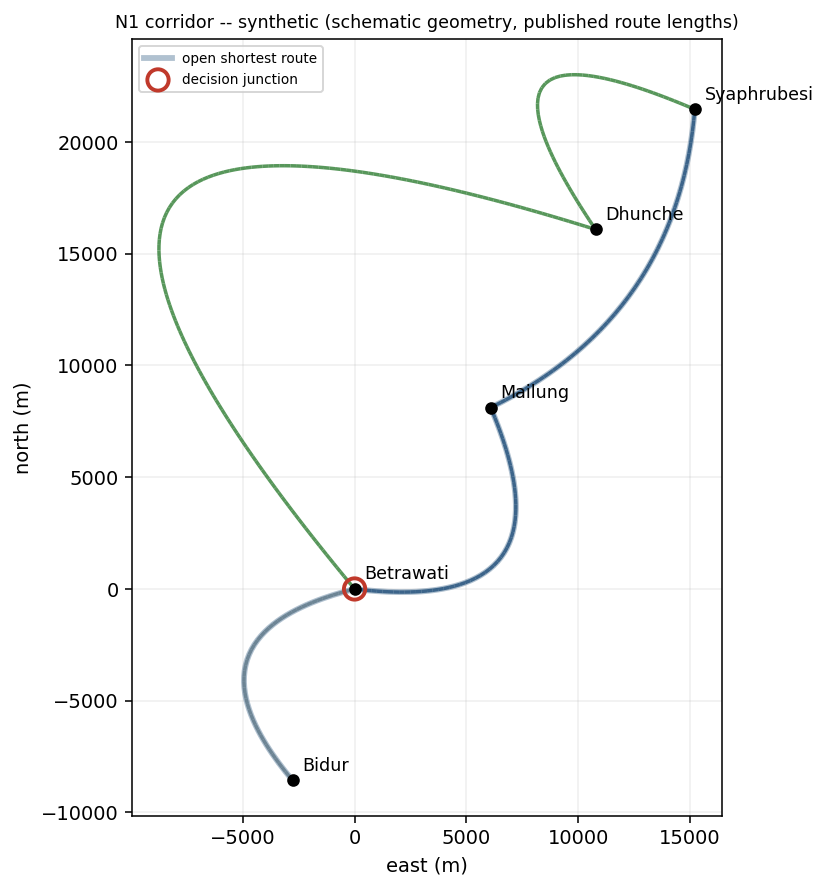

'/home/z/my-project/eptask_run/results/figures/corridor_map.png'

In [20]:
import datasets as DS, corridor as CO
DATA = DS.load_corridor_data(RESULTS, fetch=FETCH_REAL_DATA)
print("DATA MODE:", DATA["mode"])
for k, v in DATA["provenance"].items():
    print(f"  {k:6}: " + ", ".join(f"{kk}={vv}" for kk, vv in v.items()
          if kk in ("status", "source", "endpoint", "fetched", "n_ways", "n_features", "osm_base", "sha256")))
    if v.get("errors"):
        print("          errors:", v["errors"][:2])
print("places:")
for n, p in DATA["places"].items():
    print(f"  {n:12} {p['lat']:.5f}, {p['lon']:.5f}   ({p['source']})")
G, CORRIDOR_INFO = CO.build_corridor(DATA)
COOLR_XY = CO.coolr_xy(G, DATA["coolr_points"])
print()
print(CO.describe(G, CORRIDOR_INFO))
show(CO.plot_map(G, FIGDIR, coolr=COOLR_XY))

## 4 · Device and time budget

Two real training episodes of the disaster-aware configuration, then a projection. Read it
before a FULL run. Per-episode cost varies a lot between machines.

In [21]:
from train import train
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
t0 = time.time()
with cfg.override(DISASTER_MODE=True, STATE_MODE=33, RANDOM_DISASTERS=True):
    _a, _h = train(cfg, DEVICE, n_episodes=2, vehicle_counts=(10, 30, 50), log_every=1,
                   track_baselines_every=99)
per_ep = (time.time() - t0) / 2
print(f"\n{per_ep:.1f} s/episode on {DEVICE}  ->  model A ({B['ep_A']} ep) ~ {per_ep * B['ep_A'] / 60:.0f} min,"
      f"  model B ({B['ep_B']} ep) ~ {per_ep * B['ep_B'] / 60:.0f} min")

ep    1/2 | return   664.0   103.4  -879.0 | T   5.37s | KL +0.0156 clip 0.25 |   0.1m  eta   0.1m


ep    2/2 | return   668.0    90.8  -887.0 | T   5.27s | KL +0.0113 clip 0.20 |   0.1m  eta   0.0m

4.3 s/episode on cpu  ->  model A (1000 ep) ~ 72 min,  model B (1200 ep) ~ 86 min


## 5 · Training: model A (static) and model B (DR-MEPPO)

Both are trained in the same corrected environment: both V7 fixes on, paper-faithful FIFO
transmission. They differ only in what the disaster-aware design adds.

| | A — static (replication-style) | B — DR-MEPPO |
|---|---|---|
| world during training | Table III, static | random disaster events: 1–4 contiguous RSUs down for 5–15 min |
| state | 29-dim (Eq. 26) | 33-dim: + edge reachable, V2V reachable, protected, CWP/9 |
| reward | local_ratio (v5 fix) | local_ratio − value-weighted deadline-miss penalty |

Model A is the control. A gap between B and A at evaluation is what the disaster-aware design
buys.

In [22]:
A_KW = dict(DISASTER_MODE=False, STATE_MODE=29)
A_COUNTS = tuple(cfg.VEHICLE_COUNTS) if RUN_REPLICATION_FIGS else (10, 30, 50)
CKPT_A = os.path.join(RESULTS, "checkpoints", "meppo_A_static.pt")
with cfg.override(**A_KW):
    agentA, histA = train(cfg, DEVICE, n_episodes=B["ep_A"], vehicle_counts=A_COUNTS,
                          checkpoint_path=CKPT_A, checkpoint_every=25, cfg_kw=A_KW,
                          log_every=max(1, B["ep_A"] // 10))
g = A_COUNTS.index(30)
R_, T_ = np.asarray(histA["return"])[:, g], np.asarray(histA["T"])[:, g]
CORR_A = float(np.corrcoef(R_, -T_)[0, 1]) if len(R_) > 2 else float("nan")
print(f"\nmodel A: corr(reward, -T) at V=30 = {CORR_A:+.3f}  "
      "(must be strongly positive in FULL; meaningless with a handful of QUICK episodes)")

ep    1/1000 | return   862.3   308.6  -641.3 | T   5.33s | KL +0.0158 clip 0.23 |   0.1m  eta  63.9m


ep  100/1000 | return  1595.8   875.7   509.7 | T   2.61s | KL +0.0253 clip 0.47 |   6.7m  eta  59.9m


ep  200/1000 | return  1638.8   933.5   565.3 | T   2.50s | KL +0.0366 clip 0.48 |  13.1m  eta  52.4m


ep  300/1000 | return  1583.1   940.2   569.3 | T   2.56s | KL +0.0248 clip 0.49 |  19.4m  eta  45.4m


ep  400/1000 | return  1605.1   948.3   577.1 | T   2.49s | KL +0.0308 clip 0.50 |  26.0m  eta  38.9m


...

ep  600/1000 | return  1628.8   952.4   564.0 | T   2.49s | KL +0.0340 clip 0.52 |  38.9m  eta  25.9m


ep  700/1000 | return  1621.1   927.1   579.5 | T   2.45s | KL +0.0337 clip 0.52 |  45.3m  eta  19.4m


ep  800/1000 | return  1642.4   944.9   594.3 | T   2.44s | KL +0.0323 clip 0.52 |  51.9m  eta  13.0m


ep  900/1000 | return  1604.7   957.2   583.1 | T   2.49s | KL +0.0323 clip 0.51 |  58.3m  eta   6.5m


ep 1000/1000 | return  1624.0   959.1   585.9 | T   2.42s | KL +0.0331 clip 0.53 |  64.6m  eta   0.0m

model A: corr(reward, -T) at V=30 = +0.958  (must be strongly positive in FULL; meaningless with a handful of QUICK episodes)


In [23]:
B_KW = dict(DISASTER_MODE=True, STATE_MODE=33, RANDOM_DISASTERS=True, DISASTER_REWARD=True)
B_COUNTS = (10, 30, 50)
CKPT_B = os.path.join(RESULTS, "checkpoints", "meppo_B_dr.pt")
with cfg.override(**B_KW):
    agentB, histB = train(cfg, DEVICE, n_episodes=B["ep_B"], vehicle_counts=B_COUNTS,
                          checkpoint_path=CKPT_B, checkpoint_every=25, cfg_kw=B_KW,
                          log_every=max(1, B["ep_B"] // 10))
pm = np.asarray(histB["prot_miss"])
k = max(1, len(pm) // 10)
print("\nmodel B: protected-class deadline miss % (first vs last tenth of training) per V "
      f"{B_COUNTS}:", np.round(pm[:k].mean(0), 1).tolist(), "->", np.round(pm[-k:].mean(0), 1).tolist())

ep    1/1200 | return   664.0   103.4  -879.0 | T   5.37s | KL +0.0156 clip 0.25 |   0.1m  eta  79.6m


ep  120/1200 | return  1273.8   582.8   186.7 | T   2.88s | KL +0.0231 clip 0.49 |   8.2m  eta  73.6m


ep  240/1200 | return  1286.5   593.1   256.0 | T   2.70s | KL +0.0186 clip 0.49 |  16.6m  eta  66.3m


ep  360/1200 | return  1303.5   675.0   267.9 | T   2.71s | KL +0.0161 clip 0.49 |  24.7m  eta  57.7m


ep  480/1200 | return  1207.8   739.5   275.7 | T   2.66s | KL +0.0184 clip 0.52 |  33.0m  eta  49.5m


...

ep  720/1200 | return  1343.9   657.3   293.2 | T   2.78s | KL +0.0337 clip 0.54 |  49.2m  eta  32.8m


ep  840/1200 | return  1336.7   665.3   255.4 | T   2.66s | KL +0.0203 clip 0.51 |  57.4m  eta  24.6m


ep  960/1200 | return  1287.8   661.3   225.7 | T   2.73s | KL +0.0219 clip 0.54 |  65.6m  eta  16.4m


ep 1080/1200 | return  1355.4   557.8   290.4 | T   2.67s | KL +0.0171 clip 0.51 |  73.7m  eta   8.2m


ep 1200/1200 | return  1252.0   653.6   266.0 | T   2.76s | KL +0.0131 clip 0.51 |  82.0m  eta   0.0m

model B: protected-class deadline miss % (first vs last tenth of training) per V (10, 30, 50): [30.8, 72.3, 86.7] -> [25.3, 64.4, 79.6]


### ONNX export, and proof that the exported files decide exactly like torch

The Streamlit demo runs the `.onnx` files. Each one has a JSON sidecar with its state encoding.
The check below feeds the *same* live states, during a disaster event, to both versions of
model B and counts disagreements.

In [24]:
import export_onnx as ONNX
from policies import TorchGroupPolicy, OnnxPolicy, RulePolicy, rollout
ONNX_DIR = os.path.join(RESULTS, "onnx")
ONNX_FILES = {}
for tag, ck, counts in (("A", CKPT_A, A_COUNTS), ("B", CKPT_B, B_COUNTS)):
    for V in counts:
        path = os.path.join(ONNX_DIR, f"meppo_{tag}_v{V}.onnx")
        info = ONNX.export_group(ck, group=V, out_path=path)
        ONNX.verify(ck, group=V, onnx_path=path)
        ONNX_FILES[f"{tag}_v{V}"] = path
        print(f"  {tag} V={V}: {info['size_bytes']} bytes via {info['exporter']}")

def facA(V, sd):
    return TorchGroupPolicy(agentA, A_COUNTS.index(V), DEVICE, A_KW, "model A (static)") if V in A_COUNTS else None
def facB(V, sd):
    return TorchGroupPolicy(agentB, B_COUNTS.index(V), DEVICE, B_KW, "model B (DR-MEPPO)") if V in B_COUNTS else None
facLocal = lambda V, sd: RulePolicy("local", sd)
facAlive = lambda V, sd: RulePolicy("alive_aware", sd)
facRand = lambda V, sd: RulePolicy("random", sd)

with cfg.override(DISASTER_MODE=True, STATE_MODE=33, RANDOM_DISASTERS=False):
    e = VECEnv(cfg, 30, seed=3); obs = e.observe(); e.trigger_disaster(2, 3, 400)
    pt, po, dis = facB(30, 0), OnnxPolicy(ONNX_FILES["B_v30"]), 0
    for _ in range(500):
        a1, a2 = pt.act(e, obs), po.act(e, obs)
        dis += int(not (np.array_equal(a1[0], a2[0]) and np.array_equal(a1[1], a2[1])))
        obs, _, _ = e.step(*a1)
CHECKS["onnx_vs_torch_disagreements_of_500"] = dis
print(f"[{'ok' if dis <= 5 else 'FAIL'}] ONNX vs torch decision disagreements on 500 live states: {dis}")
assert dis <= 5

verify: slice-vs-grouped max diff = 3.81e-06  (tolerance 1e-04)
verify: onnx-vs-pytorch max diff  = 3.81e-06  (tolerance 1e-04)
verify: PASSED
  A V=10: 62201 bytes via torchscript
verify: slice-vs-grouped max diff = 1.91e-06  (tolerance 1e-04)
verify: onnx-vs-pytorch max diff  = 3.81e-06  (tolerance 1e-04)
verify: PASSED
  A V=30: 62201 bytes via torchscript
verify: slice-vs-grouped max diff = 1.91e-06  (tolerance 1e-04)
verify: onnx-vs-pytorch max diff  = 2.86e-06  (tolerance 1e-04)
verify: PASSED
  A V=50: 62201 bytes via torchscript
verify: slice-vs-grouped max diff = 9.54e-07  (tolerance 1e-04)
verify: onnx-vs-pytorch max diff  = 8.34e-07  (tolerance 1e-04)
verify: PASSED
  B V=10: 63225 bytes via torchscript


verify: slice-vs-grouped max diff = 1.91e-06  (tolerance 1e-04)
verify: onnx-vs-pytorch max diff  = 2.38e-06  (tolerance 1e-04)
verify: PASSED
  B V=30: 63225 bytes via torchscript


verify: slice-vs-grouped max diff = 1.91e-06  (tolerance 1e-04)
verify: onnx-vs-pytorch max diff  = 2.86e-06  (tolerance 1e-04)
verify: PASSED
  B V=50: 63225 bytes via torchscript


[ok] ONNX vs torch decision disagreements on 500 live states: 0


## 6 · Optional — v6.1 replication figures

These are skipped unless `RUN_REPLICATION_FIGS = True`. They re-run v6.1's Figs 7–12 and
diagnostics D1–D5 with model A, which is then trained on all five vehicle counts. Each figure
is guarded, so a failure here cannot stop the V7.1 sections.

In [25]:
if RUN_REPLICATION_FIGS:
    import experiments as X, diagnostics as DG
    with cfg.override(**A_KW):
        for label, fn in (("Fig 7", lambda: X.fig7_vehicle_distribution(cfg, FIGDIR, num_vehicles=30)),
                          ("Fig 8", lambda: X.fig8_task_distribution(cfg, FIGDIR)),
                          ("Fig 9", lambda: X.fig9_convergence(histA, FIGDIR)),
                          ("Fig 10", lambda: X.fig10_method_comparison(cfg, agentA, FIGDIR, DEVICE, eval_steps=1500)),
                          ("Fig 11", lambda: X.fig11_priority_ablation(cfg, agentA, FIGDIR, DEVICE, eval_steps=1500)),
                          ("Fig 12", lambda: X.fig12_power_ablation(cfg, FIGDIR, eval_steps=1500)),
                          ("D1", lambda: DG.d1_reward_degeneracy(cfg, FIGDIR)),
                          ("D3", lambda: DG.d3_true_vs_reported(cfg, FIGDIR)),
                          ("D4", lambda: DG.d4_critical_path(cfg, FIGDIR)),
                          ("D5", lambda: DG.d5_priority_rules(cfg, FIGDIR))):
            try:
                out = fn(); print(f"[ok] {label}:", out[0] if isinstance(out, tuple) else out)
            except Exception as exc:
                print(f"[skipped] {label}: {exc!r}")
else:
    print("RUN_REPLICATION_FIGS = False -- skipped (v6.1 results remain valid; see the v6.1 notebook)")

RUN_REPLICATION_FIGS = False -- skipped (v6.1 results remain valid; see the v6.1 notebook)


## 7 · C1 — safety-integrity floor, measured properly

* **(a)** v6.1's own single-seed C1, reproduced with every V7.1 switch off, for continuity.
* **(b)** Three arms (floor OFF / ON with level 9 shared / ON with level 9 reserved) over several
  seeds. The policy here is random, so the arms are *exactly* paired and the gain is the floor
  alone.
* **(c)** The same three arms with trained model A.
* **(d)** A diagnostic explaining the result: how often a vehicle's uplink is still busy when it
  issues its next request.

**Expected, and worth reporting.** If "shared" and "reserved" come out nearly identical, that is
the replication's central finding again. A request's tasks are already enqueued in rank order,
and a vehicle's uplink has almost always drained by its next request (see (d)). So level-9
contention rarely binds, and the floor acts mainly through the shared *execution* queues.

C1 (v6.1 single-seed)  ASIL-D protection: floor ON vs OFF (random priority)
      V  floor  ASIL-D true T  ASIL-D miss%  QM miss% (ref)


     10   True          2.528          17.5             0.2


     10  False          2.560          18.8             0.2


     20   True          3.096          32.3             1.2


     20  False          3.205          34.7             1.2


...

    V=40  floor ON, v6.1 (level 9 shared)    T 6.357 +- 0.564s (n=5)      miss 92.3 +- 2.1% (n=5)       QM miss 18.5 +- 1.0% (n=5)


    V=40  floor ON, V7.1 (level 9 reserved)  T 6.357 +- 0.564s (n=5)      miss 92.3 +- 2.0% (n=5)       QM miss 18.5 +- 1.0% (n=5)


    V=50  floor OFF                          T 9.818 +- 0.808s (n=5)      miss 96.4 +- 1.5% (n=5)       QM miss 30.6 +- 1.1% (n=5)


    V=50  floor ON, v6.1 (level 9 shared)    T 9.369 +- 0.738s (n=5)      miss 96.3 +- 1.4% (n=5)       QM miss 30.7 +- 1.1% (n=5)


    V=50  floor ON, V7.1 (level 9 reserved)  T 9.369 +- 0.738s (n=5)      miss 96.3 +- 1.4% (n=5)       QM miss 30.7 +- 1.0% (n=5)
    paired gain vs floor OFF (per seed, then averaged):
      floor ON, v6.1 (level 9 shared)    T gain % V10:2.3 +- 1.9 (n=5)  V20:3.1 +- 1.0 (n=5)  V30:4.3 +- 0.9 (n=5)  V40:4.3 +- 0.5 (n=5)  V50:4.6 +- 0.8 (n=5)
                                         miss -pp  V10:1.1 +- 0.7 (n=5)  V20:0.8 +- 0.8 (n=5)  V30:0.8 +- 0.6 (n=5)  V40:0.3 +- 0.3 (n=5)  V50:0.1 +- 0.2 (n=5)
      floor ON, V7.1 (level 9 reserved)  T gain % V10:2.3 +- 1.9 (n=5)  V20:3.1 +- 1.0 (n=5)  V30:4.4 +- 0.9 (n=5)  V40:4.3 +- 0.5 (n=5)  V50:4.6 +- 0.8 (n=5)
                                         miss -pp  V10:1.1 +- 0.7 (n=5)  V20:0.8 +- 0.8 (n=5)  V30:0.9 +- 0.5 (n=5)  V40:0.4 +- 0.2 (n=5)  V50:0.1 +- 0.2 (n=5)


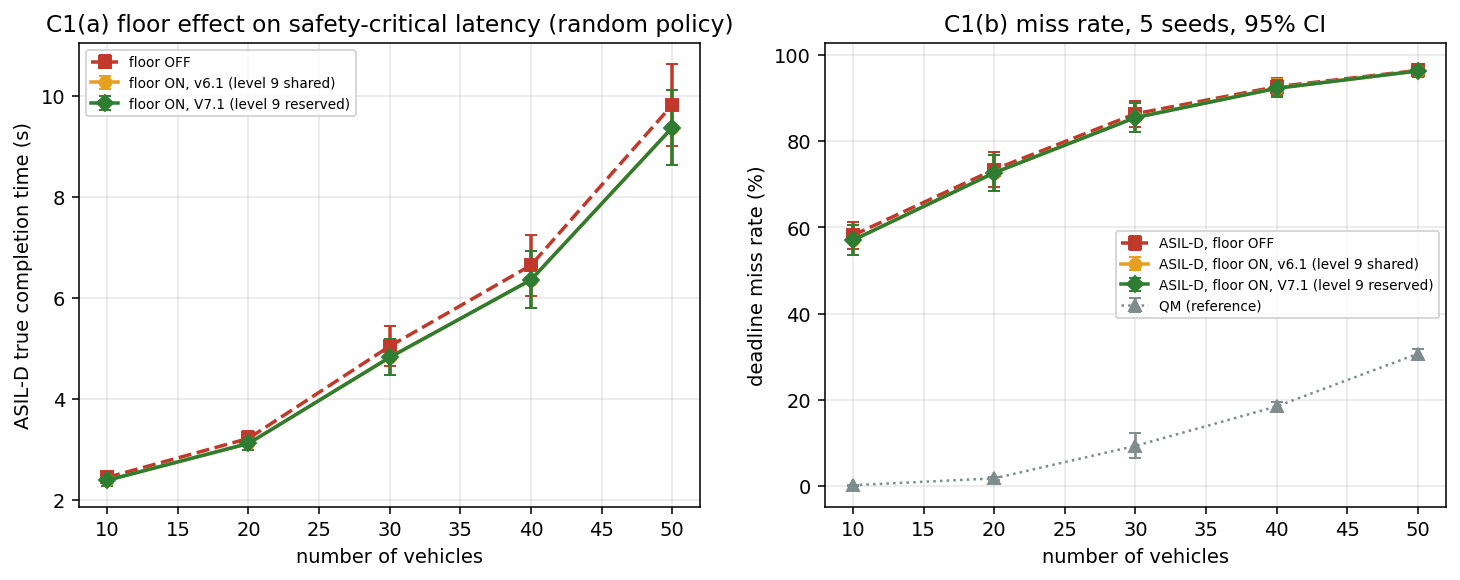

C1  ASIL-D protection, 5 seeds x 4000 steps, trained model A  (mean +- 95% CI)


    V=10  floor OFF                          T 1.323 +- 0.151s (n=5)      miss 20.4 +- 4.1% (n=5)       QM miss 0.0 +- 0.0% (n=5)


    V=10  floor ON, v6.1 (level 9 shared)    T 1.229 +- 0.138s (n=5)      miss 18.0 +- 3.7% (n=5)       QM miss 0.0 +- 0.0% (n=5)


    V=10  floor ON, V7.1 (level 9 reserved)  T 1.229 +- 0.138s (n=5)      miss 18.0 +- 3.7% (n=5)       QM miss 0.0 +- 0.0% (n=5)


    V=30  floor OFF                          T 2.656 +- 0.017s (n=5)      miss 65.9 +- 4.1% (n=5)       QM miss 0.0 +- 0.0% (n=5)


    V=30  floor ON, v6.1 (level 9 shared)    T 2.558 +- 0.034s (n=5)      miss 63.1 +- 3.8% (n=5)       QM miss 0.0 +- 0.0% (n=5)


    V=30  floor ON, V7.1 (level 9 reserved)  T 2.558 +- 0.034s (n=5)      miss 63.1 +- 3.8% (n=5)       QM miss 0.0 +- 0.0% (n=5)


    V=50  floor OFF                          T 2.986 +- 0.200s (n=5)      miss 83.5 +- 3.0% (n=5)       QM miss 0.0 +- 0.0% (n=5)


    V=50  floor ON, v6.1 (level 9 shared)    T 2.922 +- 0.186s (n=5)      miss 82.7 +- 2.7% (n=5)       QM miss 0.0 +- 0.0% (n=5)


    V=50  floor ON, V7.1 (level 9 reserved)  T 2.922 +- 0.186s (n=5)      miss 82.7 +- 2.7% (n=5)       QM miss 0.0 +- 0.0% (n=5)
    paired gain vs floor OFF (per seed, then averaged):
      floor ON, v6.1 (level 9 shared)    T gain % V10:7.1 +- 0.7 (n=5)  V30:3.7 +- 0.8 (n=5)  V50:2.1 +- 0.6 (n=5)
                                         miss -pp  V10:2.5 +- 1.4 (n=5)  V30:2.8 +- 0.8 (n=5)  V50:0.8 +- 0.4 (n=5)
      floor ON, V7.1 (level 9 reserved)  T gain % V10:7.1 +- 0.7 (n=5)  V30:3.7 +- 0.8 (n=5)  V50:2.1 +- 0.6 (n=5)
                                         miss -pp  V10:2.5 +- 1.4 (n=5)  V30:2.8 +- 0.8 (n=5)  V50:0.8 +- 0.4 (n=5)


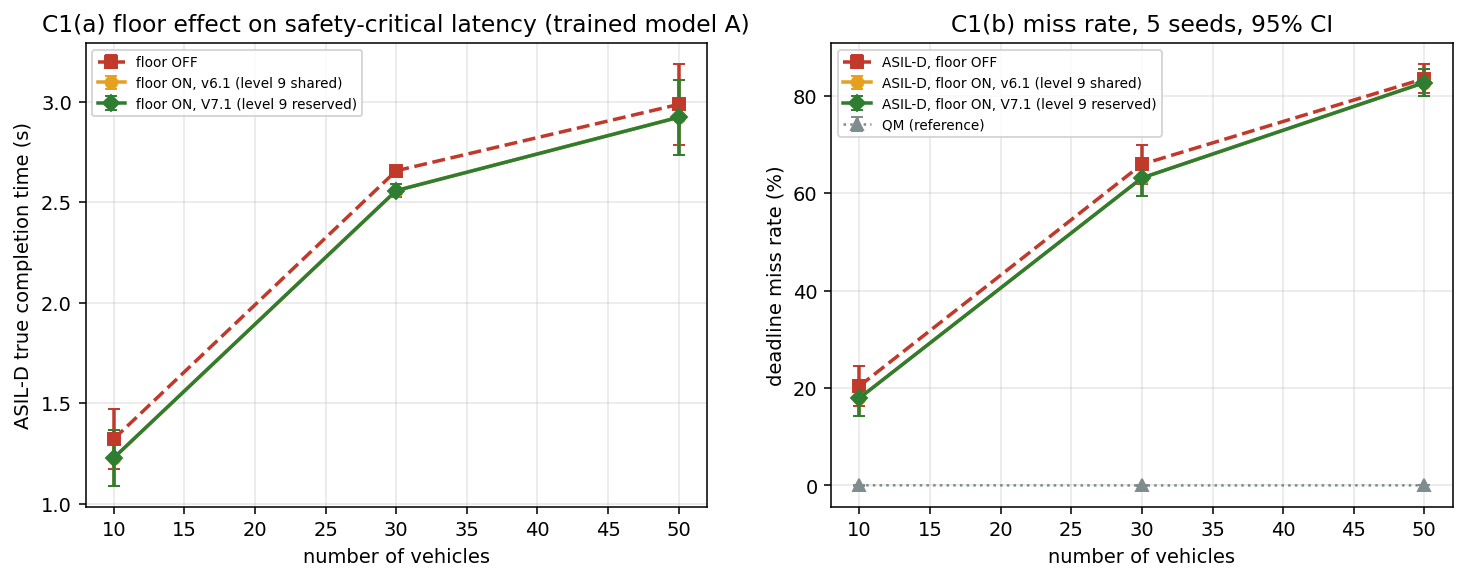

Uplink still busy when a vehicle issues its next request (random policy): V=10: 0.2%, V=20: 0.1%, V=30: 0.6%, V=40: 0.9%, V=50: 1.5%


In [26]:
import contributions as CT
with cfg.override(RESERVE_TOP_LEVEL=False, LOCAL_COST_AT_ARRIVAL=False, PRIORITY_TX=False, DISASTER_MODE=False):
    C1_V61 = CT.c1_safety_floor(cfg, FIGDIR, steps=B["c1_steps"], seed=5)
print()
p, C1_RAND = CT.c1_multiseed(cfg, FIGDIR, seeds=B["seeds"], steps=B["c1_steps"], counts=B["c1_counts"],
                             label="random policy", fname="c1_random.png"); show(p)
p, C1_A = CT.c1_multiseed(cfg, FIGDIR, seeds=B["seeds"], steps=B["c1_steps"],
                          counts=[V for V in B["c1_counts"] if V in A_COUNTS], policy_factory=facA,
                          label="trained model A", fname="c1_modelA.png"); show(p)
UPLINK = CT.uplink_busy_share(cfg, counts=B["c1_counts"], steps=B["c1_steps"])

## 8 · C2 — explaining individual decisions

* A calm decision by model A.
* The decision N1 is about. A 3-RSU block is down, and model B must place an *emergency*
  vehicle's request from **inside the dead zone**, where the edge is unreachable. Is V2V,
  Local or a doomed edge/cloud attempt the better target? The counterfactual bars give the
  exact answer via `env.peek()`.

C2  [calm] policy=model A (static)  t=200s  V=30  role=NORMAL  class=QM  protected=False  edge reachable=True  V2V reachable=True  tasks=3  critic value=46.65
     task        offload ->   conf  entropy  priority   conf  entropy
        0             Cloud   0.52     1.00         1   0.22     2.15
        1             Cloud   0.70     0.90         4   0.23     2.08
        2             Cloud   0.75     0.57         0   0.26     2.01
    counterfactual for task 1 (largest task):
            Edge server: T =   0.774s   E = 0.00019J
         Nearby vehicle: T =   0.560s   E = 0.00372J
       Local (on-board): T =   0.513s   E = 0.00369J
                  Cloud: T =   0.841s   E = 0.00019J


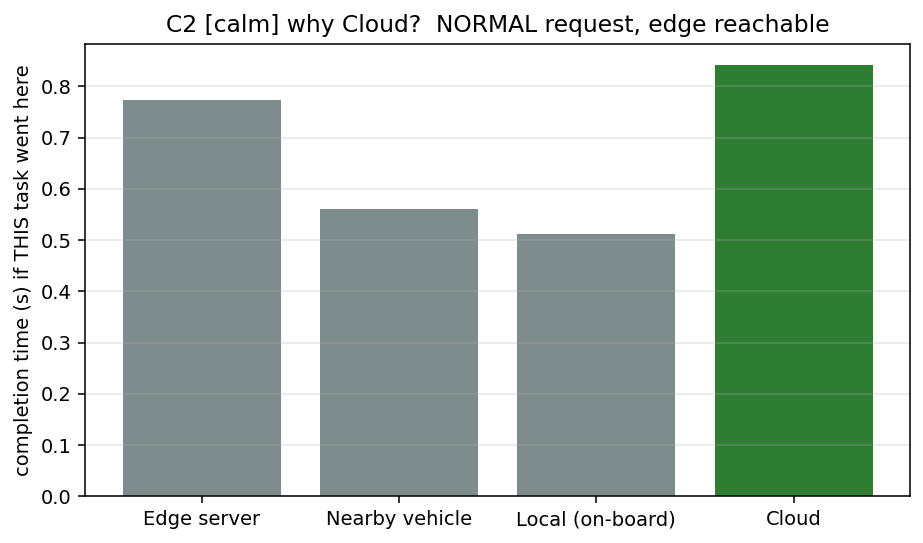

C2  [emergency_dead_zone] policy=model B (DR-MEPPO)  t=441s  V=30  role=EMERGENCY  class=EMERGENCY  protected=True  edge reachable=False  V2V reachable=False  tasks=5  critic value=29.28
     task        offload ->   conf  entropy  priority   conf  entropy
        0    Nearby vehicle   0.54     0.80         3   0.21     2.11
        1    Nearby vehicle   0.37     1.29         6   0.49     1.77
        2  Local (on-board)   0.50     1.16         9   0.21     2.09
        3             Cloud   0.66     0.86         9   0.17     2.19
        4    Nearby vehicle   0.40     1.15         6   0.36     2.02
    counterfactual for task 3 (largest task):
            Edge server: T =   5.379s   E = 0.05379J
         Nearby vehicle: T =   5.379s   E = 0.05379J
       Local (on-board): T =   5.379s   E = 0.05379J
                  Cloud: T =   5.379s   E = 0.05379J


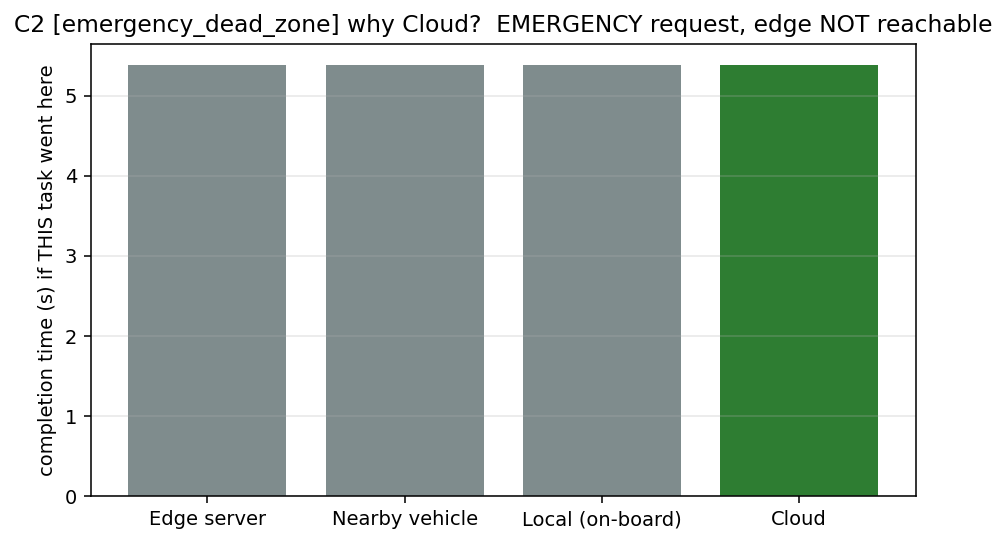

'/home/z/my-project/eptask_run/results/figures/c2_emergency_dead_zone.png'

In [27]:
p, C2_CALM = CT.c2_explain_live(cfg, facA(30, 0), FIGDIR, V=30, warmup=200, scenario="calm"); show(p)
p, C2_DEAD = CT.c2_explain_live(cfg, facB(30, 0), FIGDIR, V=30, warmup=200,
                                scenario="emergency_dead_zone"); show(p)

## 9 · C3 — node failure with a paired no-failure control

For every (k RSUs down, policy, seed) the same world is run twice: once with the outage and
once without. The request stream is identical by construction, so the difference is the
outage's own effect. Local-only must read exactly 0 %, and that acts as a built-in validity
check. A **negative** excess is possible and meaningful: losing congested RSUs can push work
to a faster local or V2V placement.

C3  paired outage test, V=30, outage [1200, 1600) s, 5 seeds (excess vs the SAME run without the outage)


    k=1 RSU(s) model A (static) excess during 7.7 +- 2.3% (n=5)        after 0.0 +- 0.0% (n=5)        T in outage 2.68 +- 0.15s (n=5)


    k=1 RSU(s) model B (DR-MEPPO) excess during 5.5 +- 2.1% (n=5)        after 0.0 +- 0.0% (n=5)        T in outage 2.78 +- 0.15s (n=5)


    k=1 RSU(s) alive-aware rule excess during 0.2 +- 4.2% (n=5)        after -0.0 +- 0.1% (n=5)       T in outage 7.55 +- 0.55s (n=5)


    k=1 RSU(s) Local-only     excess during 0.0 +- 0.0% (n=5)        after 0.0 +- 0.0% (n=5)        T in outage 4.39 +- 0.15s (n=5)


...

    k=2 RSU(s) Local-only     excess during 0.0 +- 0.0% (n=5)        after 0.0 +- 0.0% (n=5)        T in outage 4.39 +- 0.15s (n=5)


    k=4 RSU(s) model A (static) excess during 34.2 +- 5.1% (n=5)       after 0.0 +- 0.0% (n=5)        T in outage 3.34 +- 0.12s (n=5)


    k=4 RSU(s) model B (DR-MEPPO) excess during 20.2 +- 2.8% (n=5)       after 0.0 +- 0.0% (n=5)        T in outage 3.17 +- 0.17s (n=5)


    k=4 RSU(s) alive-aware rule excess during -12.1 +- 5.1% (n=5)      after -0.1 +- 0.3% (n=5)       T in outage 6.62 +- 0.53s (n=5)


    k=4 RSU(s) Local-only     excess during 0.0 +- 0.0% (n=5)        after 0.0 +- 0.0% (n=5)        T in outage 4.39 +- 0.15s (n=5)


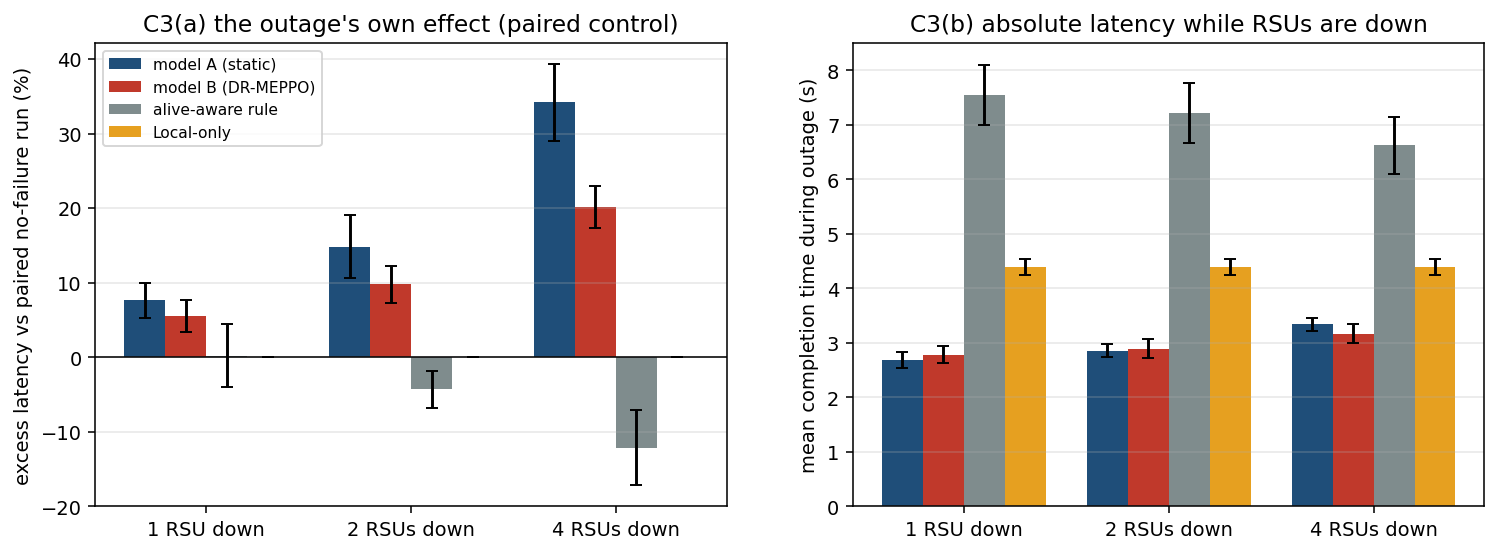

[ok] validity: Local-only excess is exactly 0 for every k


In [28]:
p, C3 = CT.c3_paired(cfg, {"model A (static)": facA, "model B (DR-MEPPO)": facB,
                           "alive-aware rule": facAlive, "Local-only": facLocal},
                     FIGDIR, V=30, k_list=(1, 2, 4), seeds=B["seeds"], **B["c3"]); show(p)
loc = [r["during_pct"][0] for key, r in C3["rows"].items() if r["policy"] == "Local-only"]
assert all(abs(x) < 1e-9 for x in loc), "pairing broken: Local-only must be failure-proof"
print("[ok] validity: Local-only excess is exactly 0 for every k")

## 10 · N1 — emergency vehicles inside the VEC cell

During a 3-RSU outage the figure shows four things:

* the EMERGENCY-class deadline miss rate and latency, for model A, model B and the alive-aware
  rule, each with the emergency floor OFF and ON;
* the cost to ordinary QM traffic;
* the share of work moved to V2V, which shows whether the policy uses its neighbours when the
  infrastructure dies.

The emergency deadline is 0.5 × the request's own Local-only time (C1's ASIL-D convention), a
strict target. Compare arms, not the absolute level.

N1  emergency requests during a 3-RSU outage [600, 1800) s (RSUs 2..4), 5 seeds


    V=10 model A (static) | floor OFF       EMERGENCY miss 50.6 +- 4.8% (n=5)     T 2.44 +- 0.24s (n=5)    QM miss 0.1 +- 0.1% (n=5)      V2V share 0.5 +- 0.1% (n=5)


    V=30 model A (static) | floor OFF       EMERGENCY miss 81.4 +- 8.8% (n=5)     T 3.44 +- 0.27s (n=5)    QM miss 0.0 +- 0.1% (n=5)      V2V share 10.1 +- 1.8% (n=5)


    V=50 model A (static) | floor OFF       EMERGENCY miss 90.9 +- 1.8% (n=5)     T 3.40 +- 0.38s (n=5)    QM miss 0.1 +- 0.1% (n=5)      V2V share 22.3 +- 1.2% (n=5)


    V=10 model A (static) | floor ON        EMERGENCY miss 49.9 +- 4.1% (n=5)     T 2.39 +- 0.24s (n=5)    QM miss 0.1 +- 0.1% (n=5)      V2V share 0.5 +- 0.1% (n=5)


...

    V=30 alive-aware rule | floor OFF       EMERGENCY miss 97.6 +- 4.1% (n=5)     T 10.11 +- 2.04s (n=5)   QM miss 27.6 +- 2.8% (n=5)     V2V share 21.4 +- 3.8% (n=5)


    V=50 alive-aware rule | floor OFF       EMERGENCY miss 100.0 +- 0.0% (n=5)    T 18.80 +- 2.77s (n=5)   QM miss 50.9 +- 4.9% (n=5)     V2V share 27.2 +- 2.9% (n=5)


    V=10 alive-aware rule | floor ON        EMERGENCY miss 75.0 +- 6.1% (n=5)     T 3.26 +- 0.22s (n=5)    QM miss 4.0 +- 1.5% (n=5)      V2V share 9.9 +- 1.6% (n=5)


    V=30 alive-aware rule | floor ON        EMERGENCY miss 96.8 +- 4.8% (n=5)     T 7.86 +- 1.02s (n=5)    QM miss 27.6 +- 2.8% (n=5)     V2V share 21.4 +- 3.8% (n=5)


    V=50 alive-aware rule | floor ON        EMERGENCY miss 100.0 +- 0.0% (n=5)    T 14.63 +- 2.60s (n=5)   QM miss 51.0 +- 4.9% (n=5)     V2V share 27.2 +- 2.9% (n=5)


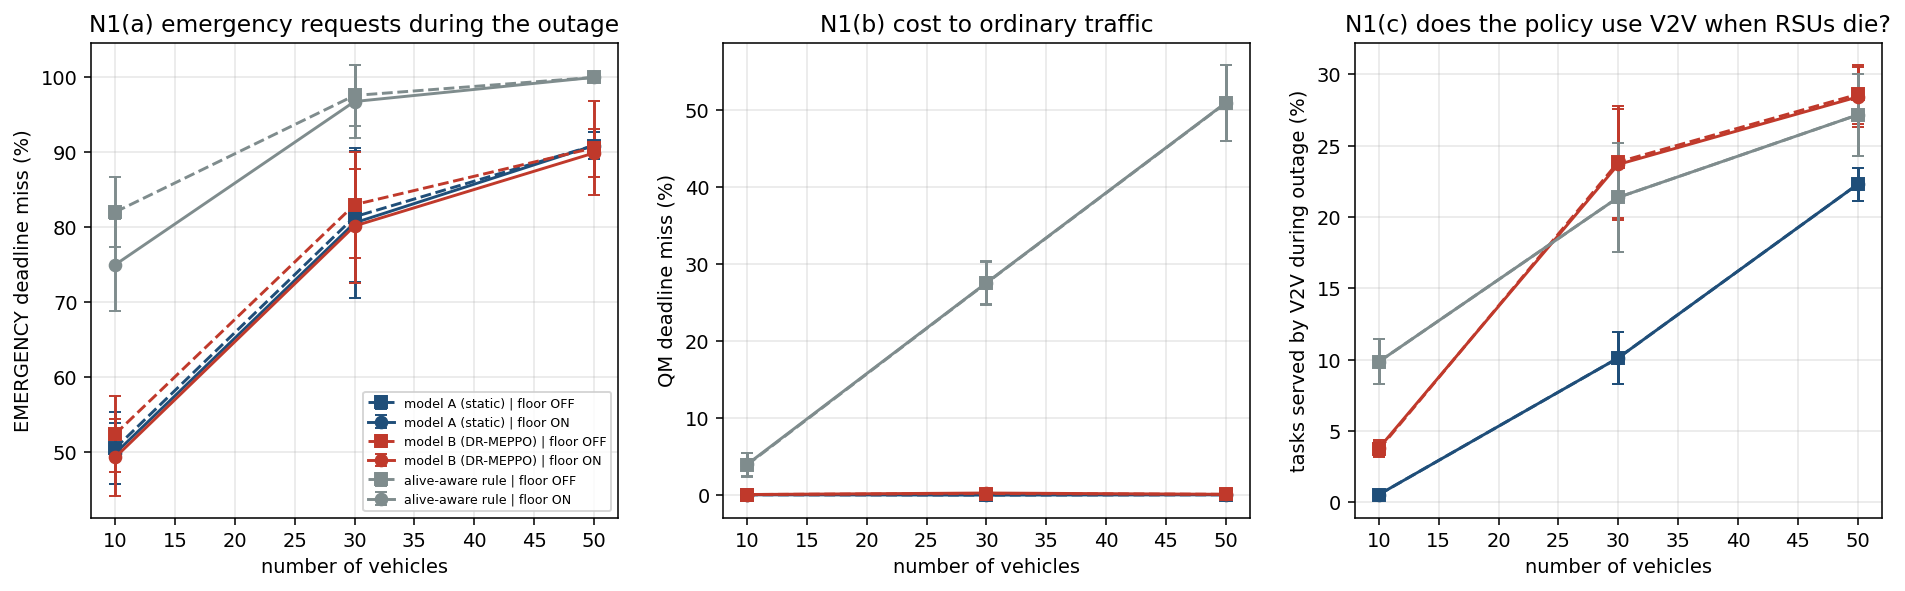

'/home/z/my-project/eptask_run/results/figures/n1_emergency.png'

In [29]:
import novelties as NV
EV = B["event"]
p, N1 = NV.n1_emergency(cfg, {"model A (static)": facA, "model B (DR-MEPPO)": facB,
                              "alive-aware rule": facAlive},
                        FIGDIR, counts=B["n1_counts"], seeds=B["seeds"], **EV); show(p)

## 11 · N2 — casualty-weighted priority

The arms are CWP off, the CWP floor, and the CWP floor with the original time decay. All three
are scored on **ground truth**: a value-weighted on-time rate (weight = log(1 + *true*
people)) and the on-time rate for groups of four or more. The sensor's estimate carries
modality-dependent noise, so the scheduler sees estimates while the score uses the truth.

The dilution sweep shows the limit of the mechanism. As more and more traffic is protected,
the protected class's miss rate rises toward the unprotected one. A floor helps only a rare
subset.

N2  victim detections during a 3-RSU outage, V=30, 5 seeds, model B


    CWP off              value-weighted on-time 81.1 +- 3.7% (n=5)     large groups (>=4) on-time 82.7 +- 5.5% (n=5)     protected share 11.8 +- 0.8% (n=5)   QM miss 0.3 +- 0.3% (n=5)


    CWP floor            value-weighted on-time 81.4 +- 4.6% (n=5)     large groups (>=4) on-time 82.6 +- 6.0% (n=5)     protected share 14.9 +- 0.8% (n=5)   QM miss 0.3 +- 0.3% (n=5)


    CWP floor + decay    value-weighted on-time 81.5 +- 3.9% (n=5)     large groups (>=4) on-time 82.6 +- 5.4% (n=5)     protected share 14.6 +- 0.9% (n=5)   QM miss 0.3 +- 0.3% (n=5)


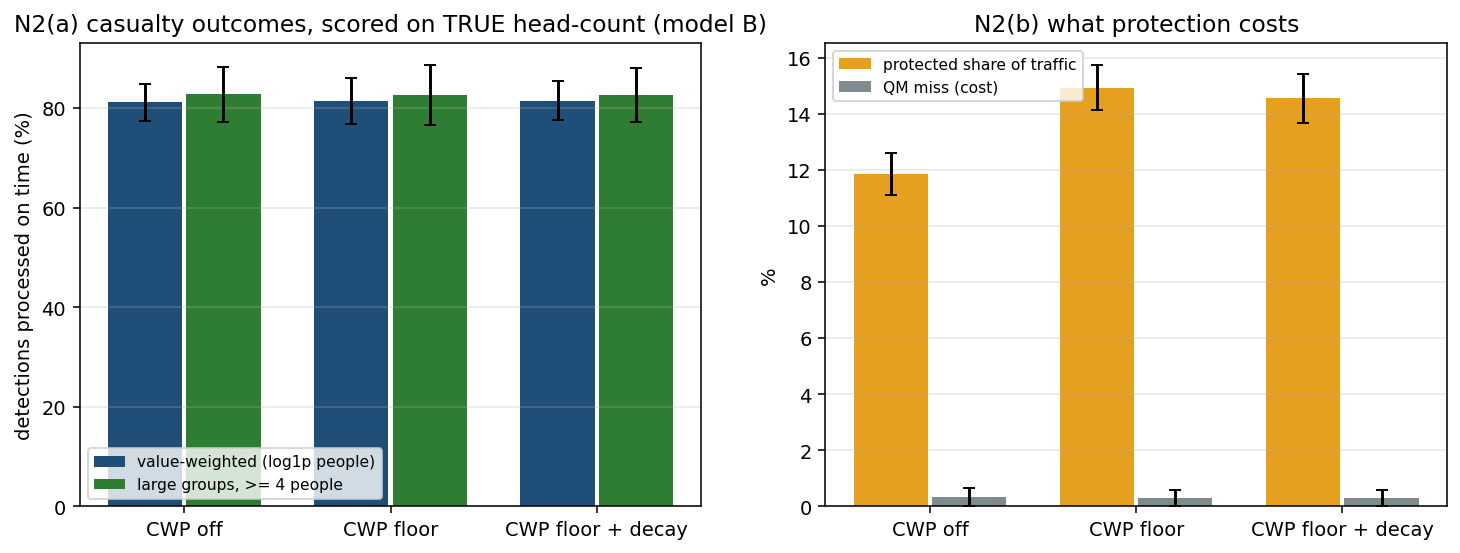

N2  victim detections during a 3-RSU outage, V=30, 5 seeds, random policy


    CWP off              value-weighted on-time 60.9 +- 3.5% (n=5)     large groups (>=4) on-time 61.0 +- 5.7% (n=5)     protected share 11.8 +- 0.8% (n=5)   QM miss 6.7 +- 1.1% (n=5)


    CWP floor            value-weighted on-time 60.9 +- 3.6% (n=5)     large groups (>=4) on-time 61.0 +- 5.7% (n=5)     protected share 14.9 +- 0.8% (n=5)   QM miss 6.7 +- 1.1% (n=5)


    CWP floor + decay    value-weighted on-time 60.9 +- 3.6% (n=5)     large groups (>=4) on-time 61.0 +- 5.7% (n=5)     protected share 14.6 +- 0.9% (n=5)   QM miss 6.7 +- 1.1% (n=5)


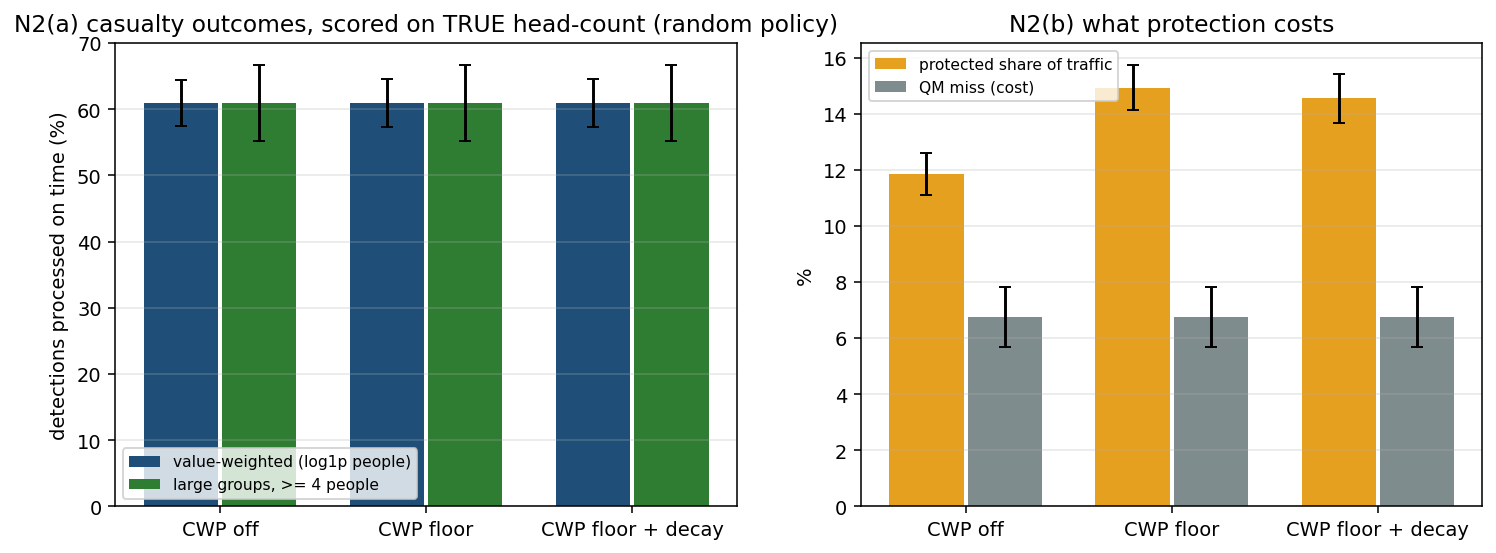

Floor dilution: widen the floor and watch the always-protected core (ASIL-D + EMERGENCY), V=30, random policy, 5 seeds


    IMMEDIATE threshold  9.5: floor covers 11.8 +- 0.8% (n=5)     core T 4.83 +- 0.89s (n=5)    core miss 91.5 +- 5.1% (n=5)     QM miss 6.6 +- 2.4% (n=5)


    IMMEDIATE threshold  7.5: floor covers 13.1 +- 0.3% (n=5)     core T 4.83 +- 0.89s (n=5)    core miss 91.5 +- 5.1% (n=5)     QM miss 6.6 +- 2.4% (n=5)


    IMMEDIATE threshold  6.0: floor covers 14.3 +- 0.4% (n=5)     core T 4.83 +- 0.89s (n=5)    core miss 91.5 +- 5.1% (n=5)     QM miss 6.6 +- 2.4% (n=5)


    IMMEDIATE threshold  4.5: floor covers 17.9 +- 0.7% (n=5)     core T 4.83 +- 0.89s (n=5)    core miss 91.5 +- 5.1% (n=5)     QM miss 6.6 +- 2.4% (n=5)


    IMMEDIATE threshold  3.0: floor covers 28.5 +- 0.4% (n=5)     core T 4.83 +- 0.89s (n=5)    core miss 91.5 +- 5.1% (n=5)     QM miss 6.6 +- 2.4% (n=5)


    IMMEDIATE threshold  0.0: floor covers 55.5 +- 1.2% (n=5)     core T 4.83 +- 0.89s (n=5)    core miss 91.5 +- 5.1% (n=5)     QM miss 6.7 +- 2.3% (n=5)


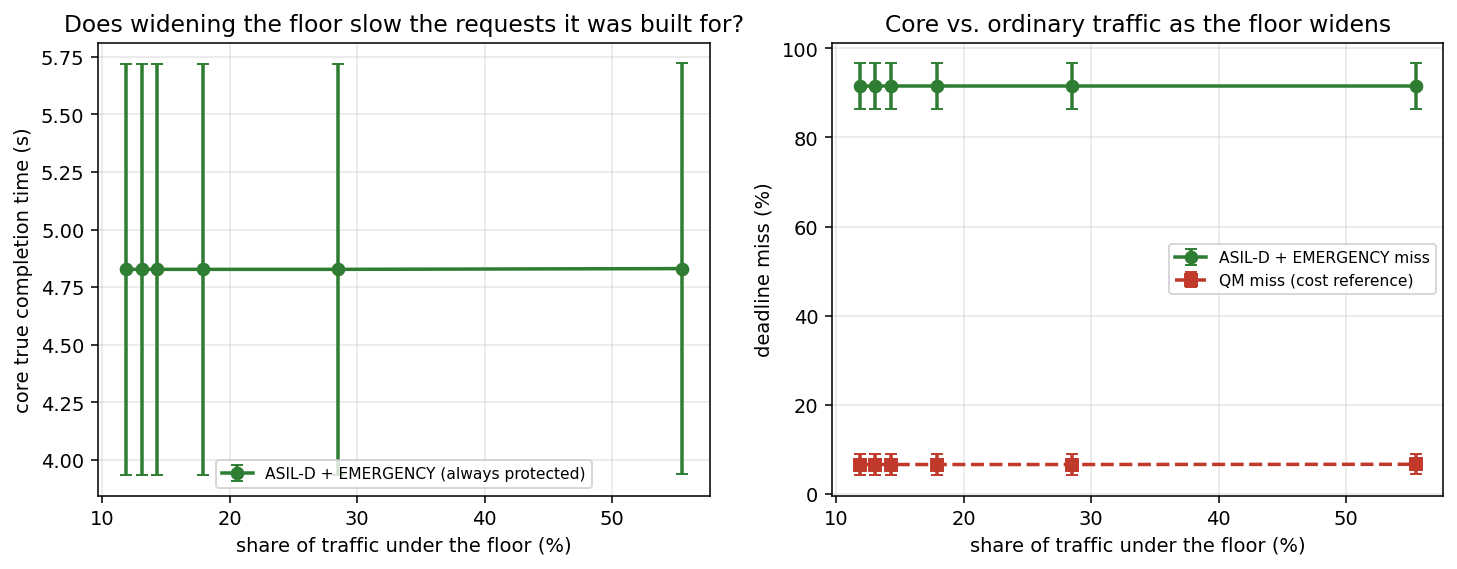

'/home/z/my-project/eptask_run/results/figures/floor_dilution.png'

In [30]:
p, N2_B = NV.n2_casualty(cfg, facB, FIGDIR, V=30, seeds=B["seeds"], label="model B",
                         fname="n2_modelB.png", **EV); show(p)
p, N2_R = NV.n2_casualty(cfg, facRand, FIGDIR, V=30, seeds=B["seeds"], label="random policy",
                         fname="n2_random.png", **EV); show(p)
p, DIL = NV.floor_dilution(cfg, FIGDIR, V=30, seeds=B["seeds"], thresholds=B["dil_thresholds"], **EV); show(p)

## 12 · Integration — the Nepal corridor (road scale)

The micro model hands its EMERGENCY-class latencies, with the floor OFF and ON, to the road
co-simulation. A blockage falls on the valley road beyond the Betrawati junction; with COOLR
data its position is weighted by mapped landslides. An ambulance leaves Bidur 10 minutes
later. The warning spreads by four routes:

* **NONE** — the ambulance sees the blockage itself;
* **V2V** — relay plus store-carry-forward;
* **RSU** — surviving roadside units with backhaul;
* **V2V+RSU** — both.

Three infrastructure scenarios are compared: local damage (2 km footprint), corridor-wide
damage (15 km), and corridor-wide damage with heavier traffic.

**How to read the result.** The info-mode gaps show what the *warning network* is worth in
minutes. The floor ON vs OFF difference (paired, per trial) shows what *scheduling* is worth
at road scale. Expect the second to be tiny: service latencies are seconds and trips take
hours. That is a finding about where the leverage is, not a failure of N1.

micro hand-off, floor OFF: n=247 emergency requests, median 2.90 s, deadline miss 83.0%
micro hand-off, floor ON: n=247 emergency requests, median 2.54 s, deadline miss 80.2%

=== local damage (2 km), 30 veh/h ===


    trial 1/20: hazard edge (107, 108), 221 civilians, RSUs alive 94%


    trial 2/20: hazard edge (116, 117), 227 civilians, RSUs alive 97%


    trial 3/20: hazard edge (103, 104), 213 civilians, RSUs alive 97%


    trial 4/20: hazard edge (150, 151), 210 civilians, RSUs alive 97%


...

    trial 16/20: hazard edge (83, 84), 239 civilians, RSUs alive 94%


    trial 17/20: hazard edge (86, 87), 254 civilians, RSUs alive 97%


    trial 18/20: hazard edge (110, 111), 221 civilians, RSUs alive 94%


    trial 19/20: hazard edge (96, 97), 217 civilians, RSUs alive 94%


    trial 20/20: hazard edge (142, 143), 207 civilians, RSUs alive 94%
    info mode | scheduling            extra vs oracle (min)  missed junction      civilians trapped
    NONE | floor OFF                    78.7 +- 15.2 (n=20)             100%   250.1 +- 12.5 (n=20)
    NONE | floor ON                     78.7 +- 15.2 (n=20)             100%   250.1 +- 12.5 (n=20)
    V2V | floor OFF                     32.9 +- 12.6 (n=20)              85%      7.3 +- 1.8 (n=20)
    V2V | floor ON                      33.0 +- 12.7 (n=20)              85%      7.3 +- 1.8 (n=20)
    RSU | floor OFF                      -0.0 +- 0.0 (n=20)               0%     10.9 +- 9.0 (n=20)
    RSU | floor ON                       -0.0 +- 0.0 (n=20)               0%     10.9 +- 9.0 (n=20)
    V2V+RSU | floor OFF                  -0.0 +- 0.0 (n=20)               0%      1.7 +- 1.0 (n=20)
    V2V+RSU | floor ON                   -0.0 +- 0.0 (n=20)               0%      1.7 +- 1.0 (n=20)
    paired arrival difference

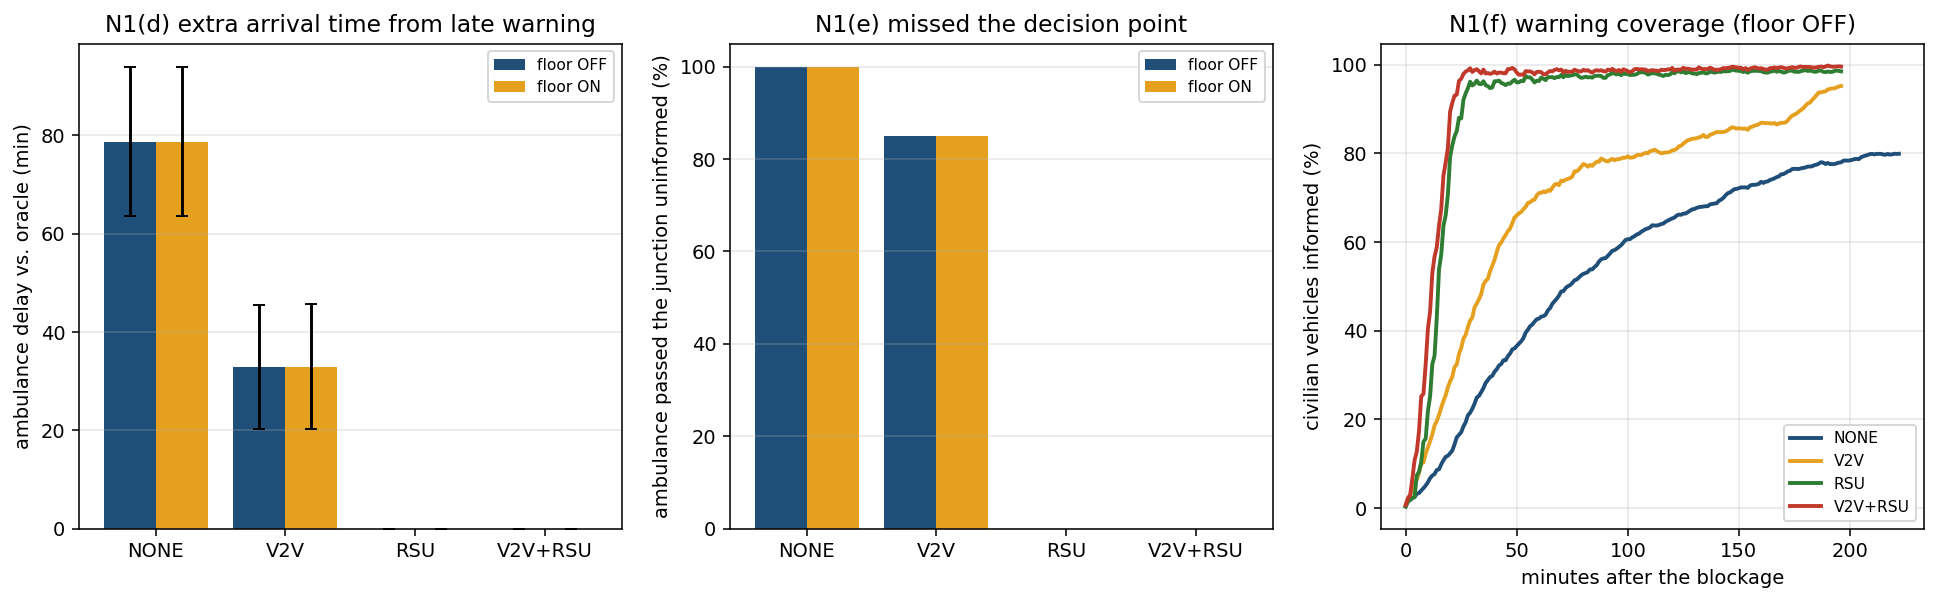


=== corridor-wide damage (15 km), 30 veh/h ===


    trial 1/20: hazard edge (116, 117), 264 civilians, RSUs alive 28%


    trial 2/20: hazard edge (74, 75), 251 civilians, RSUs alive 50%


    trial 3/20: hazard edge (98, 99), 234 civilians, RSUs alive 28%


    trial 4/20: hazard edge (145, 146), 299 civilians, RSUs alive 47%


...

    trial 16/20: hazard edge (155, 156), 294 civilians, RSUs alive 50%


    trial 17/20: hazard edge (126, 127), 277 civilians, RSUs alive 41%


    trial 18/20: hazard edge (137, 138), 235 civilians, RSUs alive 47%


    trial 19/20: hazard edge (97, 98), 251 civilians, RSUs alive 28%


    trial 20/20: hazard edge (76, 77), 250 civilians, RSUs alive 50%
    info mode | scheduling            extra vs oracle (min)  missed junction      civilians trapped
    NONE | floor OFF                    70.0 +- 17.0 (n=20)             100%   248.4 +- 17.9 (n=20)
    NONE | floor ON                     70.0 +- 17.0 (n=20)             100%   248.4 +- 17.9 (n=20)
    V2V | floor OFF                      30.7 +- 9.9 (n=20)              95%      6.4 +- 1.8 (n=20)
    V2V | floor ON                       30.6 +- 9.9 (n=20)              95%      6.4 +- 1.8 (n=20)
    RSU | floor OFF                     70.0 +- 17.0 (n=20)             100%   163.0 +- 14.2 (n=20)
    RSU | floor ON                      70.0 +- 17.0 (n=20)             100%   162.9 +- 14.2 (n=20)
    V2V+RSU | floor OFF                 30.3 +- 10.1 (n=20)              95%      5.3 +- 1.7 (n=20)
    V2V+RSU | floor ON                  30.2 +- 10.1 (n=20)              95%      5.3 +- 1.7 (n=20)
    paired arrival difference '

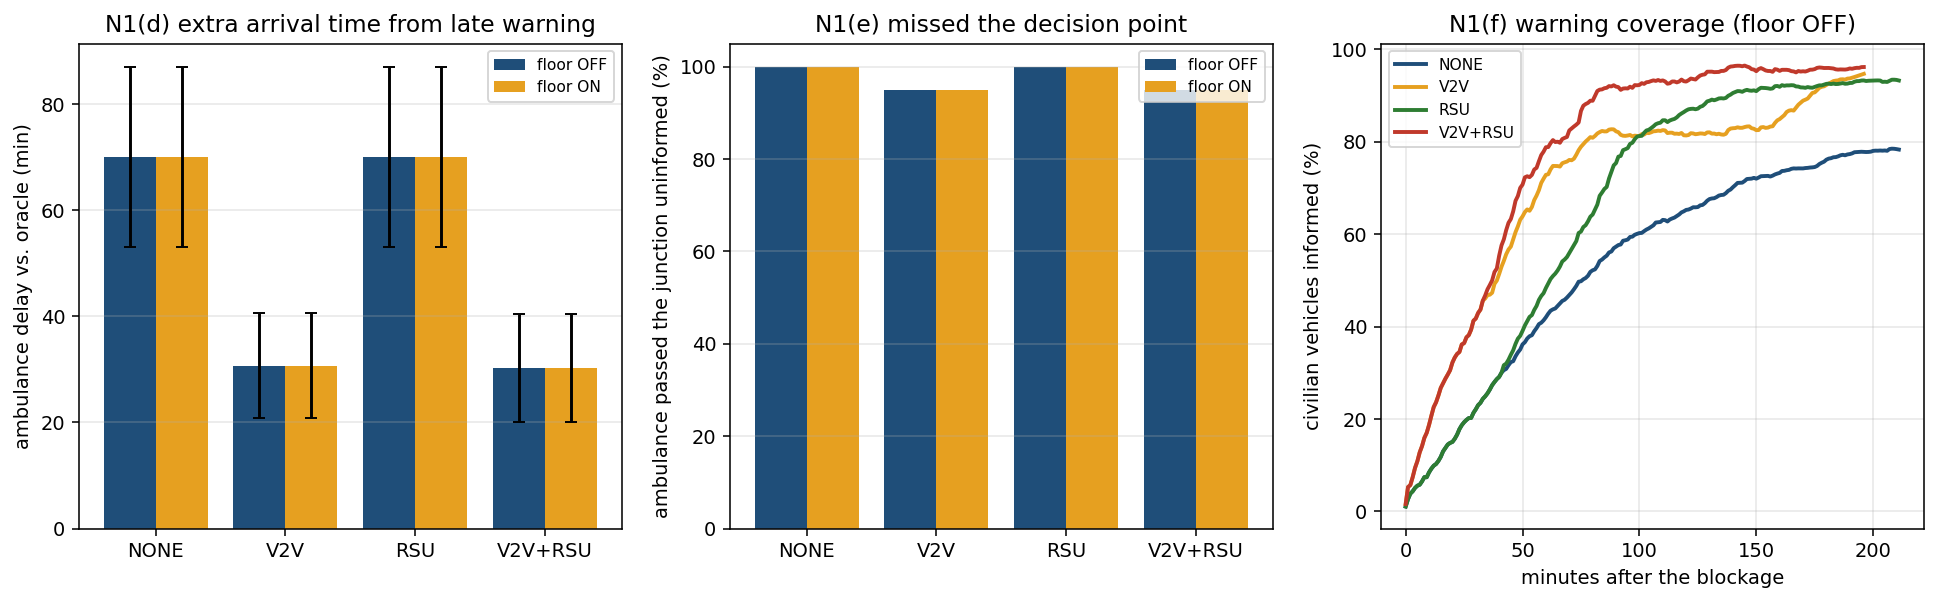


=== corridor-wide damage (15 km), 90 veh/h ===


    trial 1/20: hazard edge (90, 91), 646 civilians, RSUs alive 38%


    trial 2/20: hazard edge (132, 133), 764 civilians, RSUs alive 44%


    trial 3/20: hazard edge (137, 138), 753 civilians, RSUs alive 47%


    trial 4/20: hazard edge (118, 119), 754 civilians, RSUs alive 28%


...

    trial 16/20: hazard edge (155, 156), 833 civilians, RSUs alive 50%


    trial 17/20: hazard edge (89, 90), 708 civilians, RSUs alive 38%


    trial 18/20: hazard edge (126, 127), 634 civilians, RSUs alive 41%


    trial 19/20: hazard edge (143, 144), 638 civilians, RSUs alive 47%


    trial 20/20: hazard edge (91, 92), 665 civilians, RSUs alive 38%
    info mode | scheduling            extra vs oracle (min)  missed junction      civilians trapped
    NONE | floor OFF                    76.0 +- 17.2 (n=20)             100%   752.0 +- 42.8 (n=20)
    NONE | floor ON                     76.0 +- 17.2 (n=20)             100%   752.0 +- 42.8 (n=20)
    V2V | floor OFF                      15.6 +- 8.6 (n=20)              55%      5.0 +- 1.6 (n=20)
    V2V | floor ON                       15.6 +- 8.5 (n=20)              55%      5.0 +- 1.6 (n=20)
    RSU | floor OFF                     76.0 +- 17.2 (n=20)             100%   475.9 +- 68.0 (n=20)
    RSU | floor ON                      76.0 +- 17.2 (n=20)             100%   475.8 +- 68.1 (n=20)
    V2V+RSU | floor OFF                  15.6 +- 8.6 (n=20)              55%      3.8 +- 1.4 (n=20)
    V2V+RSU | floor ON                   15.6 +- 8.5 (n=20)              55%      3.8 +- 1.4 (n=20)
    paired arrival difference '

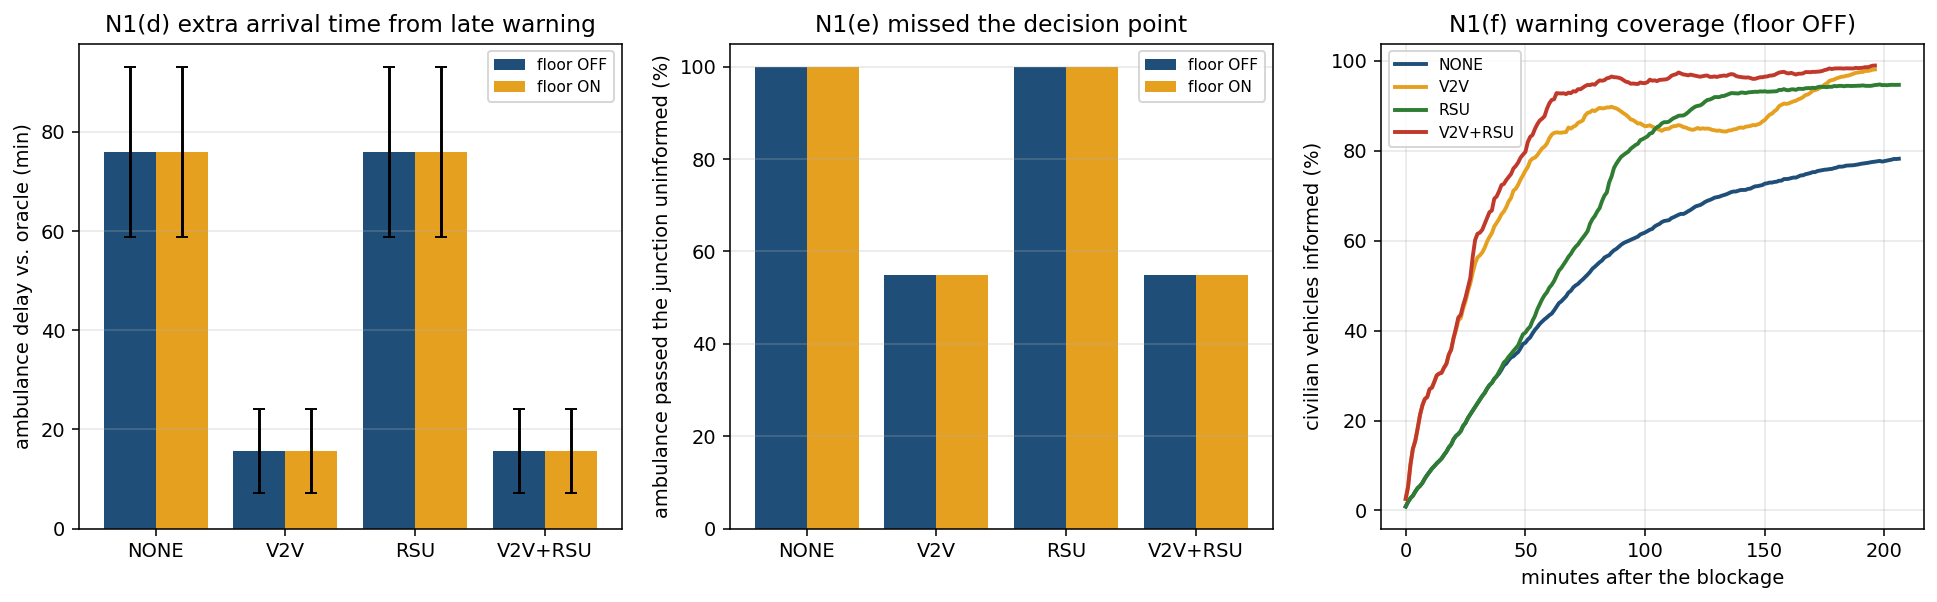

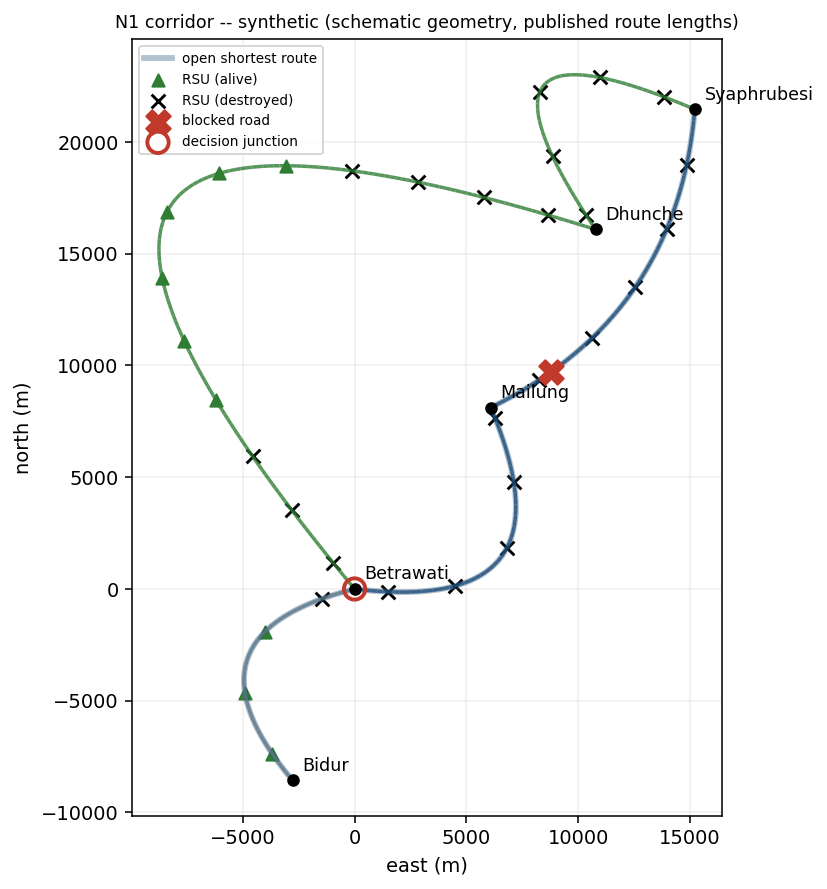

'/home/z/my-project/eptask_run/results/figures/corridor_map_hazard.png'

In [31]:
LAT = {"floor OFF": NV.latency_samples(cfg, facB, V=30, seeds=B["seeds"], floor=False, **EV),
       "floor ON": NV.latency_samples(cfg, facB, V=30, seeds=B["seeds"], floor=True, **EV)}
for k_, v in LAT.items():
    print(f"micro hand-off, {k_}: n={v['n']} emergency requests, median {v['median_T']:.2f} s, "
          f"deadline miss {v['miss_pct']:.1f}%")
SCENARIOS = {"local damage (2 km), 30 veh/h": dict(footprint_m=2000, traffic_vph=30),
             "corridor-wide damage (15 km), 30 veh/h": dict(footprint_m=15000, traffic_vph=30),
             "corridor-wide damage (15 km), 90 veh/h": dict(footprint_m=15000, traffic_vph=90)}
CORR = {}
for i, (name, prm) in enumerate(SCENARIOS.items()):
    print(f"\n=== {name} ===")
    CORR[name] = CO.run_experiment(G, LAT, trials=B["corridor_trials"], params=prm,
                                   seed0=SEED + i, coolr=COOLR_XY)
    show(CO.plot_experiment(CORR[name], FIGDIR, fname=f"n1_corridor_{i}.png"))
_s = list(SCENARIOS)[1]
show(CO.plot_map(G, FIGDIR, hazard=tuple(CORR[_s]["hazards"][0]), coolr=COOLR_XY,
                 params=SCENARIOS[_s], fname="corridor_map_hazard.png"))

## 13 · Save the results bundle (feeds the Streamlit demo)

`results/demo_bundle/` holds:

* `results_v71.json` — every number above, plus the run id, budgets, data provenance, checks
  and config;
* all figures;
* the ONNX models with their sidecars;
* the corridor graph, the micro latency samples, and the COOLR points.

Point the demo at this folder.

In [32]:
from runlog import save_json, new_run, cfg_snapshot
RUN = new_run(RUN_MODE, PKG, dict(seed=SEED, device=DEVICE, data_mode=DATA["mode"]))
BUNDLE = os.path.join(RESULTS, "demo_bundle")
for sub in ("figures", "onnx"):
    os.makedirs(os.path.join(BUNDLE, sub), exist_ok=True)
for f in os.listdir(FIGDIR):
    shutil.copy(os.path.join(FIGDIR, f), os.path.join(BUNDLE, "figures", f))
for pth in ONNX_FILES.values():
    shutil.copy(pth, os.path.join(BUNDLE, "onnx")); shutil.copy(pth + ".json", os.path.join(BUNDLE, "onnx"))
save_json(CO.graph_to_json(G), os.path.join(BUNDLE, "corridor_graph.json"))
save_json({k_: dict(T=v["T"], D=v["D"]) for k_, v in LAT.items()}, os.path.join(BUNDLE, "latency_samples.json"))
save_json(dict(points=DATA["coolr_points"]), os.path.join(BUNDLE, "coolr_points.json"))

def _corr(exp):
    return dict(summary=exp["summary"], paired=exp["paired"], params=exp["params"],
                hazards=exp["hazards"], hazard_prior=exp["hazard_prior"], analysis=exp["analysis"],
                per_trial={k_: [{kk: vv for kk, vv in r.items() if kk not in ("cov_t", "cov_f")} for r in rs]
                           for k_, rs in exp["results"].items()})
RESULTS_JSON = dict(
    run=RUN, budget=B, checks=CHECKS, corridor_graph=CORRIDOR_INFO,
    data=dict(mode=DATA["mode"], provenance=DATA["provenance"], places=DATA["places"],
              n_coolr=len(DATA["coolr_points"])),
    training=dict(A=dict(kw=A_KW, counts=A_COUNTS, episodes=B["ep_A"], minutes=histA["minutes"],
                         corr_reward_minusT=CORR_A, final_T=np.asarray(histA["T"])[-1],
                         return_curve=np.asarray(histA["return"])),
                  B=dict(kw=B_KW, counts=B_COUNTS, episodes=B["ep_B"], minutes=histB["minutes"],
                         prot_miss_curve=np.asarray(histB["prot_miss"]),
                         final_T=np.asarray(histB["T"])[-1])),
    c1=dict(v61=C1_V61, random=C1_RAND, modelA=C1_A, uplink_busy_pct=UPLINK),
    c2=dict(calm=C2_CALM, dead_zone=C2_DEAD), c3=C3, n1=N1,
    n2=dict(modelB=N2_B, random=N2_R, dilution=DIL),
    latency={k_: {kk: vv for kk, vv in v.items() if kk not in ("T", "D")} for k_, v in LAT.items()},
    corridor={k_: _corr(v) for k_, v in CORR.items()},
    onnx={k_: os.path.basename(v) for k_, v in ONNX_FILES.items()},
    figures=sorted(os.listdir(FIGDIR)), cfg=cfg_snapshot(cfg))
save_json(RESULTS_JSON, os.path.join(BUNDLE, "results_v71.json"))
print("run id   :", RUN["run_id"], "| mode:", RUN_MODE, "| data:", DATA["mode"])
print("bundle   :", BUNDLE)
print("contents :", sorted(os.listdir(BUNDLE)))

run id   : 20261008-124455-ba2667 | mode: FULL | data: roads=SYNTHETIC | hazard prior=UNIFORM
bundle   : /home/z/my-project/eptask_run/results/demo_bundle
contents : ['coolr_points.json', 'corridor_graph.json', 'figures', 'latency_samples.json', 'onnx', 'results_v71.json']


## 14 · What you can claim, what you cannot, and the limitations

**Claim, if your FULL run supports it** (cite every number from `results_v71.json`, with seeds
and CIs):

1. Two bugs in the v6.1 replication, each fixed behind a switch that reproduces v6.1 exactly:
   * the floor level was not exclusive;
   * the Local-only counterfactual was taken after commit, inflating it (measured in §2).
2. In the EPtask model, queue priority has little leverage, and the mechanism is measured, not
   assumed:
   * a request's tasks are enqueued in rank order;
   * a vehicle's uplink has almost always drained by its next request (§7d).

   This extends the replication's central finding to floors and transmission priority.
3. A single, exclusive deterministic floor with three selection rules: criticality (C1), vehicle
   role (N1) and casualty tier (N2). Its effect is measured with paired controls, and its limit
   is measured by the dilution sweep.
4. A disaster-trained policy (DR-MEPPO), compared against the static policy and an alive-aware
   rule during contiguous RSU outages (C3, N1).
5. A two-scale evaluation on the real Bidur–Betrawati–Syaphrubesi geometry. At road scale, the
   warning network (V2V / RSU) decides ambulance delay, and scheduling latency does not.

**Do not claim:** that this is the "first" anything, without engaging the prior work cited at
the top; that it would have saved lives in the Aug-2026 event; ambulance timings that did not
come from your FULL run; or ASIL certification (C1 borrows the principle only).

**Limitations to state.**

* Detection is a stochastic abstraction: there is no computer vision, acoustics or thermal physics.
* V2V uses a fixed range, with no terrain shadowing.
* There is no congestion model.
* Road speeds, RSU spacing and footprints, CWP weights and thresholds are all ASSUMPTIONS,
  labelled in `config.py` and `corridor.py`.
* The synthetic corridor's geometry is schematic. Only its route lengths are published figures.
* The model A vs B comparison holds for the budgets you trained; report the episodes.